# Практична робота №4
## Дерева рішень та ансамблі за наявності пропущених значень

Студент: Панчишин Володимир

**Мета:** Порівняти DT, RF і XGBoost з двома способами імпутації, виконати вкладену CV, Optuna та локальну інтерпретацію SHAP.

Джерело завдання: https://github.com/olehsinkevych/machine-learning

**Відтворення:** середовище Python 3.12, залежності в requirements.txt; перед запуском усієї роботи завантажте дані командою `python download_data.py`. Усі результати нижче отримуються виконанням коду, а не копіюванням готових таблиць.

In [1]:
from pathlib import Path
import sys, os
for name in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ.setdefault(name, '2')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'project' / 'common.py').is_file())
sys.path.insert(0, str(ROOT / 'project'))
import common
from IPython.display import display, Image
import pandas as pd
import json

## 1. Теоретичні пояснення та відповіді на питання

### Механізм пропусків
MCAR означає незалежність факту пропуску від спостережуваних і неспостережуваних даних; MAR допускає залежність від відомих ознак, MNAR - від самого невідомого значення. Зв’язок пропуску з класом суперечить простій моделі MCAR, але не дозволяє однозначно розрізнити MAR та MNAR. У первинному UCI файлі знак "-" є допустимою категорією not_applicable, тоді як "?" означає пропуск.

### Контроль витоку даних
Константні й повністю порожні стовпці видаляються всередині Pipeline. Імпутери й one-hot словник також навчаються в кожному train-fold. Варіант B додає індикатори для ознак із пропусками в цьому train-fold.

### Чесна оптимізація
Optuna максимізує macro-F1 у внутрішній 3-блочній CV; весь pipeline передається всередину цільової функції. Зовнішні 5 блоків оцінюють процедуру налаштування, а не одну наперед відому модель. study.best_value - максимум серед проб, тому він не є незалежною оцінкою якості. На кожну оптимізацію передбачено 30 випробувань.

### Статистичне порівняння
Варіанти A/B оцінюються на одних 15 поділах: 5 блоків × 3 повторення. Поправка Наде-Бенжіо збільшує дисперсію різниць на множник 1/n + n_test/n_train, оскільки train-fold перетинаються. Нульова гіпотеза про середню різницю перевіряється при α=0,05; це окремі дослідницькі порівняння без заяви про контроль загальної сімейної помилки.

### Важливості та SHAP
MDI може завищувати роль ознак із багатьма порогами. Permutation importance вимірює втрату якості після перестановки стовпця; корельовані ознаки можуть підміняти одна одну. SHAP пояснює окремий прогноз: сума внесків і базового значення відновлює ймовірність для DT/RF, логіт для XGBoost. Ці масштаби не можна прирівнювати.

### Дерево, випадковий ліс і бустинг
Окреме дерево жадібно обирає пороги й має високу дисперсію. Випадковий ліс усереднює дерева з bootstrap-вибірок і випадкових підмножин ознак, знижуючи їхню кореляцію та дисперсію. Бустинг послідовно зменшує втрати й зміщення, але надлишок складних дерев підвищує ризик перенавчання. XGBoost може нативно спрямовувати пропуски у вивчену гілку за замовчуванням; тут для всіх моделей навмисно застосовано однакову імпутацію.

### Optuna та різні визначення вбудованої важливості
TPE обирає проби за історією результатів, замість повного перебору сітки. Pruning не застосовано: кожна з 30 проб проходить повну внутрішню CV. fANOVA використовує той самий seed. Вбудована важливість є MDI для DT/RF та нормалізованим gain для XGBoost; ці показники мають різні визначення.

## 2. Повна реалізація

Далі міститься власна реалізація обчислень цієї роботи. Код також винесено в окремий файл `project/lab04.py`.

In [2]:
"""Практична 4: Annealing, чесна вкладена CV, Optuna та пояснення моделей.

Запуск: python project/lab04.py --number N
N обов'язково є підтвердженим номером студента, а не довільним seed.
"""

import argparse, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
    cross_val_score,
    cross_val_predict,
)
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
import optuna, shap, cloudpickle
from common import DATA, folder, savefig, dump, classification, cm_plot

NUMERIC = ["carbon", "hardness", "strength", "thick", "width", "len"]

C:\Users\11vov\Desktop\Study\TODO\courses\Machine_Learning_Panchyshyn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
class TrainColumnCleaner(TransformerMixin, BaseEstimator):
    def fit(self, x, y=None):
        self.columns_ = x.columns[x.nunique(dropna=True) > 1].tolist()
        self.removed_ = [c for c in x if c not in self.columns_]
        return self

    def transform(self, x):
        return x[self.columns_].copy()

    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns_, dtype=object)

In [4]:
def read_annealing():
    text = (DATA / "anneal.names").read_text(encoding="utf-8")
    attribute_block = text.split("7. Attribute Information:", 1)[1].split(
        "classes:", 1
    )[0]
    names = re.findall(r"^\s*\d+\. ([^:\n]+):", attribute_block, re.M)
    assert len(names) == 38, names
    frame = pd.concat(
        [
            pd.read_csv(
                DATA / name,
                header=None,
                names=names + ["class"],
                na_values="?",
                keep_default_na=False,
            )
            for name in ["anneal.data", "anneal.test"]
        ],
        ignore_index=True,
    )
    for col in names:
        if col in NUMERIC:
            frame[col] = pd.to_numeric(frame[col], errors="raise")
        else:
            frame[col] = frame[col].astype(object).where(frame[col].notna(), np.nan)
    assert len(frame) == 898 and len(names) == 38
    return frame

In [5]:
def pipeline(name, seed, indicators=True, params=None):
    params = params or {}
    if name == "DT":
        model = DecisionTreeClassifier(random_state=seed, **params)
    elif name == "RF":
        model = RandomForestClassifier(random_state=seed, n_jobs=2, **params)
    else:
        model = XGBClassifier(
            random_state=seed, n_jobs=2, eval_metric="mlogloss", **params
        )
    transforms = [
        (
            "num",
            SimpleImputer(strategy="median", keep_empty_features=True),
            make_column_selector(dtype_include="number"),
        ),
        (
            "cat",
            Pipeline(
                [
                    (
                        "impute",
                        SimpleImputer(
                            strategy="most_frequent", keep_empty_features=True
                        ),
                    ),
                    (
                        "onehot",
                        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                    ),
                ]
            ),
            make_column_selector(dtype_exclude="number"),
        ),
    ]
    if indicators:
        transforms.append(
            (
                "miss",
                MissingIndicator(features="missing-only", error_on_new=False),
                make_column_selector(),
            )
        )
    return Pipeline(
        [
            ("clean", TrainColumnCleaner()),
            ("prep", ColumnTransformer(transforms)),
            ("clf", model),
        ]
    )

In [6]:
def suggest(trial, name):
    if name == "DT":
        return {
            "max_depth": trial.suggest_int("max_depth", 2, 20),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
            "class_weight": trial.suggest_categorical(
                "class_weight", [None, "balanced"]
            ),
        }
    if name == "RF":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
            "max_depth": trial.suggest_int("max_depth", 3, 30),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
            "max_features": trial.suggest_categorical(
                "max_features", ["sqrt", "log2", 0.5]
            ),
            "class_weight": trial.suggest_categorical(
                "class_weight", [None, "balanced", "balanced_subsample"]
            ),
        }
    return {
        "n_estimators": trial.suggest_int("n_estimators", 50, 400),
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 10, log=True),
    }

In [7]:
def tune(name, x, y, seed, out, tag, trials=30):
    inner = list(
        StratifiedKFold(n_splits=3, shuffle=True, random_state=seed).split(x, y)
    )
    assert min(np.bincount(y)) >= 3

    def objective(trial):
        pipe = pipeline(name, seed, True, suggest(trial, name))
        return float(
            cross_val_score(pipe, x, y, cv=inner, scoring="f1_macro", n_jobs=1).mean()
        )

    study = optuna.create_study(
        study_name=tag,
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=seed),
        storage="sqlite:///" + (out / "optuna.sqlite3").as_posix(),
        load_if_exists=True,
    )
    remaining = max(
        0, trials - len(study.get_trials(states=[optuna.trial.TrialState.COMPLETE]))
    )
    if remaining:
        study.optimize(objective, n_trials=remaining)
    return study

In [8]:
def nadeau_bengio(a, b, ratio=0.25):
    differences = np.asarray(a) - np.asarray(b)
    mean = float(differences.mean())
    variance = float(differences.var(ddof=1))
    denominator = np.sqrt((1 / len(differences) + ratio) * variance)
    if denominator == 0:
        t = 0.0 if mean == 0 else None
        p = 1.0 if mean == 0 else 0.0
    else:
        t = float(mean / denominator)
        p = float(2 * stats.t.sf(abs(t), len(differences) - 1))
    return {
        "mean_difference": mean,
        "t": t,
        "p": p,
        "df": len(differences) - 1,
        "test_train_ratio": ratio,
        "significant_005": p < 0.05,
    }

In [9]:
def summary(scores):
    return {
        key: {
            "mean": float(np.mean(values)),
            "std": float(np.std(values, ddof=1)),
            "folds": list(map(float, values)),
        }
        for key, values in scores.items()
        if key.startswith("test_")
    }

In [10]:
def rank_plot(out, name, labels, values, xlabel):
    idx = np.argsort(values)[-15:]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(np.asarray(labels)[idx], np.asarray(values)[idx], color="#28649b")
    ax.set_xlabel(xlabel)
    return savefig(out, name)

In [11]:
def run(number):
    assert isinstance(number, int) and number > 0
    seed = 42 + number
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    out = folder(4)
    raw = read_annealing()
    x = raw.drop(columns="class")
    encoder = LabelEncoder()
    y = encoder.fit_transform(raw["class"])
    tr, te = train_test_split(
        np.arange(len(y)), test_size=0.2, stratify=y, random_state=seed
    )
    xtr = x.iloc[tr]
    xte = x.iloc[te]
    ytr = y[tr]
    yte = y[te]
    cleaner = TrainColumnCleaner().fit(xtr)
    cleaned = cleaner.transform(xtr)
    missing = cleaned.isna().mean().sort_values(ascending=False)
    association = []
    for col in missing[missing > 0].index[:5]:
        table = pd.crosstab(cleaned[col].isna(), ytr).reindex(
            [False, True], fill_value=0
        )
        chi = stats.chi2_contingency(table)
        if np.min(chi.expected_freq) < 5:
            test = stats.fisher_exact(
                table.to_numpy(),
                method=stats.MonteCarloMethod(
                    n_resamples=10000, rng=np.random.default_rng(seed)
                ),
            )
            p = float(test.pvalue)
            method = "Fisher, Monte Carlo 10000"
        else:
            p = float(chi.pvalue)
            method = "Chi-square"
        association.append(
            {
                "feature": col,
                "missing_fraction": float(missing[col]),
                "method": method,
                "p": p,
                "table": table.to_numpy().tolist(),
            }
        )
    rank_plot(
        out,
        "missingness",
        missing.index,
        missing.values * 100,
        "Пропущені значення у Train, %",
    )
    raw["class"].value_counts().sort_index().plot.barh(color="#28649b")
    plt.xlabel("Кількість виробів")
    savefig(out, "class_balance")
    cv = list(
        RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=seed).split(
            xtr, ytr
        )
    )
    scoring = {"acc": "accuracy", "f1m": "f1_macro", "bacc": "balanced_accuracy"}
    baseline = {}
    raw_scores = {}
    for flag in [False, True]:
        for name in ["DT", "RF", "XGB"]:
            key = ("B" if flag else "A") + " / " + name
            cache = out / (str(seed) + "_" + key.replace(" / ", "_") + "_baseline.json")
            if cache.exists():
                values = json.loads(cache.read_text())
            else:
                scores = cross_validate(
                    pipeline(name, seed, flag),
                    xtr,
                    ytr,
                    cv=cv,
                    scoring=scoring,
                    n_jobs=1,
                )
                values = summary(scores)
                cache.write_text(json.dumps(values), encoding="utf-8")
            baseline[key] = values
            raw_scores[key] = values["test_f1m"]["folds"]
            print("BASELINE", key, values["test_f1m"]["mean"], flush=True)
    nested = {}
    final_studies = {}
    models = {}
    best_params = {}
    outer = list(
        StratifiedKFold(n_splits=5, shuffle=True, random_state=seed).split(xtr, ytr)
    )
    for name in ["DT", "RF", "XGB"]:
        folds = []
        for fold, (a, b) in enumerate(outer):
            assert min(np.bincount(ytr[a])) >= 3
            study = tune(
                name, xtr.iloc[a], ytr[a], seed, out, f"{seed}_{name}_outer{fold}"
            )
            model = pipeline(name, seed, True, study.best_params).fit(
                xtr.iloc[a], ytr[a]
            )
            pred = model.predict(xtr.iloc[b])
            score = float(f1_score(ytr[b], pred, average="macro"))
            folds.append(score)
            print("NESTED", name, fold, score, flush=True)
        nested[name] = {
            "mean": float(np.mean(folds)),
            "std": float(np.std(folds, ddof=1)),
            "folds": folds,
        }
        study = tune(name, xtr, ytr, seed, out, f"{seed}_{name}_full")
        final_studies[name] = study
        best_params[name] = study.best_params
        nested[name]["ordinary_best_value"] = study.best_value
        models[name] = pipeline(name, seed, True, study.best_params).fit(xtr, ytr)
        with (out / (name + ".pkl")).open("wb") as file:
            cloudpickle.dump(models[name], file)
        optuna.visualization.matplotlib.plot_optimization_history(study)
        savefig(out, "optimization_" + name)
        optuna.visualization.matplotlib.plot_param_importances(
            study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=seed)
        )
        savefig(out, "parameter_importance_" + name)
    comparisons = {
        name + " A-B": nadeau_bengio(
            raw_scores["A / " + name], raw_scores["B / " + name]
        )
        for name in ["DT", "RF", "XGB"]
    }
    top = sorted(
        ["DT", "RF", "XGB"],
        key=lambda n: baseline["B / " + n]["test_f1m"]["mean"],
        reverse=True,
    )[:2]
    comparisons["B " + top[0] + "-" + top[1]] = nadeau_bengio(
        raw_scores["B / " + top[0]], raw_scores["B / " + top[1]]
    )
    # Вибір найкращої моделі за nested CV, до доступу до Test.
    winner = max(nested, key=lambda n: nested[n]["mean"])
    test_metrics = {}
    predictions = {}
    importance = {}
    for name, model in models.items():
        p = model.predict_proba(xte)
        test_metrics[name] = classification(yte, p)
        predictions[name] = p.argmax(1)
        feature_names = model[:-1].get_feature_names_out()
        mdi = model[-1].feature_importances_
        perm = permutation_importance(
            model,
            xte,
            yte,
            n_repeats=10,
            scoring="f1_macro",
            random_state=seed,
            n_jobs=1,
        )
        rank_plot(out, "mdi_" + name, feature_names, mdi, "MDI, після перетворення")
        rank_plot(
            out,
            "permutation_" + name,
            x.columns,
            perm.importances_mean,
            "Зменшення Test macro-F1 після перестановки",
        )
        importance[name] = {
            "mdi": dict(zip(feature_names, map(float, mdi))),
            "permutation_mean": dict(zip(x.columns, map(float, perm.importances_mean))),
            "permutation_std": dict(zip(x.columns, map(float, perm.importances_std))),
        }
    cm = np.array(test_metrics[winner]["confusion_matrix"])
    cm_plot(out, "confusion", cm, encoder.classes_)
    norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(6, 4.5))
    im = ax.imshow(norm, vmin=0, vmax=1, cmap="Blues")
    ax.grid(False)
    for i in range(len(cm)):
        for j in range(len(cm)):
            ax.text(
                j,
                i,
                f"{norm[i, j]:.2f}",
                ha="center",
                va="center",
                color="white" if norm[i, j] > 0.5 else "black",
            )
    ax.set(
        xticks=range(len(cm)),
        yticks=range(len(cm)),
        xticklabels=encoder.classes_,
        yticklabels=encoder.classes_,
        xlabel="Прогноз",
        ylabel="Справжній клас",
    )
    fig.colorbar(im, ax=ax)
    savefig(out, "confusion_normalized")
    mask = np.any(
        np.column_stack(list(predictions.values())) != predictions["DT"][:, None],
        axis=1,
    )
    disagreement_rows = np.flatnonzero(mask)
    explanation_source = "test"
    explain_models = models
    if len(disagreement_rows):
        position = int(disagreement_rows[0])
        sample = xte.iloc[[position]]
        truth = int(yte[position])
        original_row = int(te[position])
    else:
        # Лише out-of-fold передбачення: жодних прогнозів моделі на її Train.
        oof = list(StratifiedKFold(3, shuffle=True, random_state=seed).split(xtr, ytr))
        op = {
            name: cross_val_predict(
                pipeline(name, seed, True, best_params[name]), xtr, ytr, cv=oof
            )
            for name in models
        }
        om = np.any(np.column_stack(list(op.values())) != op["DT"][:, None], axis=1)
        positions = np.flatnonzero(om)
        assert len(positions) > 0, (
            "Жодного розходження навіть в OOF; цей факт потребує окремого пояснення."
        )
        position = int(positions[0])
        a, b = next((a, b) for a, b in oof if position in b)
        sample = xtr.iloc[[position]]
        truth = int(ytr[position])
        original_row = int(tr[position])
        explanation_source = "train OOF"
        explain_models = {
            name: pipeline(name, seed, True, best_params[name]).fit(xtr.iloc[a], ytr[a])
            for name in models
        }
    explanations = {}
    for name, model in explain_models.items():
        transformed = model[:-1].transform(sample)
        features = model[:-1].get_feature_names_out()
        clf = model[-1]
        pred = int(model.predict(sample)[0])
        explainer = shap.TreeExplainer(clf)
        values = explainer.shap_values(transformed)
        if isinstance(values, list):
            values = np.stack(values, axis=-1)
        values = np.asarray(values)[0, :, pred]
        indices = np.argsort(abs(values))[-5:]
        base = float(np.asarray(explainer.expected_value)[pred])
        output = (
            float(clf.predict(transformed, output_margin=True)[0, pred])
            if name == "XGB"
            else float(clf.predict_proba(transformed)[0, pred])
        )
        error = abs(base + values.sum() - output)
        assert error < 1e-4, (name, error)
        rank_plot(
            out,
            "shap_" + name,
            features[indices],
            values[indices],
            "SHAP: " + ("логіт" if name == "XGB" else "ймовірність"),
        )
        cleaned_sample = model.named_steps["clean"].transform(sample)
        prep = model.named_steps["prep"]
        imputed = {}
        for branch in ["num", "cat"]:
            cols = next(
                cols for label, _, cols in prep.transformers_ if label == branch
            )
            transformer = prep.named_transformers_[branch]
            imputer = (
                transformer if branch == "num" else transformer.named_steps["impute"]
            )
            for col, value in zip(cols, imputer.statistics_):
                if pd.isna(sample.iloc[0][col]):
                    imputed[col] = value
        explanations[name] = {
            "predicted_class": str(encoder.classes_[pred]),
            "probabilities": list(map(float, model.predict_proba(sample)[0])),
            "expected_value": base,
            "output": output,
            "output_scale": "logit" if name == "XGB" else "probability",
            "additivity_error": float(error),
            "top_contributions": [
                {
                    "feature": features[i],
                    "shap": float(values[i]),
                    "transformed_value": float(transformed[0, i]),
                }
                for i in indices[::-1]
            ],
            "imputed_values": imputed,
        }
    explanation = {
        "source": explanation_source,
        "original_row": original_row,
        "true_class": str(encoder.classes_[truth]),
        "raw_features": {
            k: None if pd.isna(v) else v for k, v in sample.iloc[0].items()
        },
        "models": explanations,
    }
    disagreement_table = [
        {
            "row": int(te[i]),
            "true": str(encoder.classes_[yte[i]]),
            **{name: str(encoder.classes_[predictions[name][i]]) for name in models},
        }
        for i in disagreement_rows
    ]
    pd.DataFrame(disagreement_table).to_csv(out / "disagreements.csv", index=False)
    np.savez(out / "split_indices.npz", train=tr, test=te)
    data = {
        "number": number,
        "seed": seed,
        "source": "UCI Annealing: anneal.data + anneal.test, 898 рядків",
        "shape": list(raw.shape),
        "classes": encoder.classes_.tolist(),
        "class_counts": raw["class"].value_counts().to_dict(),
        "split": {"train": len(tr), "test": len(te)},
        "train_class_counts": np.bincount(ytr).tolist(),
        "removed_train_constant_or_empty": cleaner.removed_,
        "missingness_train": missing.to_dict(),
        "missing_association": association,
        "baseline": baseline,
        "nested": nested,
        "best_params": best_params,
        "statistical_tests": comparisons,
        "winner_nested_cv": winner,
        "test": test_metrics,
        "classification_report": classification_report(
            yte,
            predictions[winner],
            target_names=encoder.classes_,
            zero_division=0,
            output_dict=True,
        ),
        "importance": importance,
        "disagreement_count": len(disagreement_rows),
        "disagreements": disagreement_table,
        "local_explanation": explanation,
        "trials_per_study": 30,
        "outer_folds": 5,
        "inner_folds": 3,
        "repeated_cv_folds": 15,
    }
    dump(out, data)
    print("LAB 4 COMPLETE", winner, test_metrics[winner]["macro_f1"], flush=True)
    return data

### Індивідуальний параметр
N є номером студента у списку групи. Його не можна замінювати довільним seed.

In [12]:
NUMBER = 20
if NUMBER is None:
    raise ValueError("Потрібен підтверджений номер студента N у списку групи")
run(NUMBER)

BASELINE A / DT 0.8827665529405321


BASELINE A / RF 0.9097895297394558


BASELINE A / XGB 0.8882971138055856


BASELINE B / DT 0.9636783985660373


BASELINE B / RF 0.9621012502383405


BASELINE B / XGB 0.9441298903462305


... (18 outputs left out)

C:\Users\11vov\AppData\Local\Temp\ipykernel_16212\3663188590.py:118: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study)


C:\Users\11vov\AppData\Local\Temp\ipykernel_16212\3663188590.py:120: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(


LAB 4 COMPLETE RF 0.9326060606060607


{'number': 20,
 'seed': 62,
 'source': 'UCI Annealing: anneal.data + anneal.test, 898 рядків',
 'shape': [898, 39],
 'classes': ['1', '2', '3', '5', 'U'],
 'class_counts': {'3': 684, '2': 99, '5': 67, 'U': 40, '1': 8},
 'split': {'train': 718, 'test': 180},
 'train_class_counts': [6, 79, 547, 54, 32],
 'removed_train_constant_or_empty': ['product-type',
  'temper_rolling',
  'non-ageing',
  'surface-finish',
  'bc',
  'bf',
  'bt',
  'bl',
  'm',
  'chrom',
  'phos',
  'cbond',
  'marvi',
  'exptl',
  'ferro',
  'corr',
  'lustre',
  'jurofm',
  's',
  'p'],
 'missingness_train': {'blue/bright/varn/clean': 0.9930362116991643,
  'packing': 0.9916434540389972,
  'enamelability': 0.9832869080779945,
  'oil': 0.9261838440111421,
  'family': 0.8593314763231198,
  'bw/me': 0.7632311977715878,
  'formability': 0.35097493036211697,
  'condition': 0.3286908077994429,
  'surface-quality': 0.266016713091922,
  'steel': 0.0947075208913649,
  'strength': 0.0,
  'carbon': 0.0,
  'hardness': 0.0,
  '

In [13]:
result_path = ROOT / 'lab_04' / 'results' / 'results.json'
R = json.loads(result_path.read_text(encoding='utf-8'))
from result_tables import tables, conclusions

## 3. Результати та їх інтерпретація

### Таблиця 1. Розміри незалежних вибірок

У таблиці 1 наведено розміри незалежних вибірок. Статистики перетворень визначено лише на тренувальній частині. Валідаційні та тестові індекси збережено окремо.

In [14]:
entry = tables(4, R)[0]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Вибірка,Спостережень
0,train,718
1,test,180


### Таблиця 2. Зв’язок пропусків із класом на Train

У таблиці 2 наведено зв’язок пропусків із класом на Train. Для малих очікуваних частот застосовано Fisher із 10000 Monte Carlo вибірками. Виявлена залежність суперечить простому MCAR, проте не розрізняє MAR та MNAR.

In [15]:
entry = tables(4, R)[1]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Ознака,"Пропуски, %",Метод,p
0,blue/bright/varn/clean,"99,30","Fisher, Monte Carlo 10000","0,002600"
1,packing,"99,16","Fisher, Monte Carlo 10000","1,000000"
2,enamelability,"98,33","Fisher, Monte Carlo 10000","0,001100"
3,oil,"92,62","Fisher, Monte Carlo 10000","0,000300"
4,family,"85,93","Fisher, Monte Carlo 10000","0,000100"


### Таблиця 3. Повторна CV: варіант A

У таблиці 3 наведено повторна CV: варіант A. Усі оцінки використовують однакові 15 поділів. SD є розкидом по залежних fold, а не довірчим інтервалом для незалежних спостережень.

In [16]:
entry = tables(4, R)[2]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Модель,Accuracy ± SD,Macro-F1 ± SD,Bal. acc. ± SD
0,DT,"0,9461 ± 0,0199","0,8828 ± 0,0895","0,8932 ± 0,0888"
1,RF,"0,9448 ± 0,0173","0,9098 ± 0,0629","0,9100 ± 0,0684"
2,XGB,"0,9485 ± 0,0174","0,8883 ± 0,0816","0,8853 ± 0,0895"


### Таблиця 4. Повторна CV: варіант B

У таблиці 4 наведено повторна CV: варіант B. Усі оцінки використовують однакові 15 поділів. SD є розкидом по залежних fold, а не довірчим інтервалом для незалежних спостережень.

In [17]:
entry = tables(4, R)[3]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Модель,Accuracy ± SD,Macro-F1 ± SD,Bal. acc. ± SD
0,DT,"0,9912 ± 0,0061","0,9637 ± 0,0542","0,9615 ± 0,0583"
1,RF,"0,9898 ± 0,0058","0,9621 ± 0,0514","0,9558 ± 0,0585"
2,XGB,"0,9861 ± 0,0064","0,9441 ± 0,0680","0,9380 ± 0,0762"


### Таблиця 5. Вкладена CV та оптимістична оцінка

У таблиці 5 наведено вкладена CV та оптимістична оцінка. Основна оцінка процедури налаштування - зовнішня CV. Best value наведено для порівняння і не використовується як незалежна оцінка якості.

In [18]:
entry = tables(4, R)[4]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Модель,Outer macro-F1,Outer SD,Best value
0,DT,"0,9585","0,0554","0,9522"
1,RF,"0,9732","0,0332","0,9660"
2,XGB,"0,9692","0,0353","0,9547"


### Таблиця 6. Найкращі гіперпараметри: DT

У таблиці 6 наведено найкращі гіперпараметри: DT. Параметри знайдено на всій Train після оцінки процедури вкладеною CV; Test у пошуку не використано.

In [19]:
entry = tables(4, R)[5]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Параметр,Значення
0,max_depth,18
1,min_samples_split,11
2,min_samples_leaf,1
3,class_weight,-


### Таблиця 7. Найкращі гіперпараметри: RF

У таблиці 7 наведено найкращі гіперпараметри: RF. Параметри знайдено на всій Train після оцінки процедури вкладеною CV; Test у пошуку не використано.

In [20]:
entry = tables(4, R)[6]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Параметр,Значення
0,n_estimators,200
1,max_depth,29
2,min_samples_leaf,1
3,max_features,sqrt
4,class_weight,-


### Таблиця 8. Найкращі гіперпараметри: XGB

У таблиці 8 наведено найкращі гіперпараметри: XGB. Параметри знайдено на всій Train після оцінки процедури вкладеною CV; Test у пошуку не використано.

In [21]:
entry = tables(4, R)[7]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Параметр,Значення
0,n_estimators,89
1,max_depth,10
2,learning_rate,"0,0822"
3,subsample,"0,7084"
4,colsample_bytree,"0,8939"
5,min_child_weight,"1,5452"


### Таблиця 9. Скоригований тест Наде-Бенжіо

У таблиці 9 наведено скоригований тест Наде-Бенжіо. Рівень окремої перевірки α=0,05. Невідхилення нульової гіпотези не означає доведену рівність моделей.

In [22]:
entry = tables(4, R)[8]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Порівняння,Середня різниця,t,p
0,DT A-B,"-0,0809","-1,9286","0,074315"
1,RF A-B,"-0,0523","-4,0546","0,001182"
2,XGB A-B,"-0,0558","-1,0267","0,321976"
3,B DT-RF,"0,0016","0,2435","0,811121"


### Таблиця 10. Фінальний Test

У таблиці 10 наведено фінальний Test. Найкращу модель обрано за вкладеною CV, не за цією таблицею. Для кожної моделі Test оцінено після фіксації гіперпараметрів.

In [23]:
entry = tables(4, R)[9]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Модель,Accuracy,Macro-F1,Bal. acc.
0,DT,"0,9833","0,9145","0,8971"
1,RF,"0,9944","0,9326","0,9000"
2,XGB,"0,9833","0,7929","0,7985"


### Таблиця 11. Classification report вибраної моделі

У таблиці 11 наведено classification report вибраної моделі. Ці оцінки показують якість кожного класу окремо. Для рідкісного класу мала тестова підтримка робить метрику особливо нестійкою.

In [24]:
entry = tables(4, R)[10]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Клас,Precision,Recall,F1,Support
0,1,"1,0000","0,5000","0,6667",2
1,2,"1,0000","1,0000","1,0000",20
2,3,"0,9928","1,0000","0,9964",137
3,5,"1,0000","1,0000","1,0000",13
4,U,"1,0000","1,0000","1,0000",8


### Таблиця 12. Об’єкти розбіжності

У таблиці 12 наведено об’єкти розбіжності. У Test знайдено 3 об’єктів розбіжності. Повний список міститься у disagreements.csv; тут наведено не більш як 15.

In [25]:
entry = tables(4, R)[11]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Рядок,Клас,DT,RF,XGB
0,585,3,2,3,2
1,356,3,U,3,3
2,188,1,1,1,3


### Таблиця 13. Початкові значення пояснюваного об’єкта

У таблиці 13 наведено початкові значення пояснюваного об’єкта. Об’єкт вибрано з test; індекс рядка з нуля 585, справжній клас 3. Це значення до імпутації.

In [26]:
entry = tables(4, R)[12]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Ознака,Значення
0,family,ПРОПУСК
1,product-type,C
2,steel,ПРОПУСК
3,carbon,0
4,hardness,0
5,temper_rolling,T
6,condition,S
7,formability,"2,0000"
8,strength,0
9,non-ageing,ПРОПУСК


### Таблиця 14. Заповнення пропусків пояснюваного об’єкта

У таблиці 14 наведено заповнення пропусків пояснюваного об’єкта. Значення імпутації обчислені на Train відповідної моделі. «Вилучено» означає константну або повністю порожню ознаку, яку прибрав навчальний трансформер.

In [27]:
entry = tables(4, R)[13]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Ознака,DT,RF,XGB
0,blue/bright/varn/clean,B,B,B
1,bw/me,B,B,B
2,enamelability,"2,0000","2,0000","2,0000"
3,family,TN,TN,TN
4,oil,Y,Y,Y
5,packing,"3,0000","3,0000","3,0000"
6,steel,A,A,A
7,surface-quality,E,E,E


### Таблиця 15. Ймовірності класів пояснюваного об’єкта

У таблиці 15 наведено ймовірності класів пояснюваного об’єкта. Порівняння ймовірностей допомагає відрізнити невпевнені прогнози поблизу межі класів від жорсткого рішення окремого дерева.

In [28]:
entry = tables(4, R)[14]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Клас,DT,RF,XGB
0,1,"0,0000","0,0000","0,0179"
1,2,"1,0000","0,3550","0,4631"
2,3,"0,0000","0,5550","0,4100"
3,5,"0,0000","0,0900","0,0290"
4,U,"0,0000","0,0000","0,0800"


### Таблиця 16. П’ять головних SHAP-внесків: DT

У таблиці 16 наведено п’ять головних SHAP-внесків: DT. Прогнозований клас 2; масштаб probability. Похибка відновлення суми внесків 3.33e-16.

In [29]:
entry = tables(4, R)[15]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Перетворена ознака,Значення,SHAP
0,miss__missingindicator_surface-quality,"1,0000","0,4804"
1,num__carbon,"0,0000","0,1896"
2,miss__missingindicator_family,"1,0000","0,1467"
3,cat__enamelability_2.0,"1,0000","0,0284"
4,cat__steel_S,"0,0000","0,0268"


### Таблиця 17. П’ять головних SHAP-внесків: RF

У таблиці 17 наведено п’ять головних SHAP-внесків: RF. Прогнозований клас 3; масштаб probability. Похибка відновлення суми внесків 3.33e-16.

In [30]:
entry = tables(4, R)[16]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Перетворена ознака,Значення,SHAP
0,miss__missingindicator_surface-quality,"1,0000","-0,3083"
1,num__thick,"3,2000","-0,0402"
2,cat__steel_R,"0,0000","0,0339"
3,miss__missingindicator_family,"1,0000","0,0312"
4,cat__steel_A,"1,0000","0,0293"


### Таблиця 18. П’ять головних SHAP-внесків: XGB

У таблиці 18 наведено п’ять головних SHAP-внесків: XGB. Прогнозований клас 2; масштаб logit. Похибка відновлення суми внесків 1.42e-07.

In [31]:
entry = tables(4, R)[17]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Перетворена ознака,Значення,SHAP
0,miss__missingindicator_surface-quality,"1,0000","0,9704"
1,cat__steel_R,"0,0000","-0,6097"
2,cat__steel_A,"1,0000","-0,5231"
3,num__len,"0,0000","-0,3691"
4,num__thick,"3,2000","0,2697"


## 4. Графіки

### Рисунок 1. Розподіл класів Annealing

На рисунку 1 зображено розподіл класів Annealing. Один клас домінує, а клас 1 має лише вісім прикладів у всіх даних. Саме тому основною метрикою обрано macro-F1.

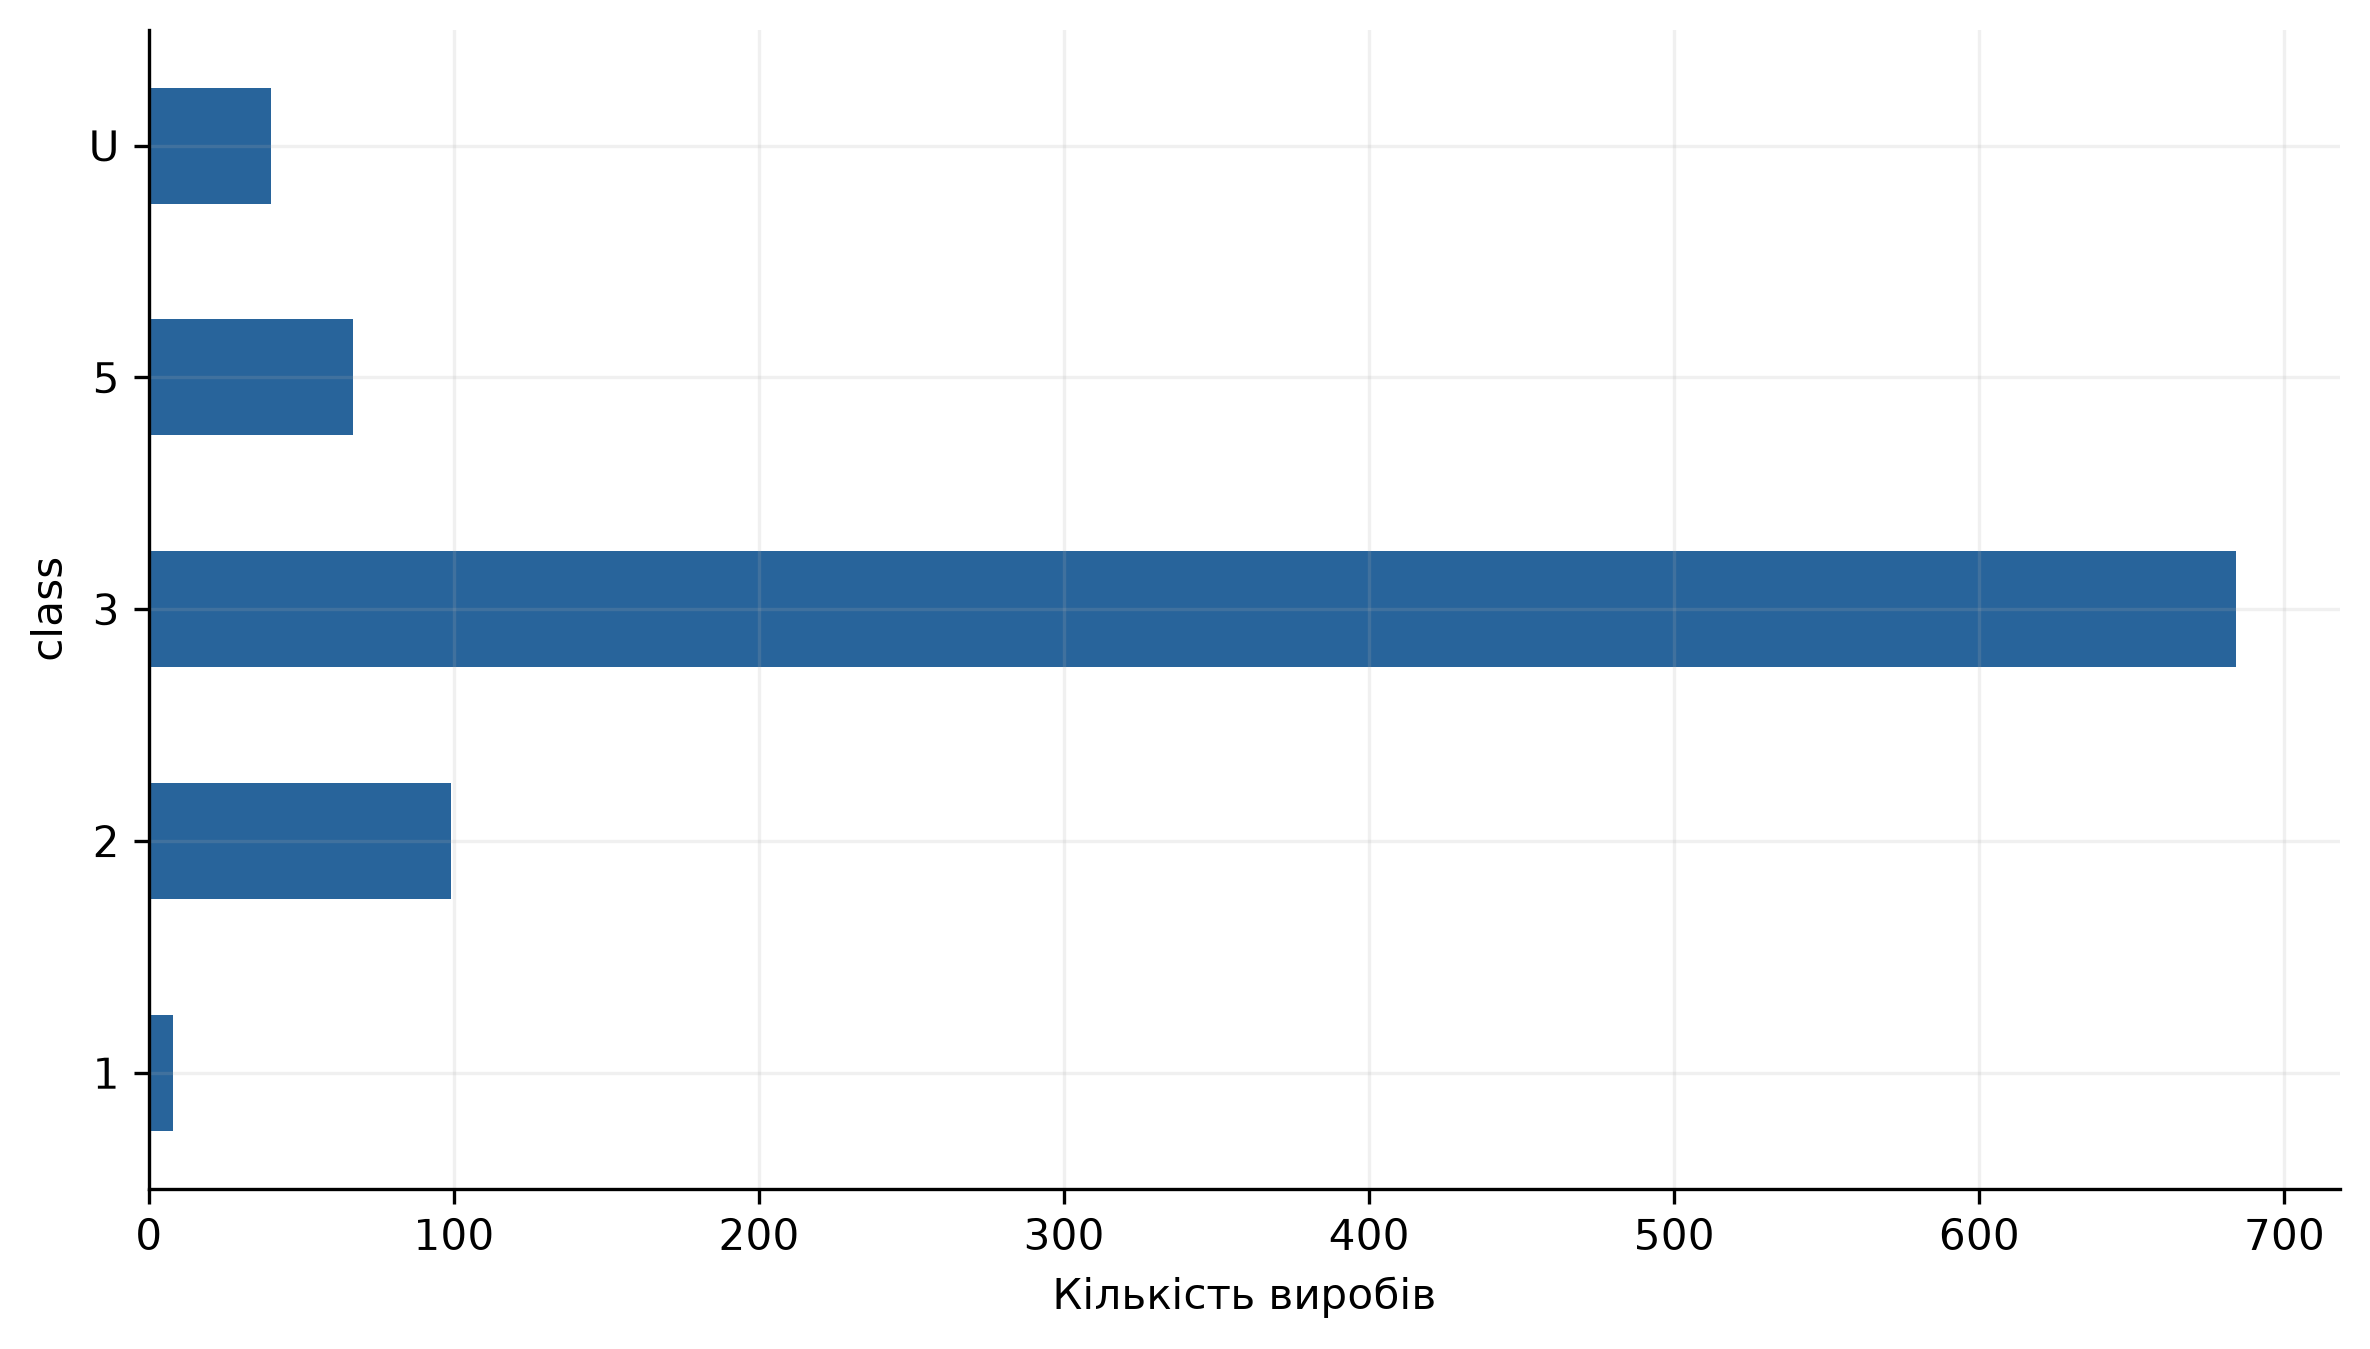

In [32]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'class_balance.png')))

### Рисунок 2. Частки пропущених значень на Train

На рисунку 2 зображено частки пропущених значень на Train. Повністю порожні й константні ознаки вилучаються всередині навчального pipeline. Структурну категорію "-" збережено.

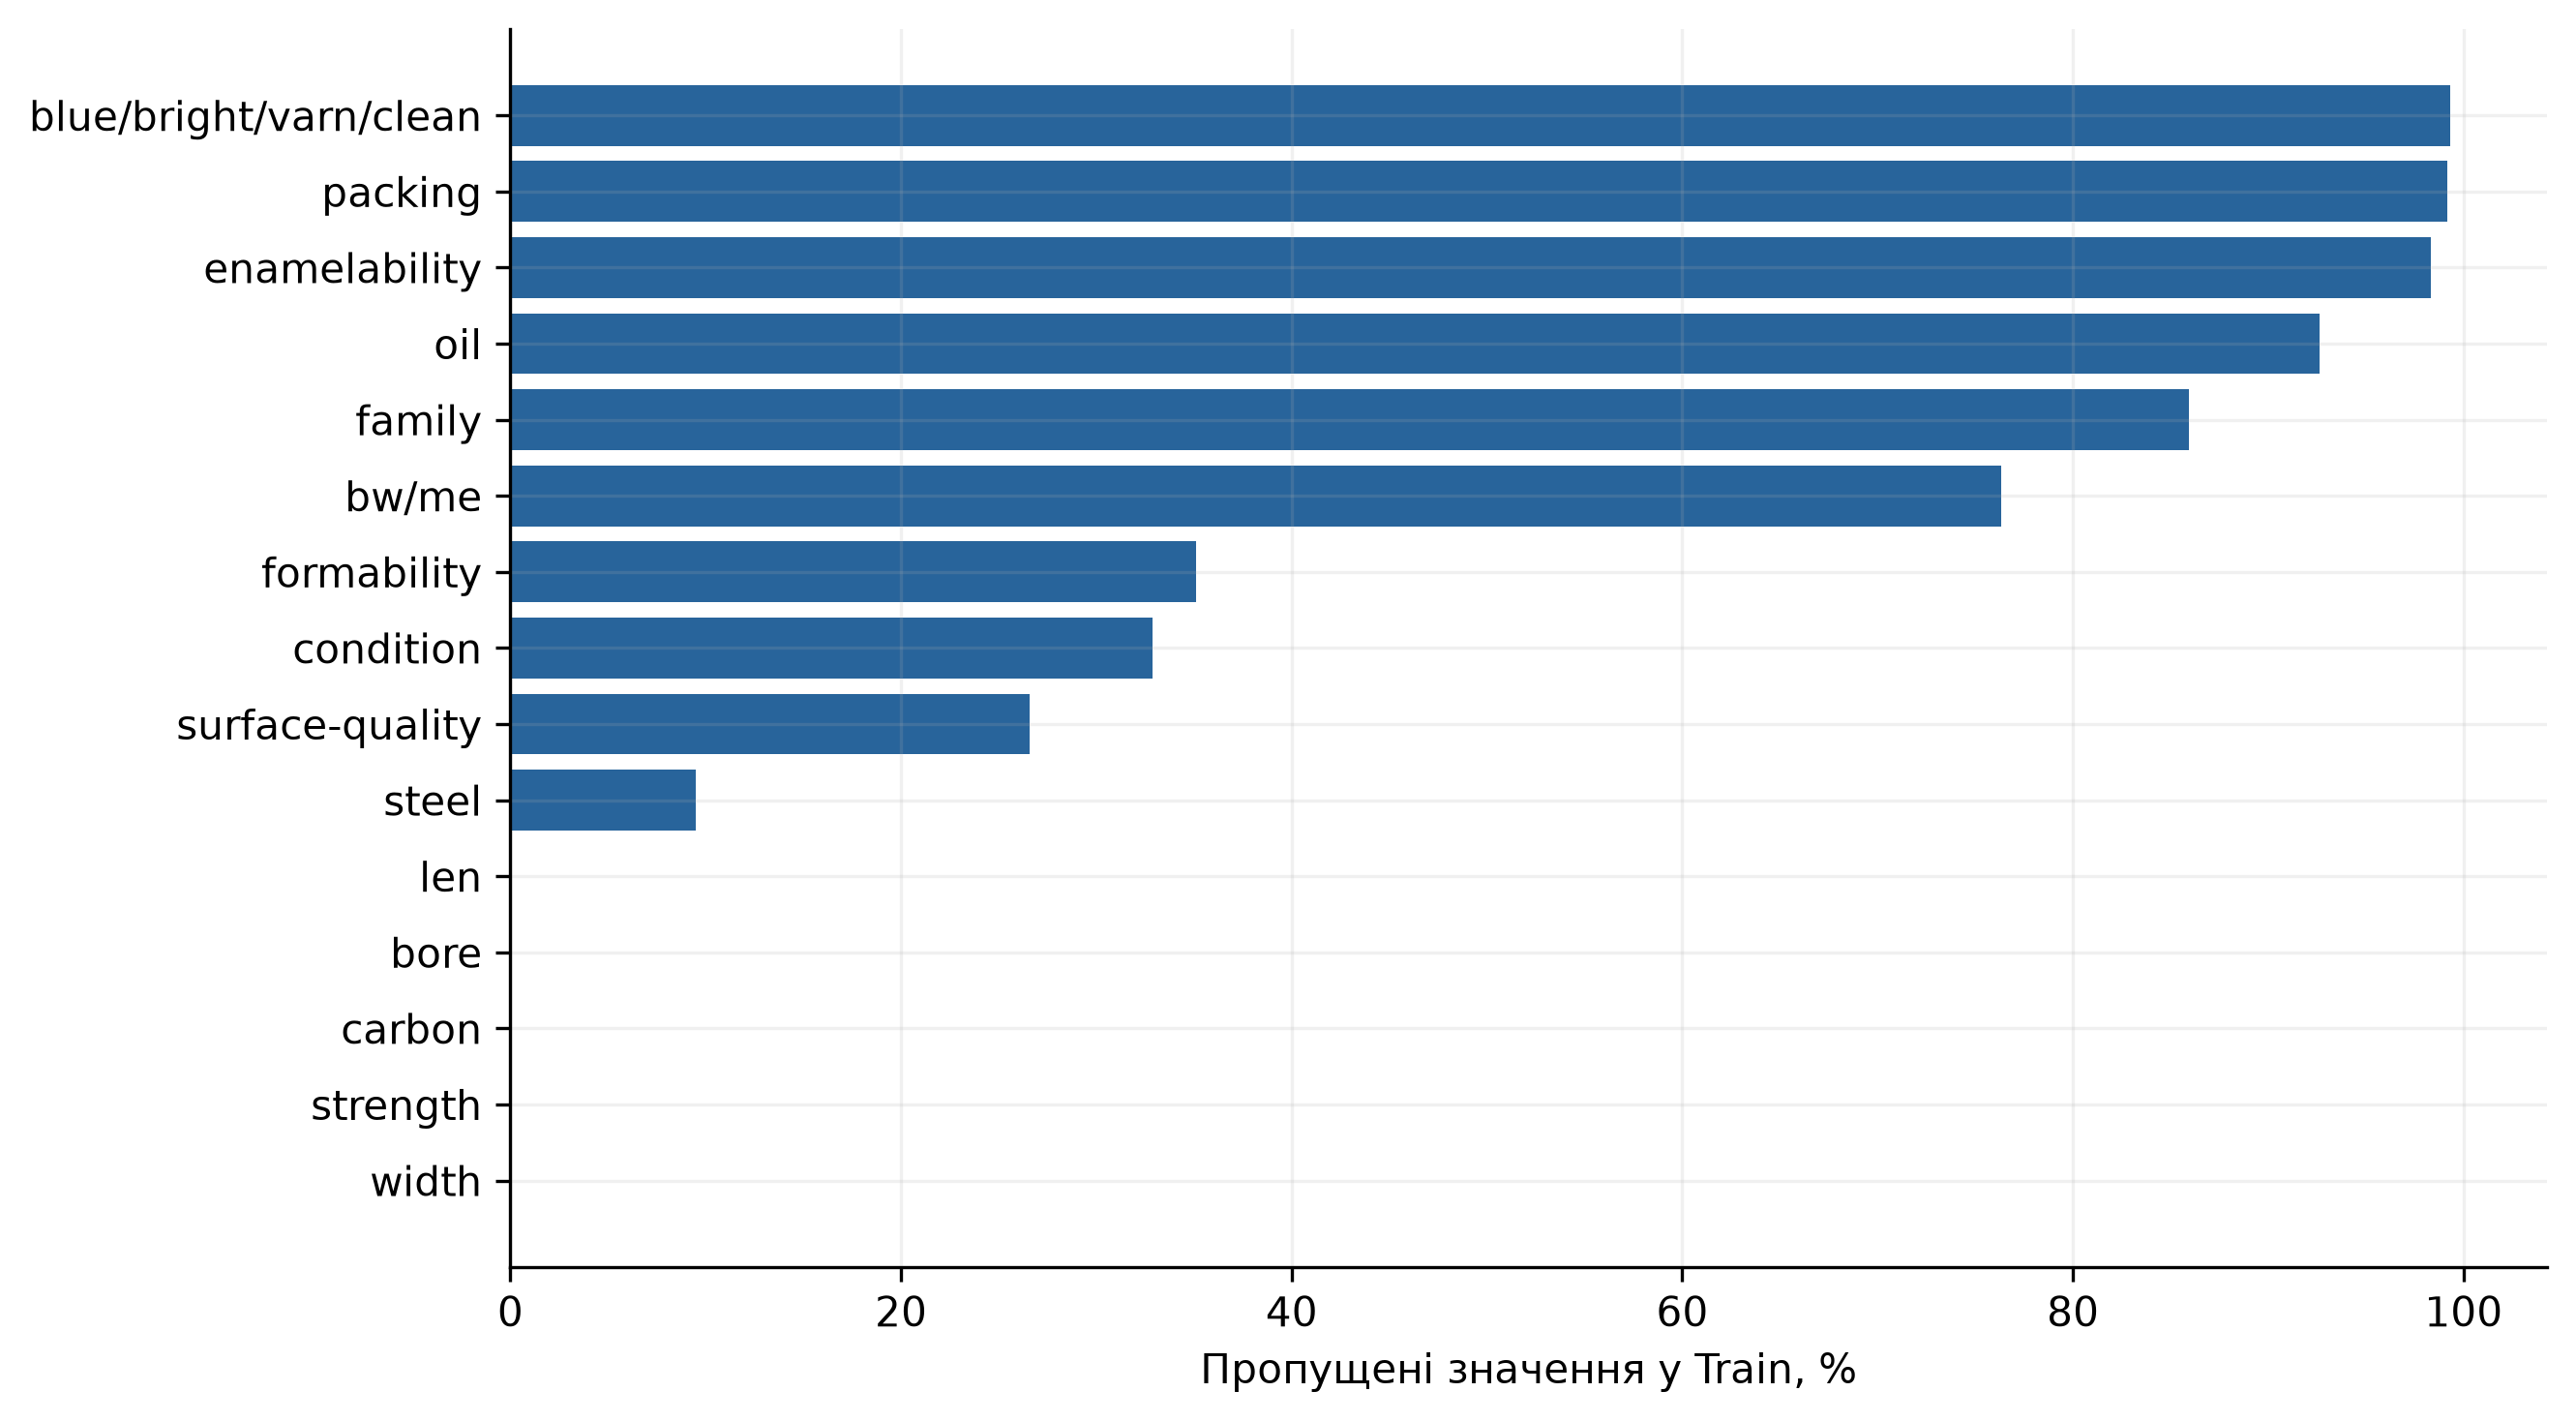

In [33]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'missingness.png')))

### Рисунок 3. Історія Optuna: DT

На рисунку 3 зображено історія Optuna: DT. Параметри й оцінки одержані без використання Test для налаштування.

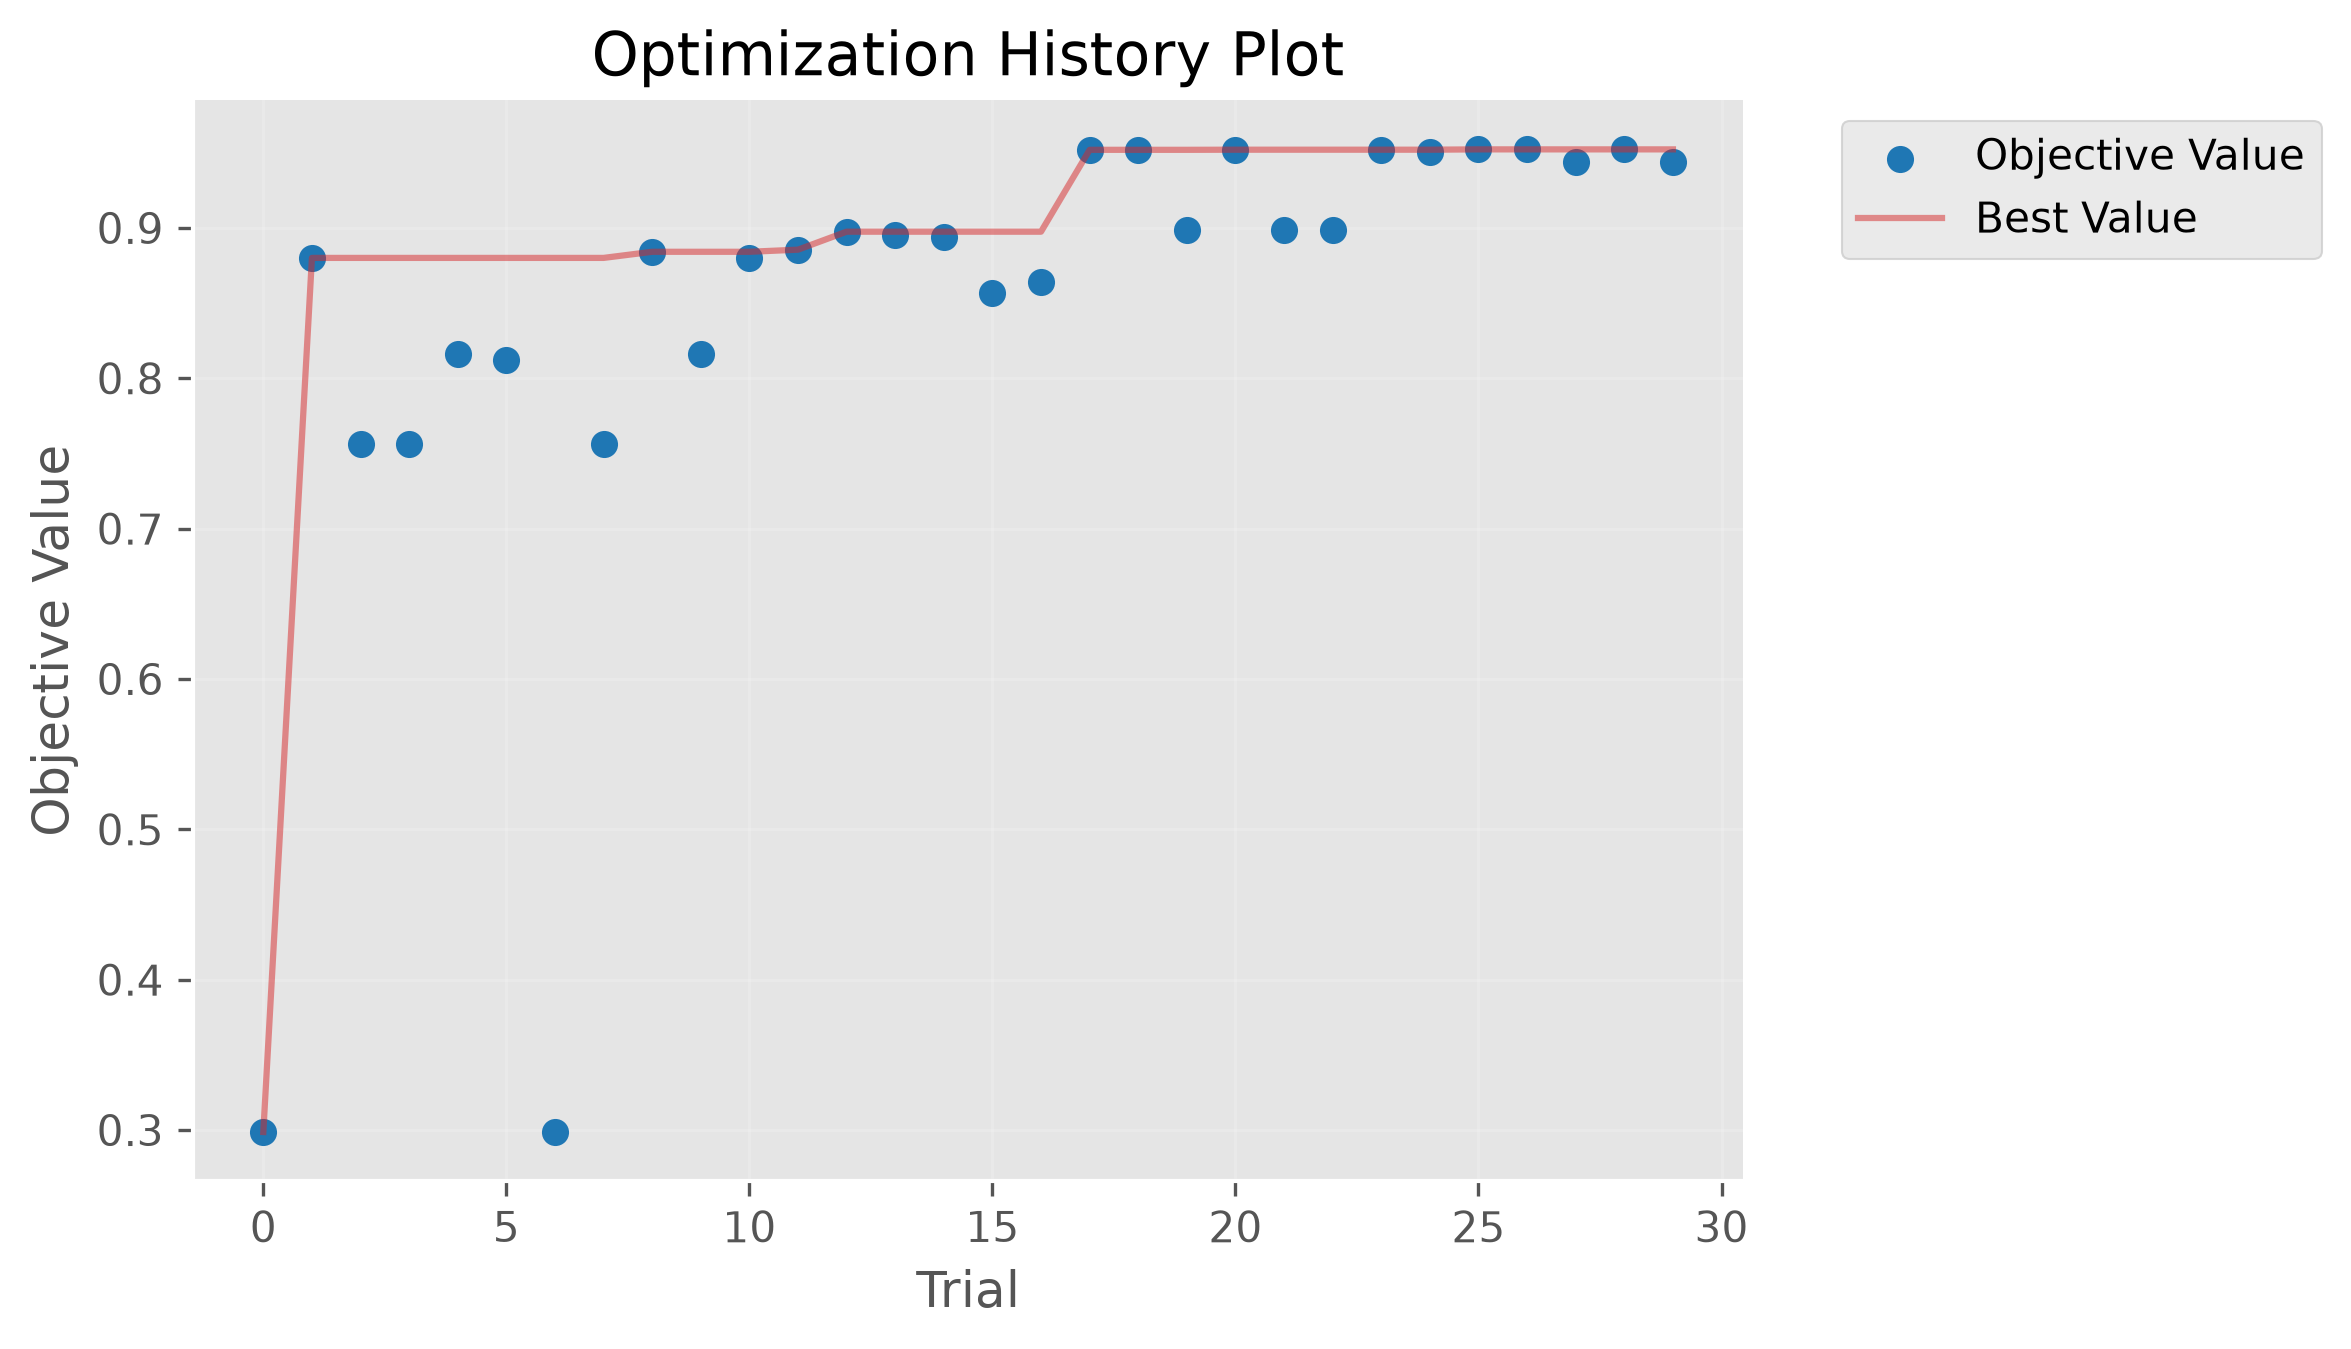

In [34]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'optimization_DT.png')))

### Рисунок 4. Важливість гіперпараметрів: DT

На рисунку 4 зображено важливість гіперпараметрів: DT. Параметри й оцінки одержані без використання Test для налаштування.

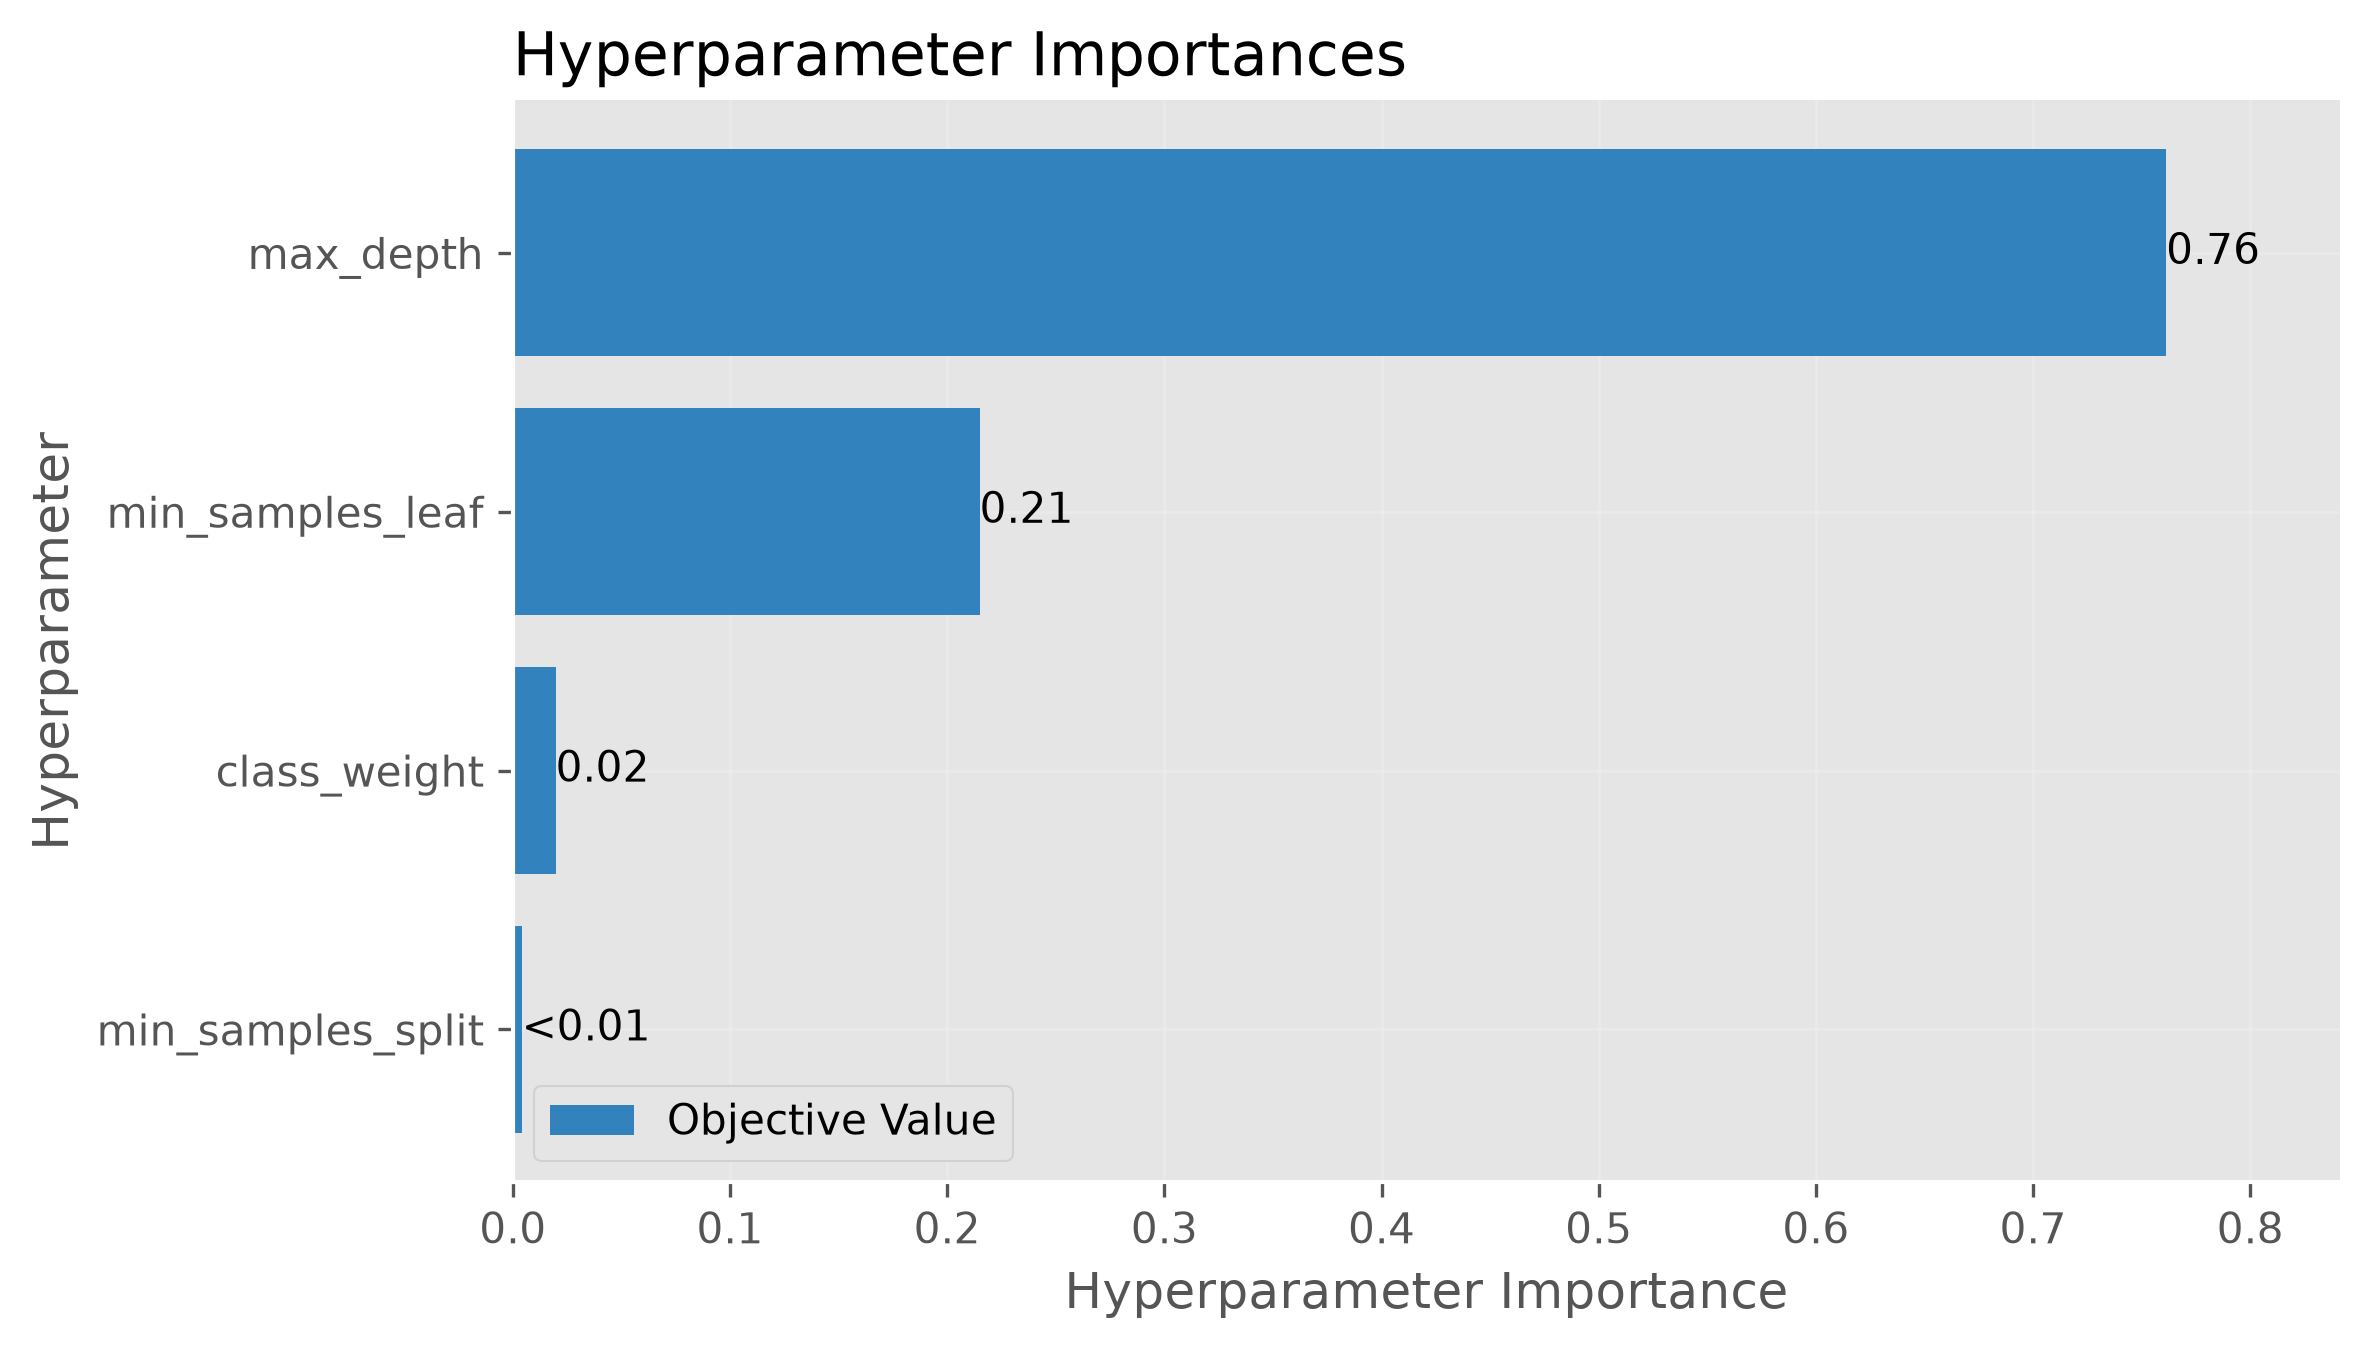

In [35]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'parameter_importance_DT.png')))

### Рисунок 5. MDI важливості: DT

На рисунку 5 зображено mDI важливості: DT. Параметри й оцінки одержані без використання Test для налаштування.

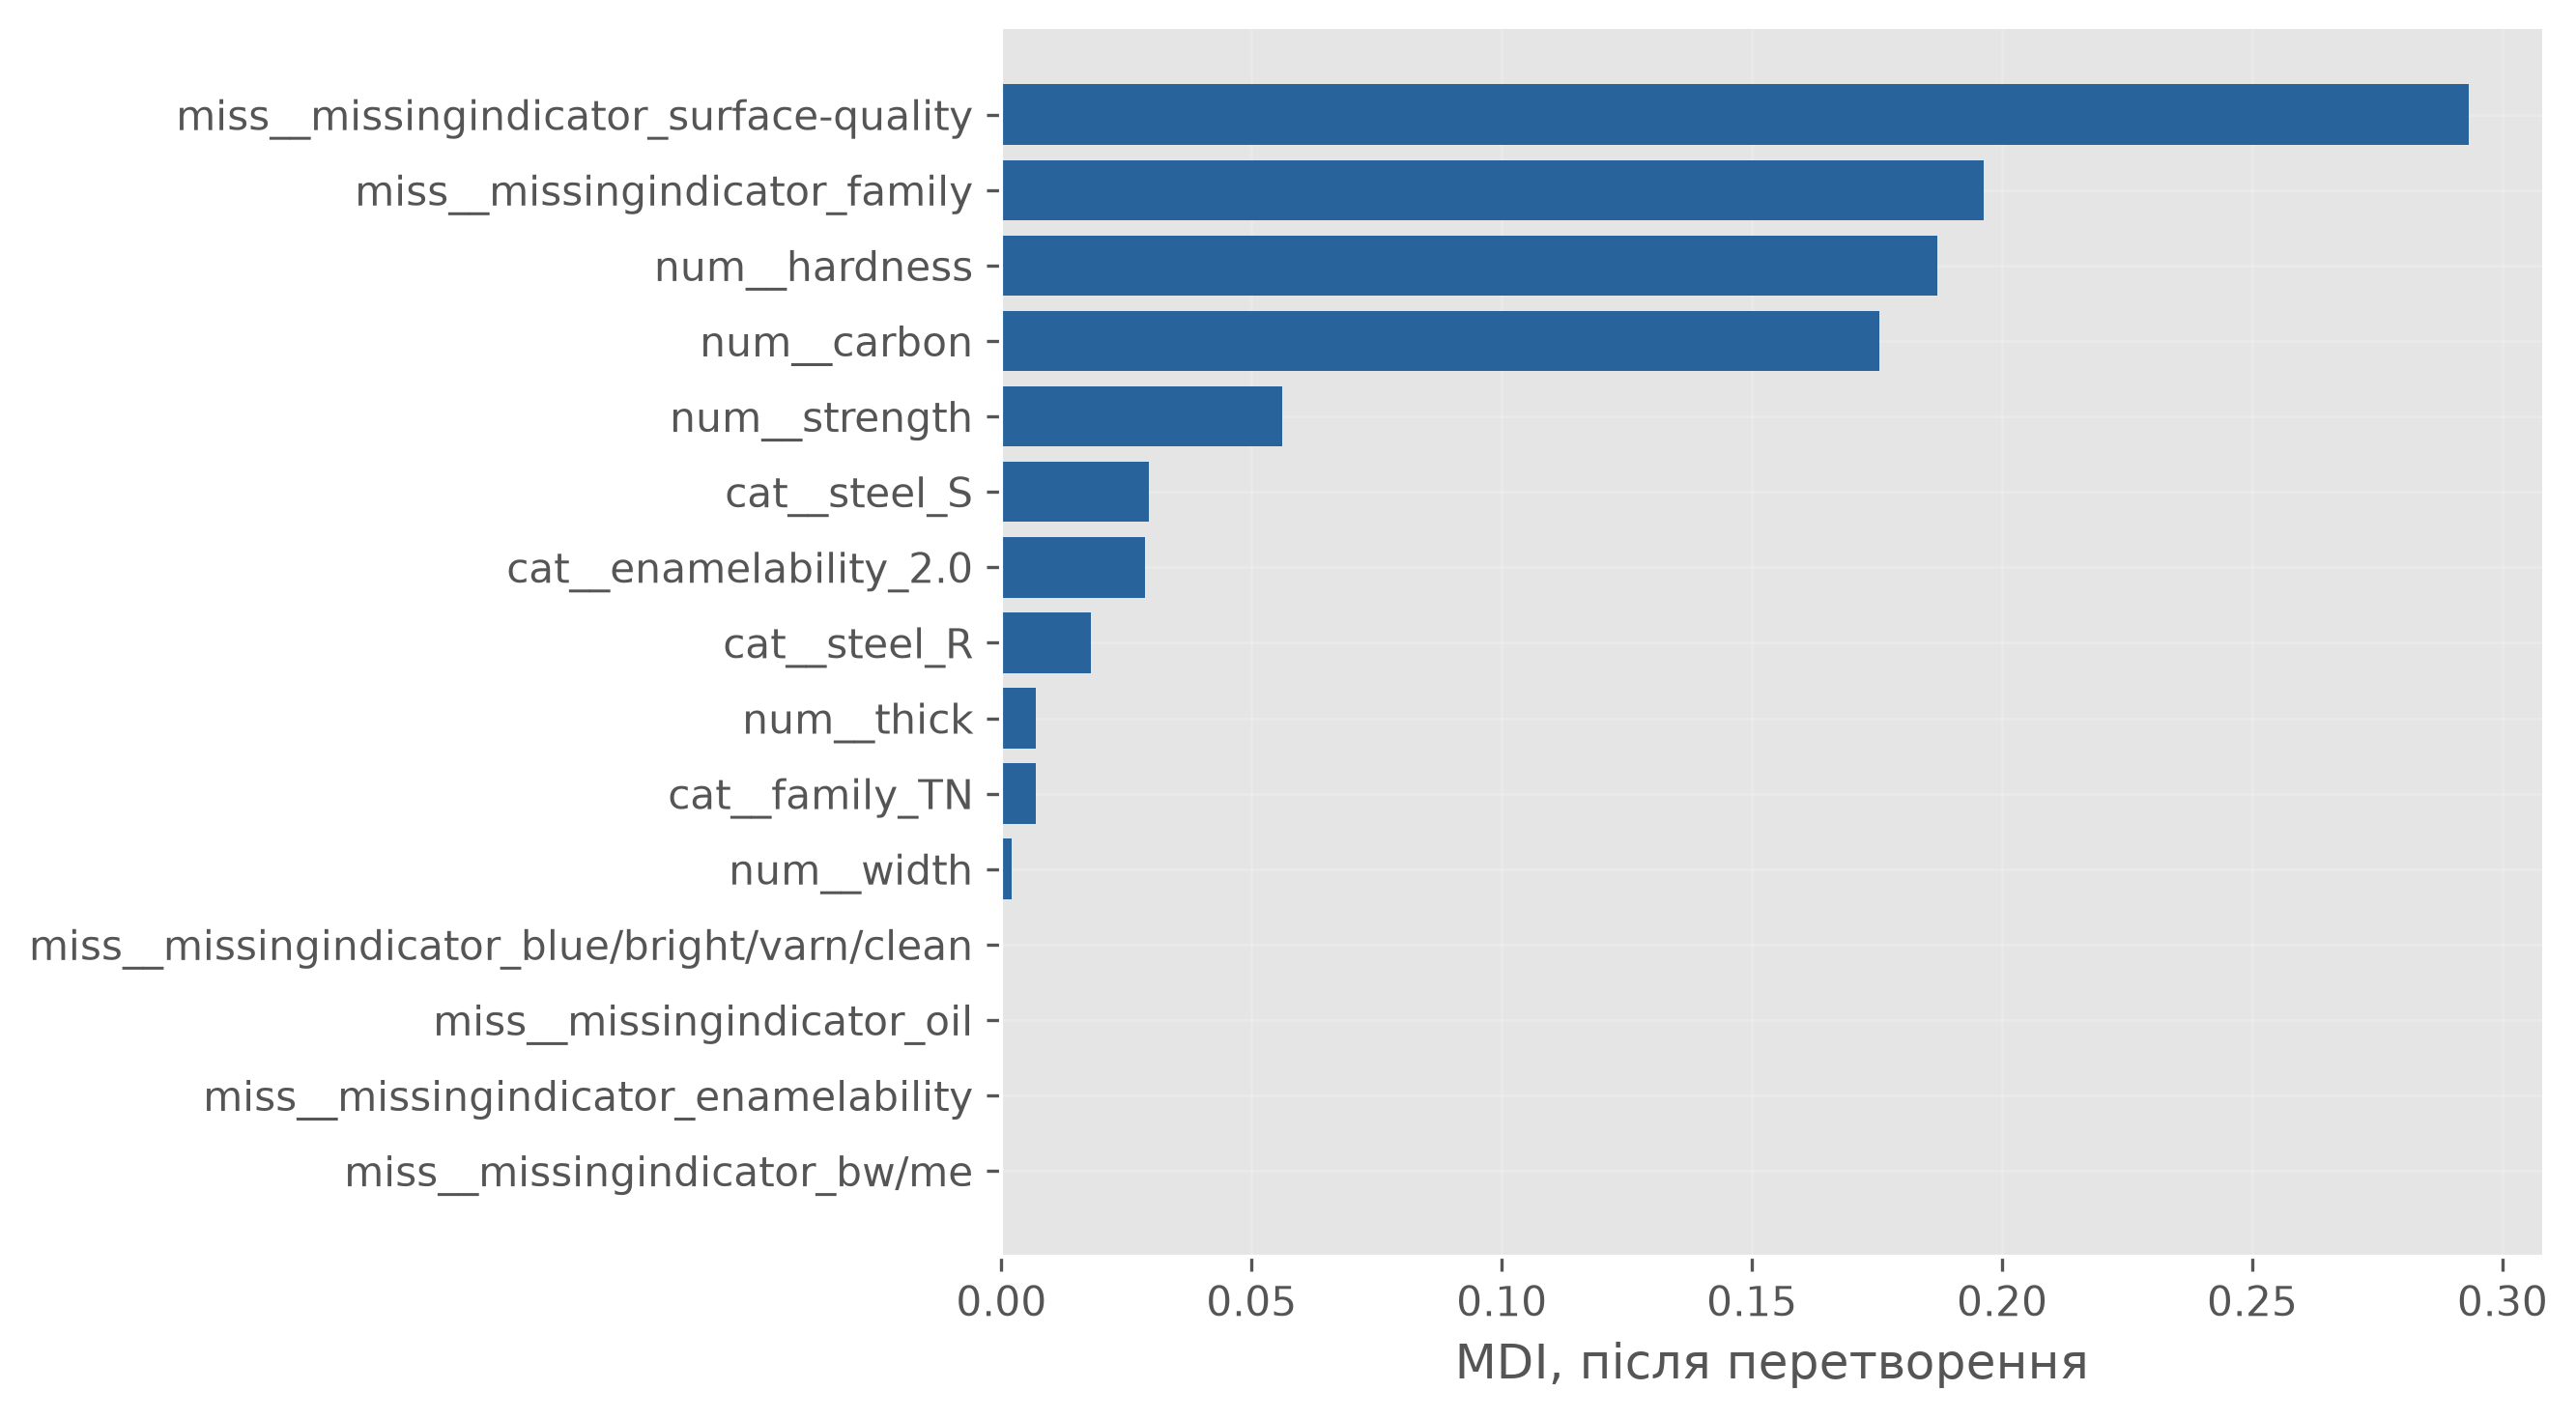

In [36]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'mdi_DT.png')))

### Рисунок 6. Permutation importance: DT

На рисунку 6 зображено permutation importance: DT. Параметри й оцінки одержані без використання Test для налаштування.

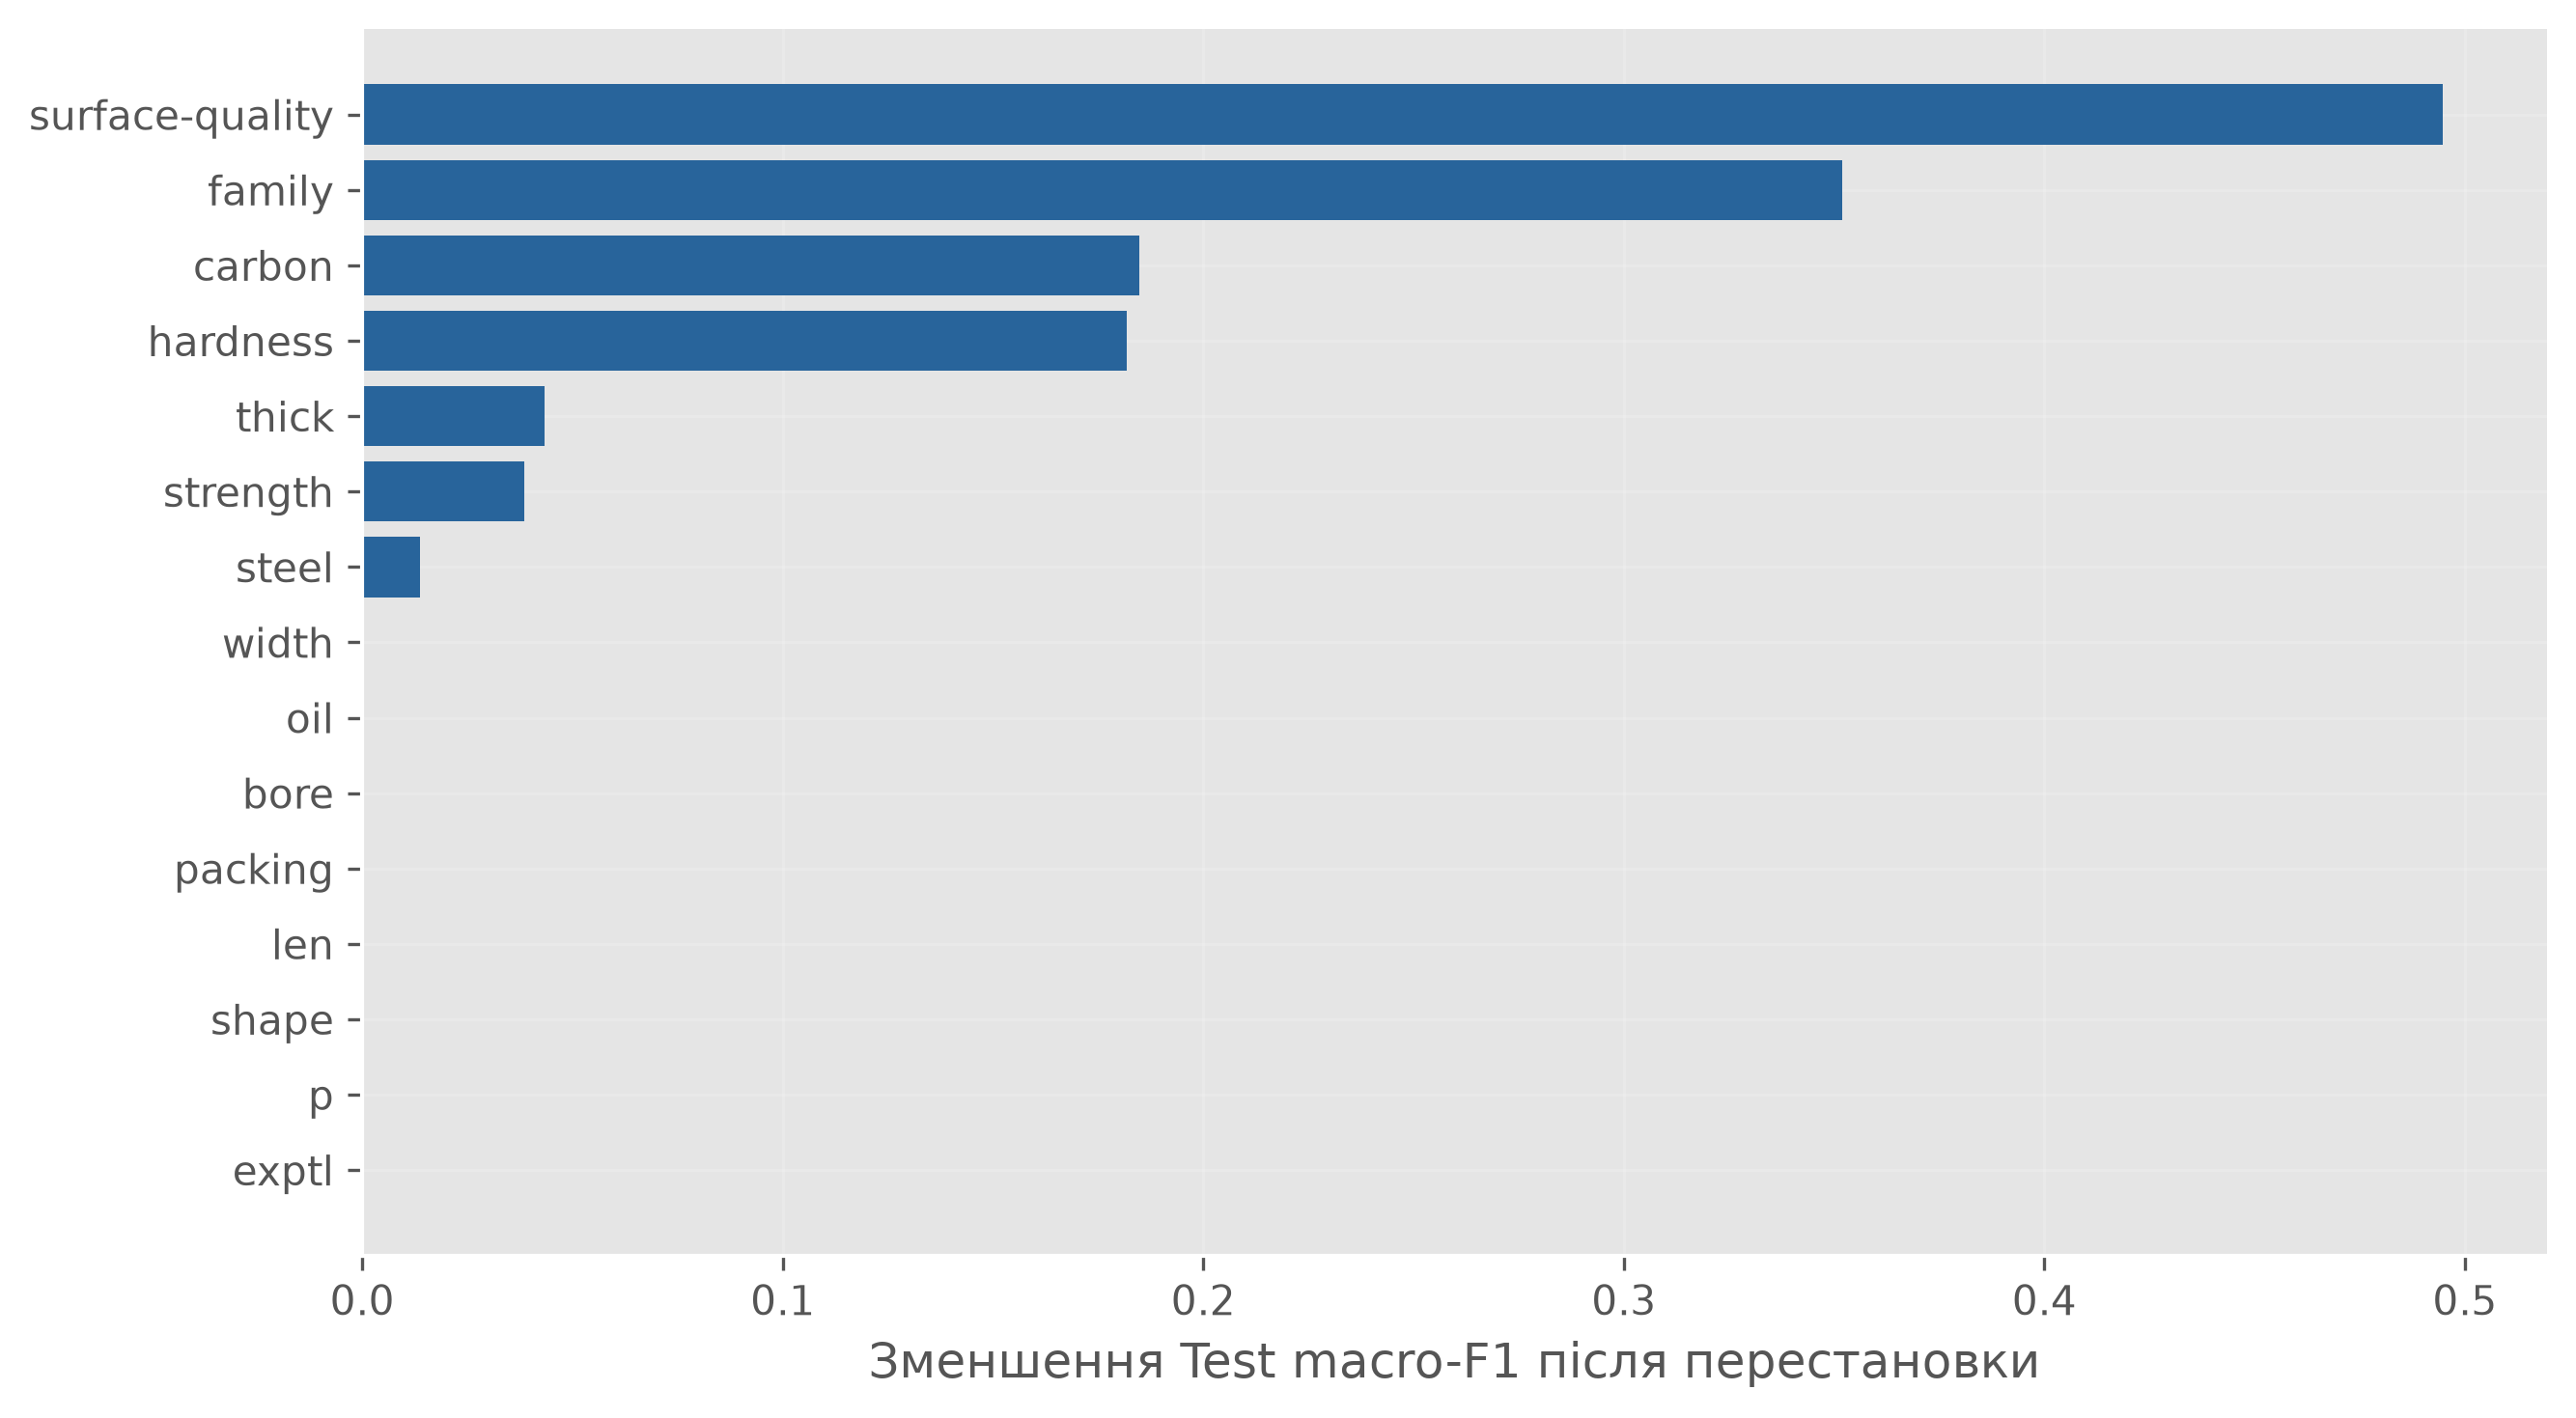

In [37]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'permutation_DT.png')))

### Рисунок 7. Історія Optuna: RF

На рисунку 7 зображено історія Optuna: RF. Параметри й оцінки одержані без використання Test для налаштування.

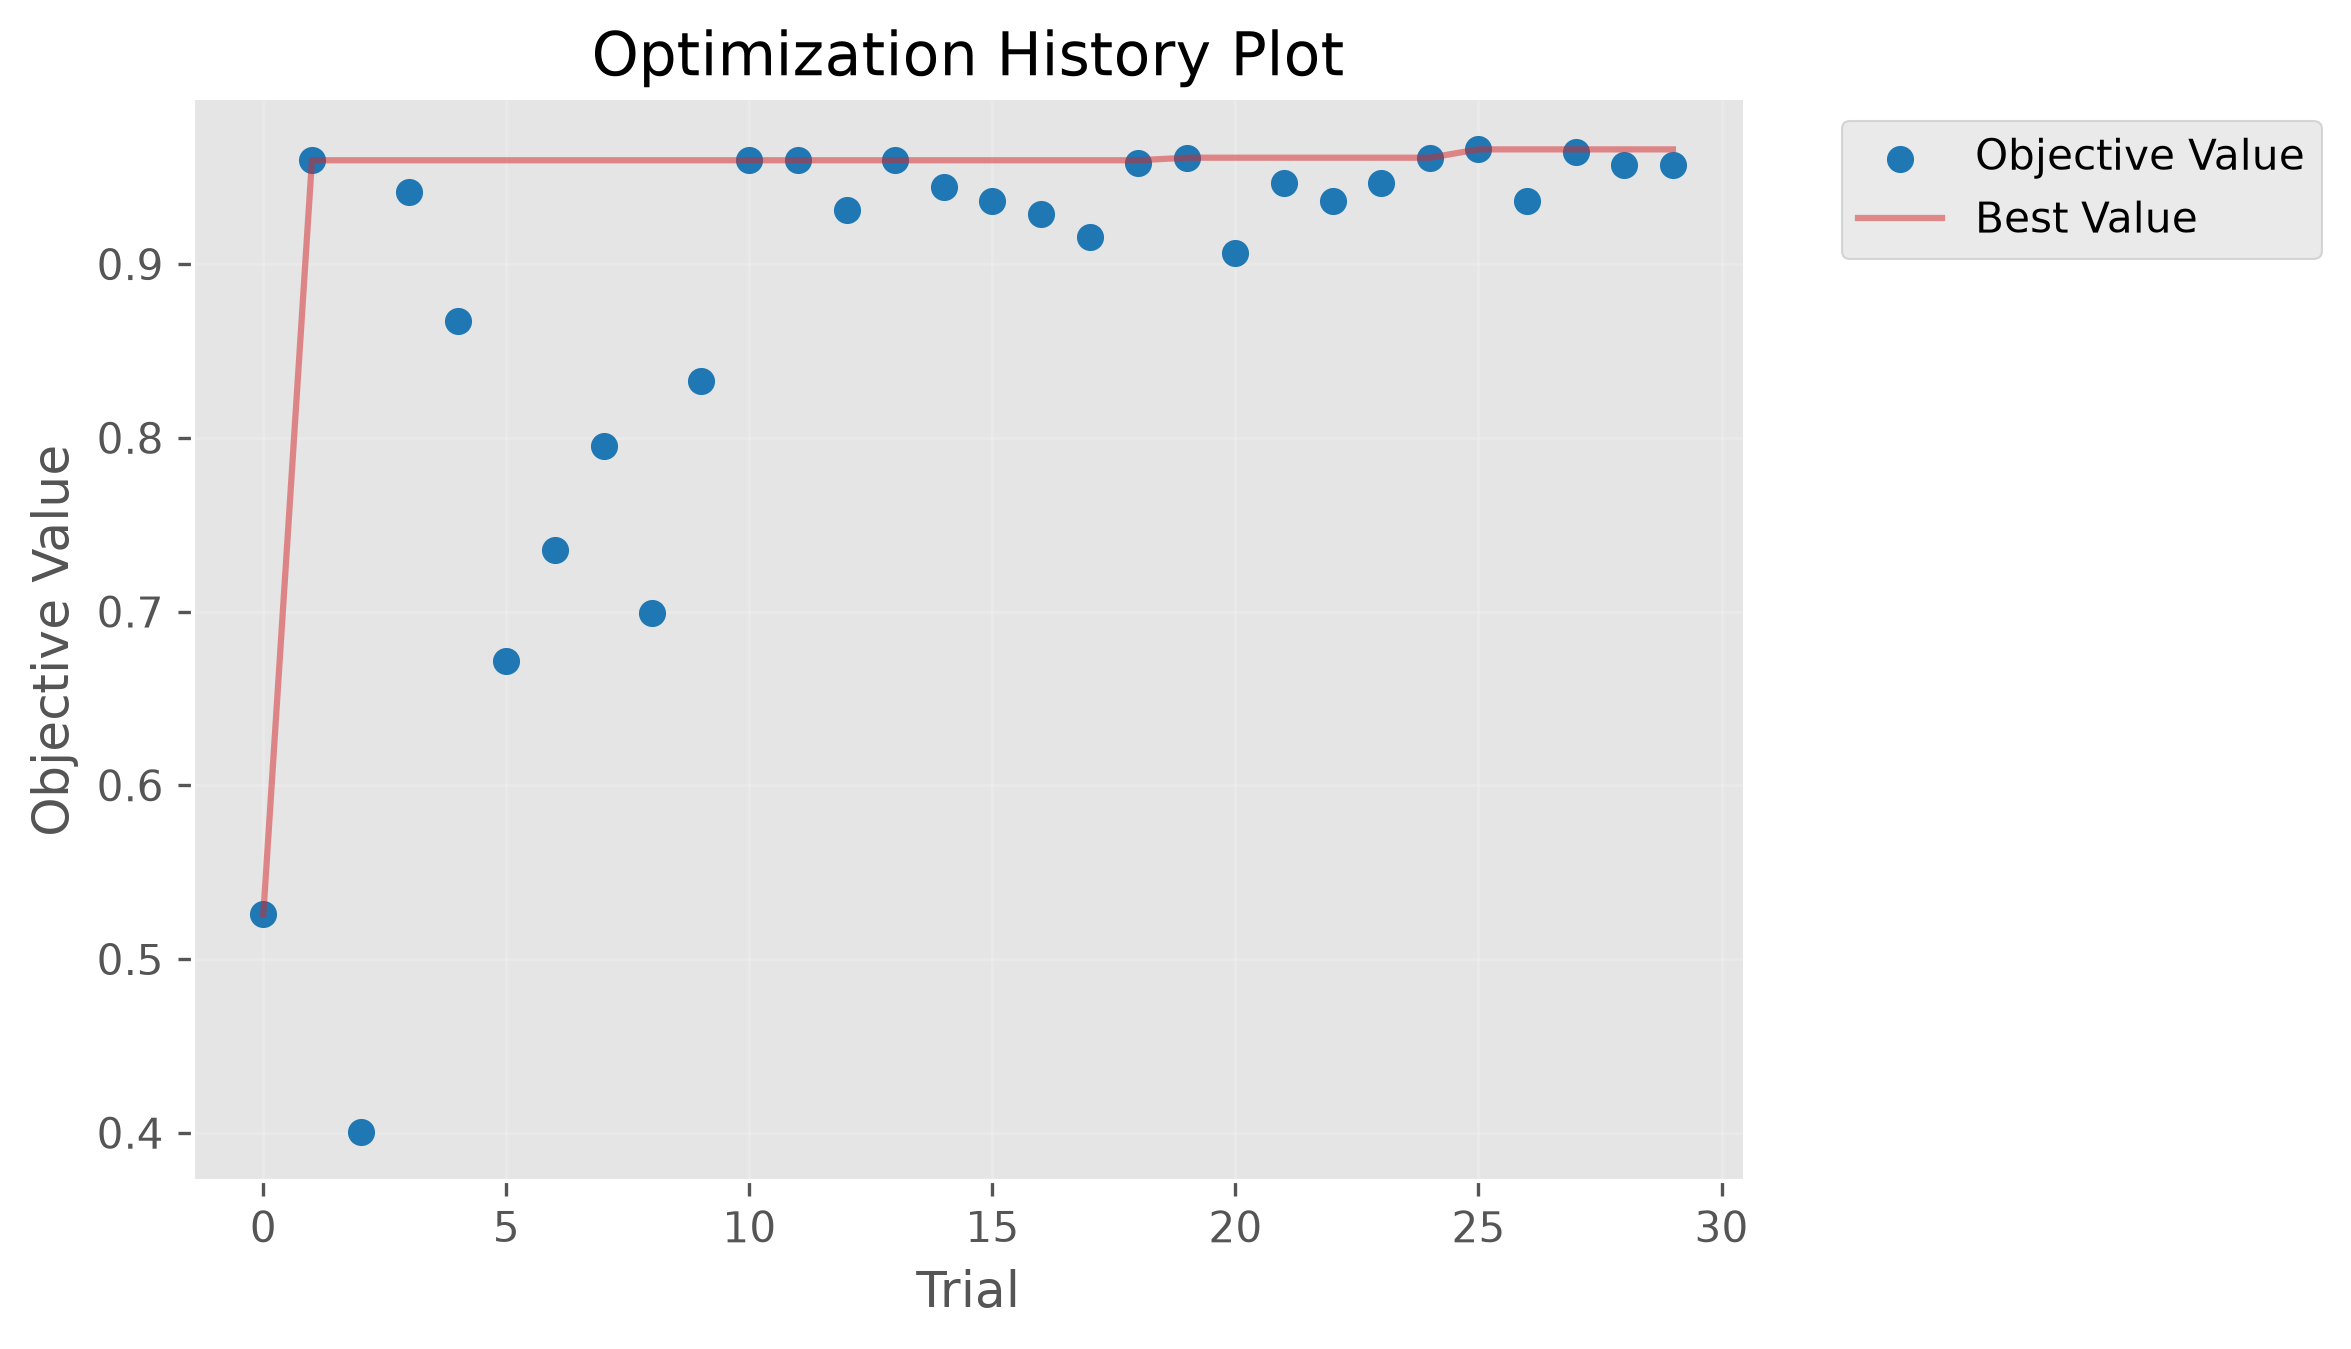

In [38]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'optimization_RF.png')))

### Рисунок 8. Важливість гіперпараметрів: RF

На рисунку 8 зображено важливість гіперпараметрів: RF. Параметри й оцінки одержані без використання Test для налаштування.

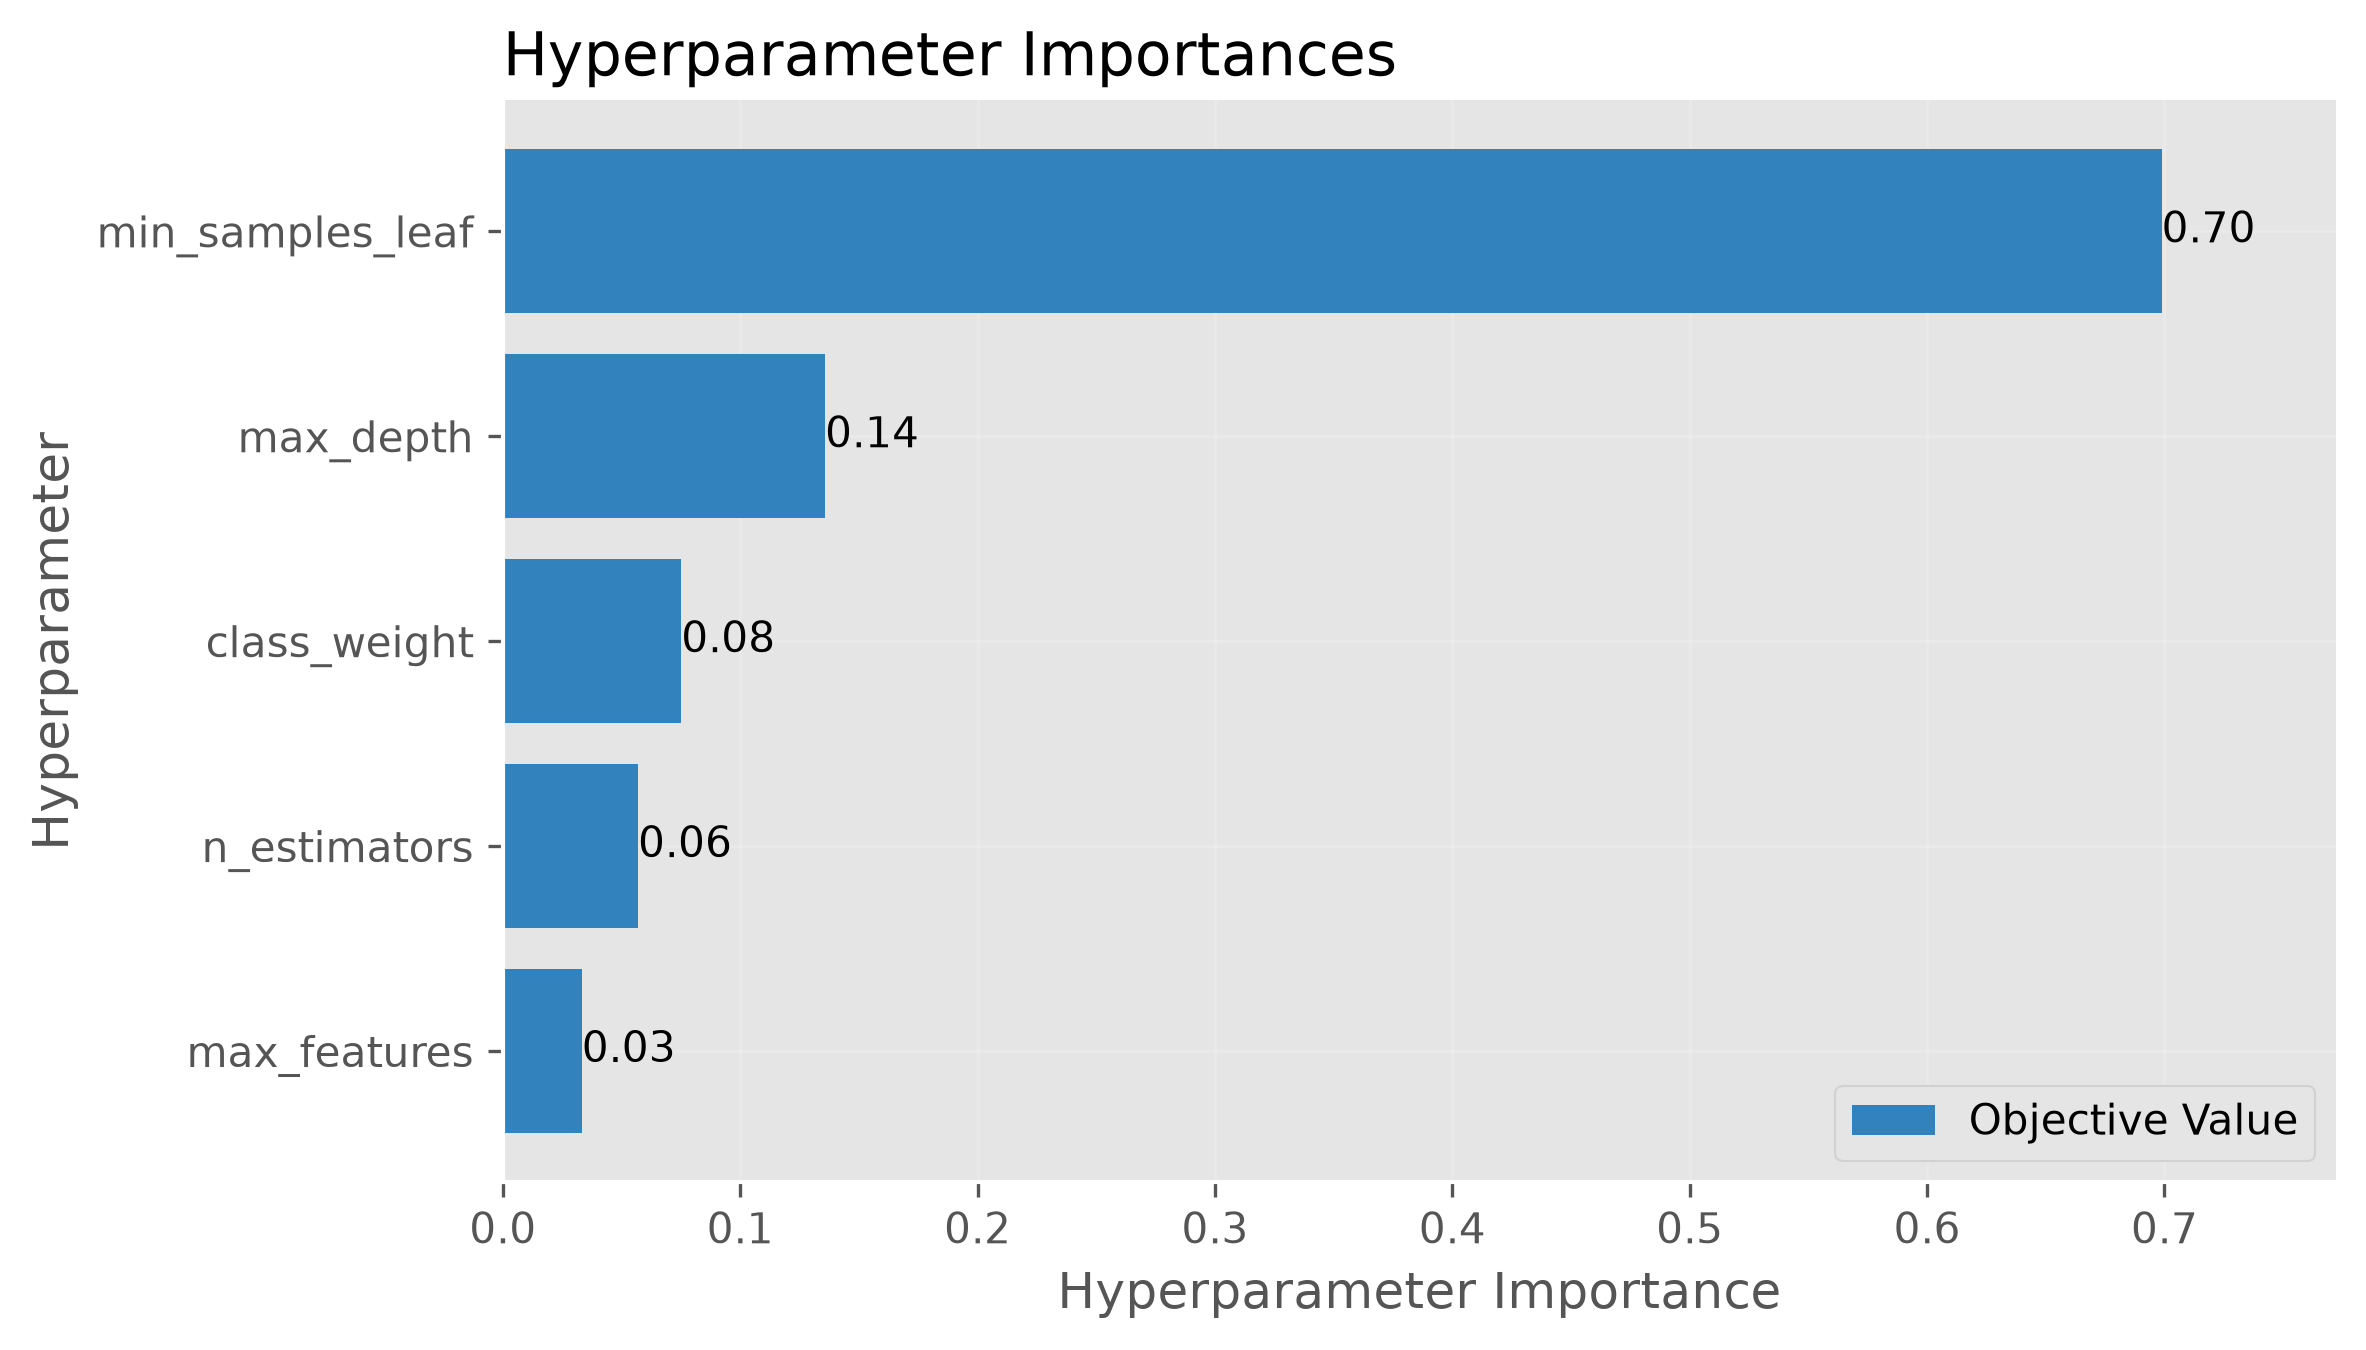

In [39]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'parameter_importance_RF.png')))

### Рисунок 9. MDI важливості: RF

На рисунку 9 зображено mDI важливості: RF. Параметри й оцінки одержані без використання Test для налаштування.

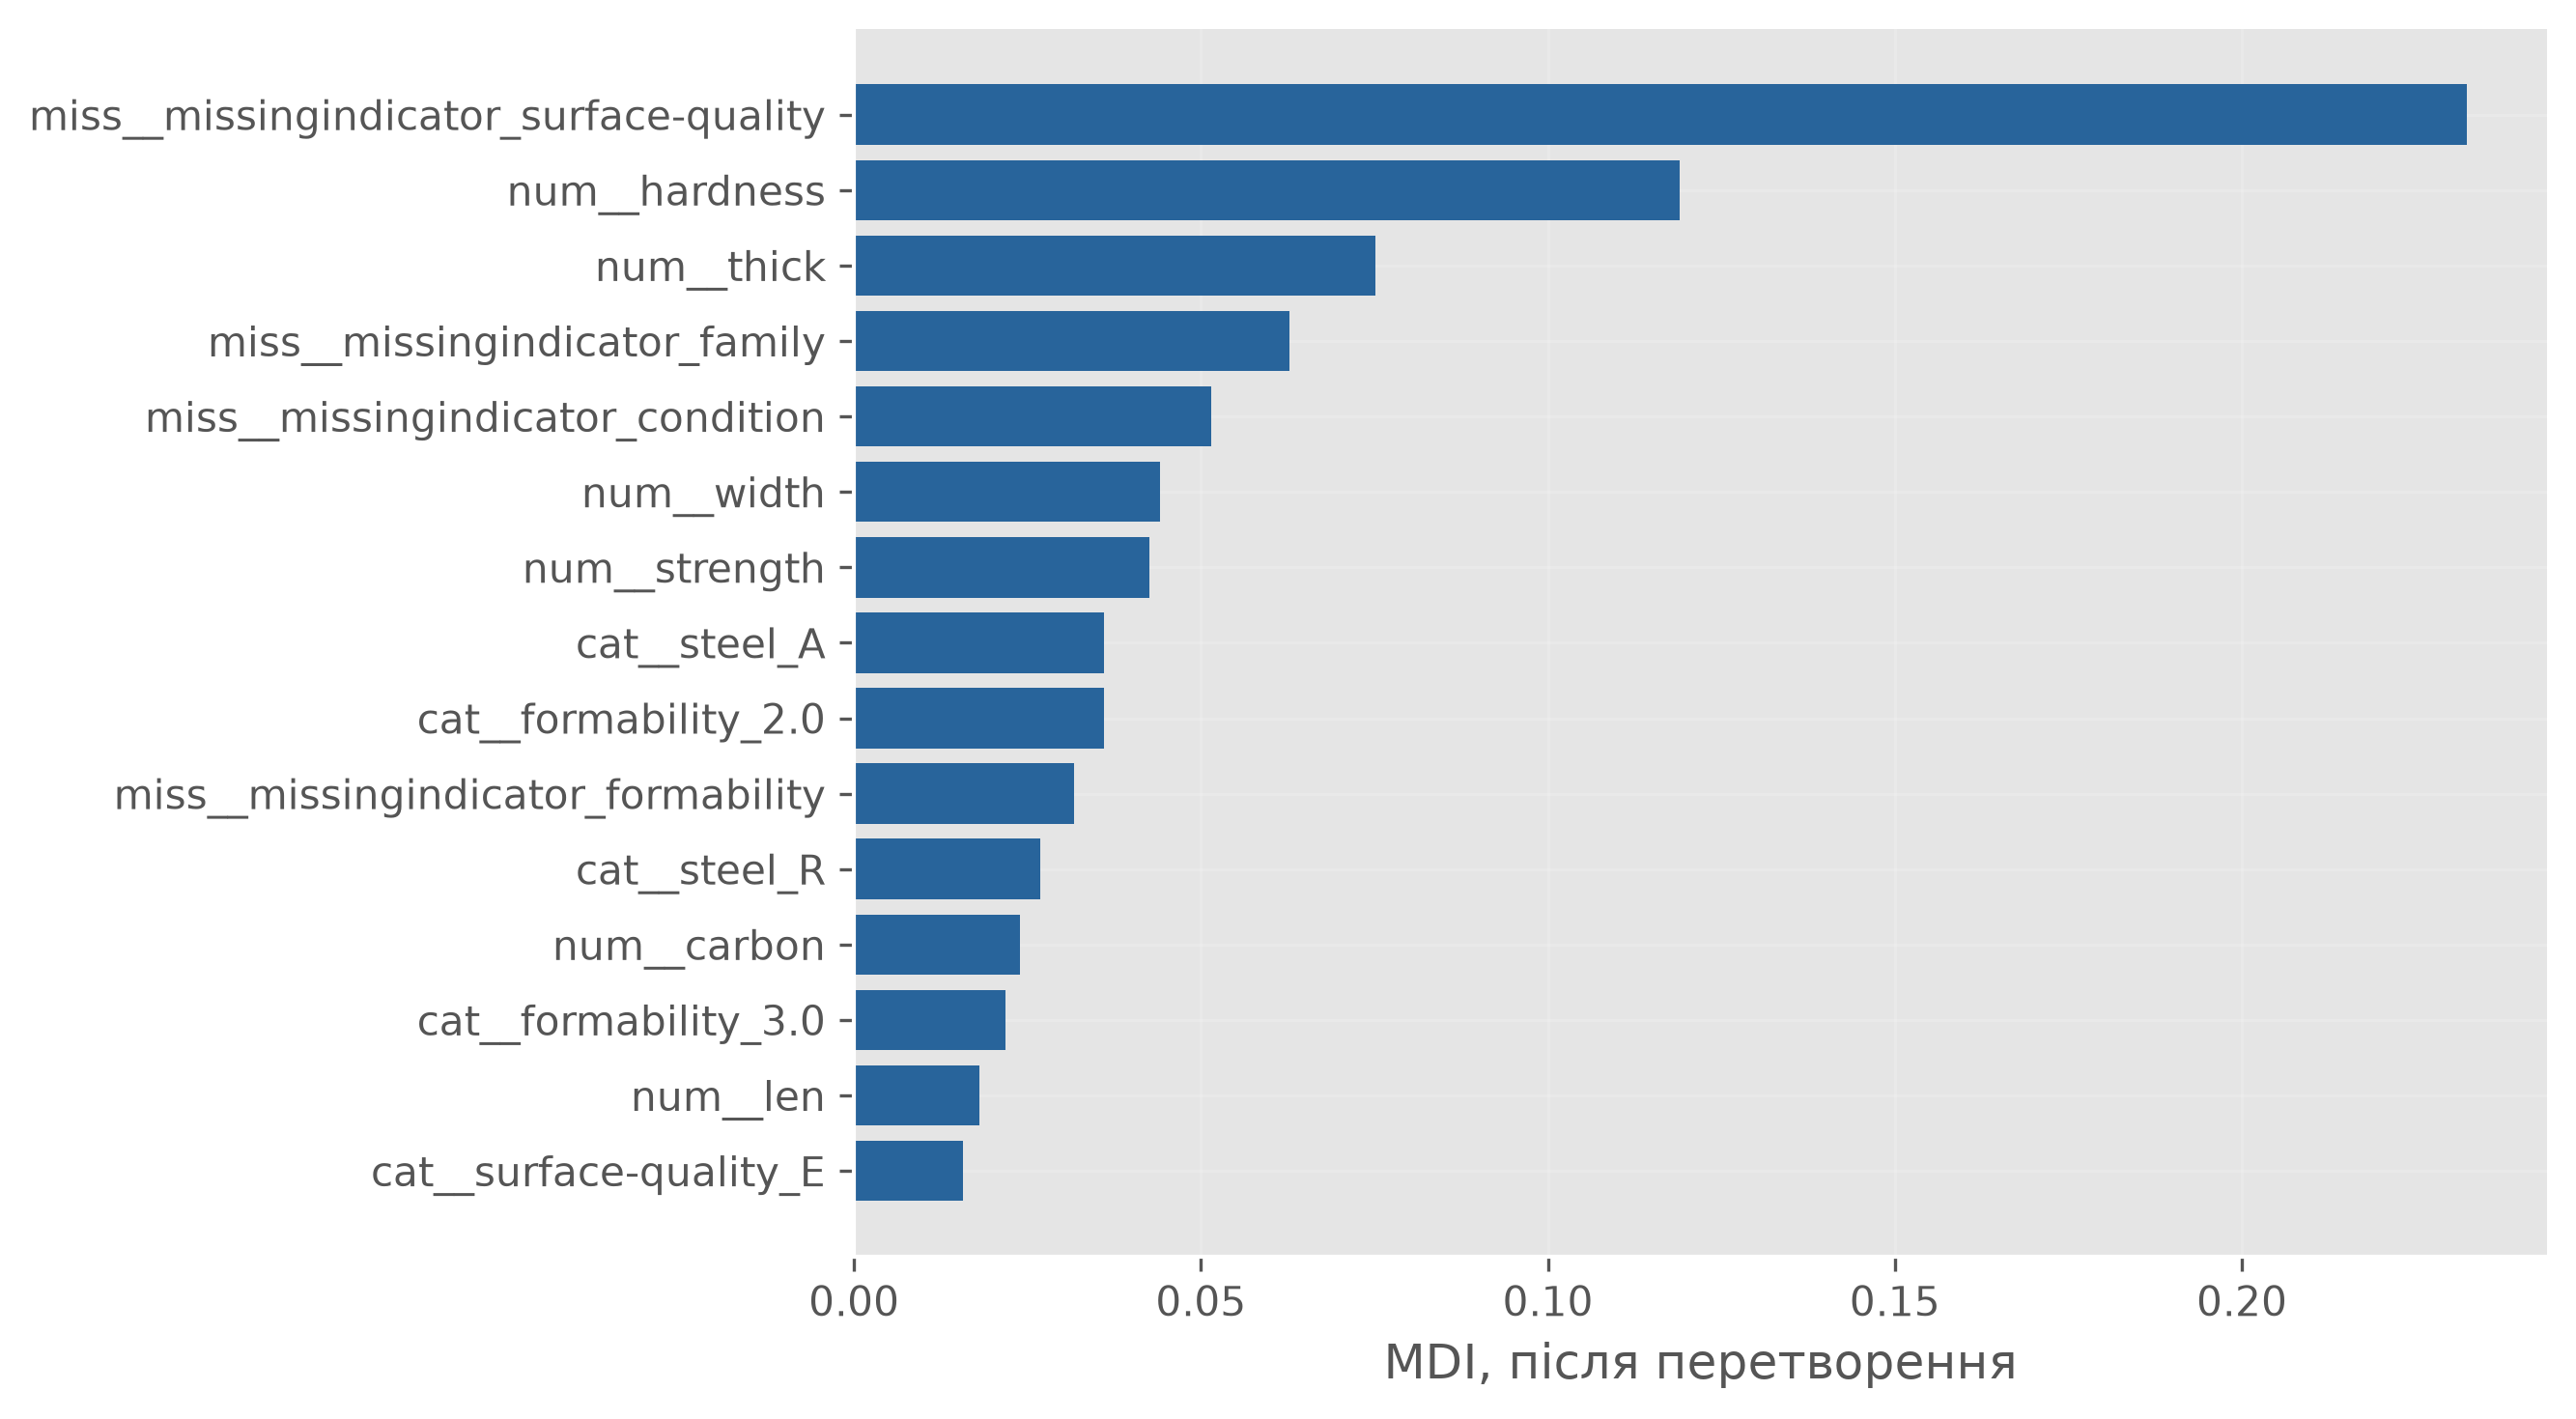

In [40]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'mdi_RF.png')))

### Рисунок 10. Permutation importance: RF

На рисунку 10 зображено permutation importance: RF. Параметри й оцінки одержані без використання Test для налаштування.

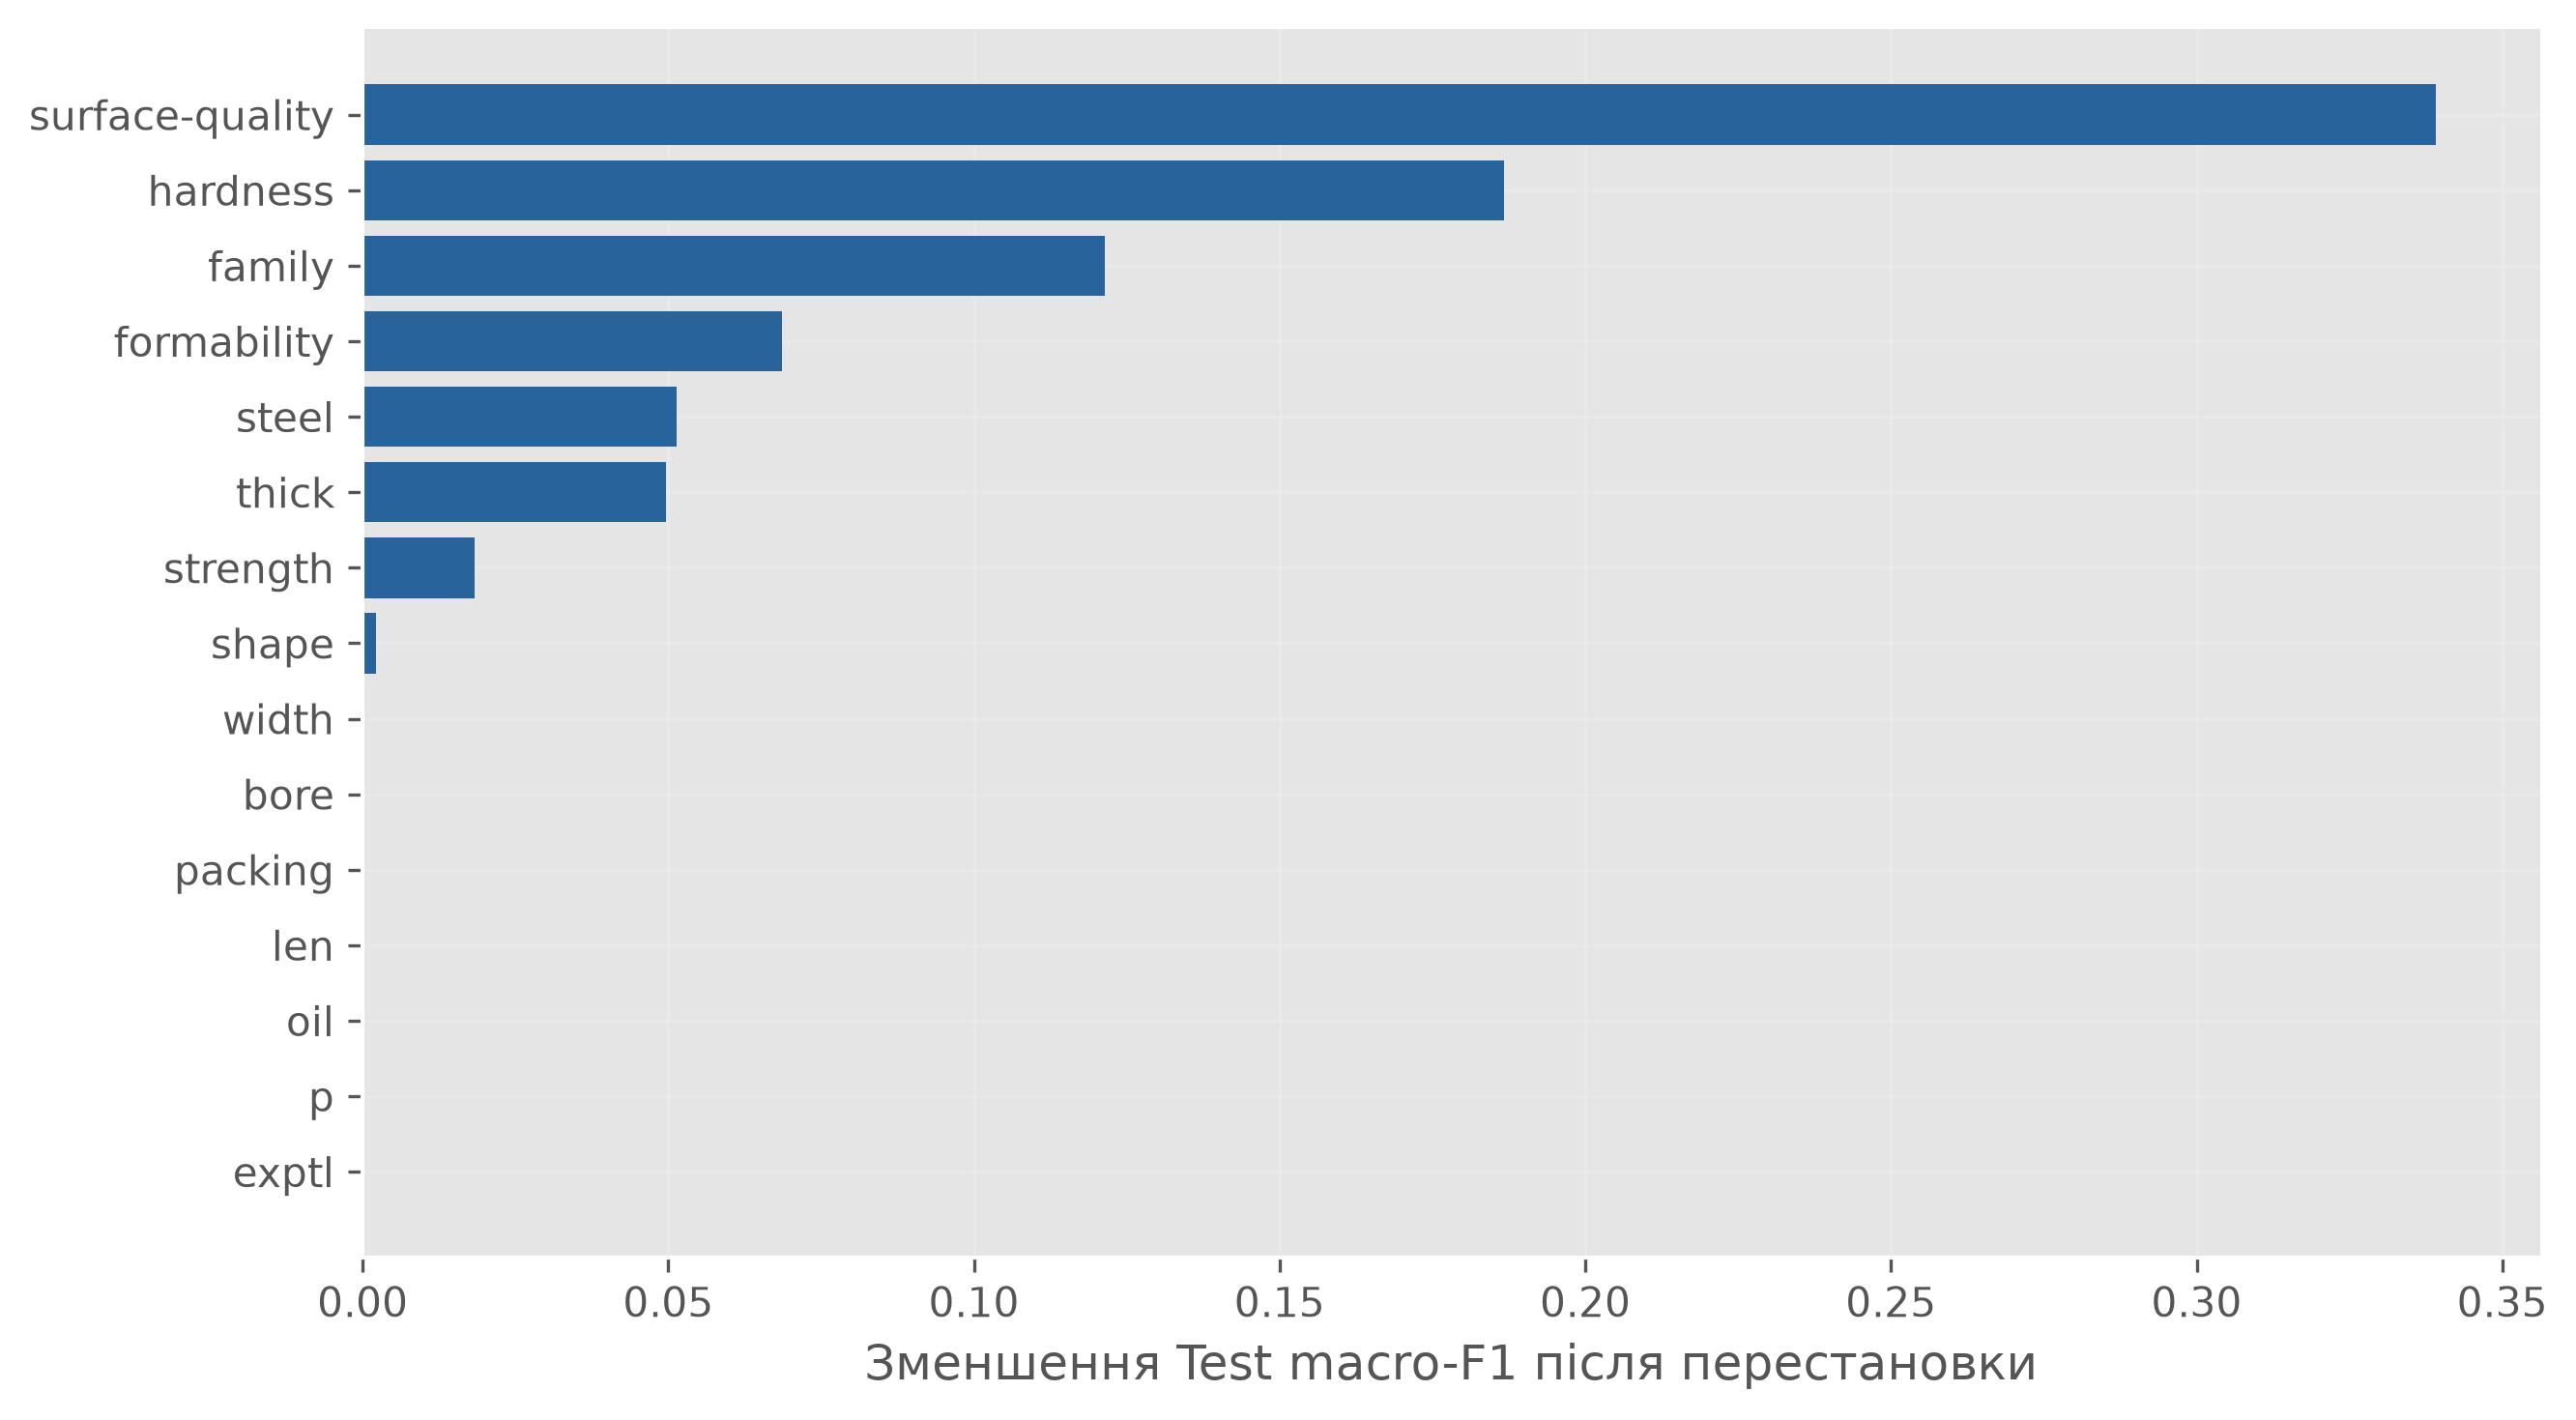

In [41]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'permutation_RF.png')))

### Рисунок 11. Історія Optuna: XGB

На рисунку 11 зображено історія Optuna: XGB. Параметри й оцінки одержані без використання Test для налаштування.

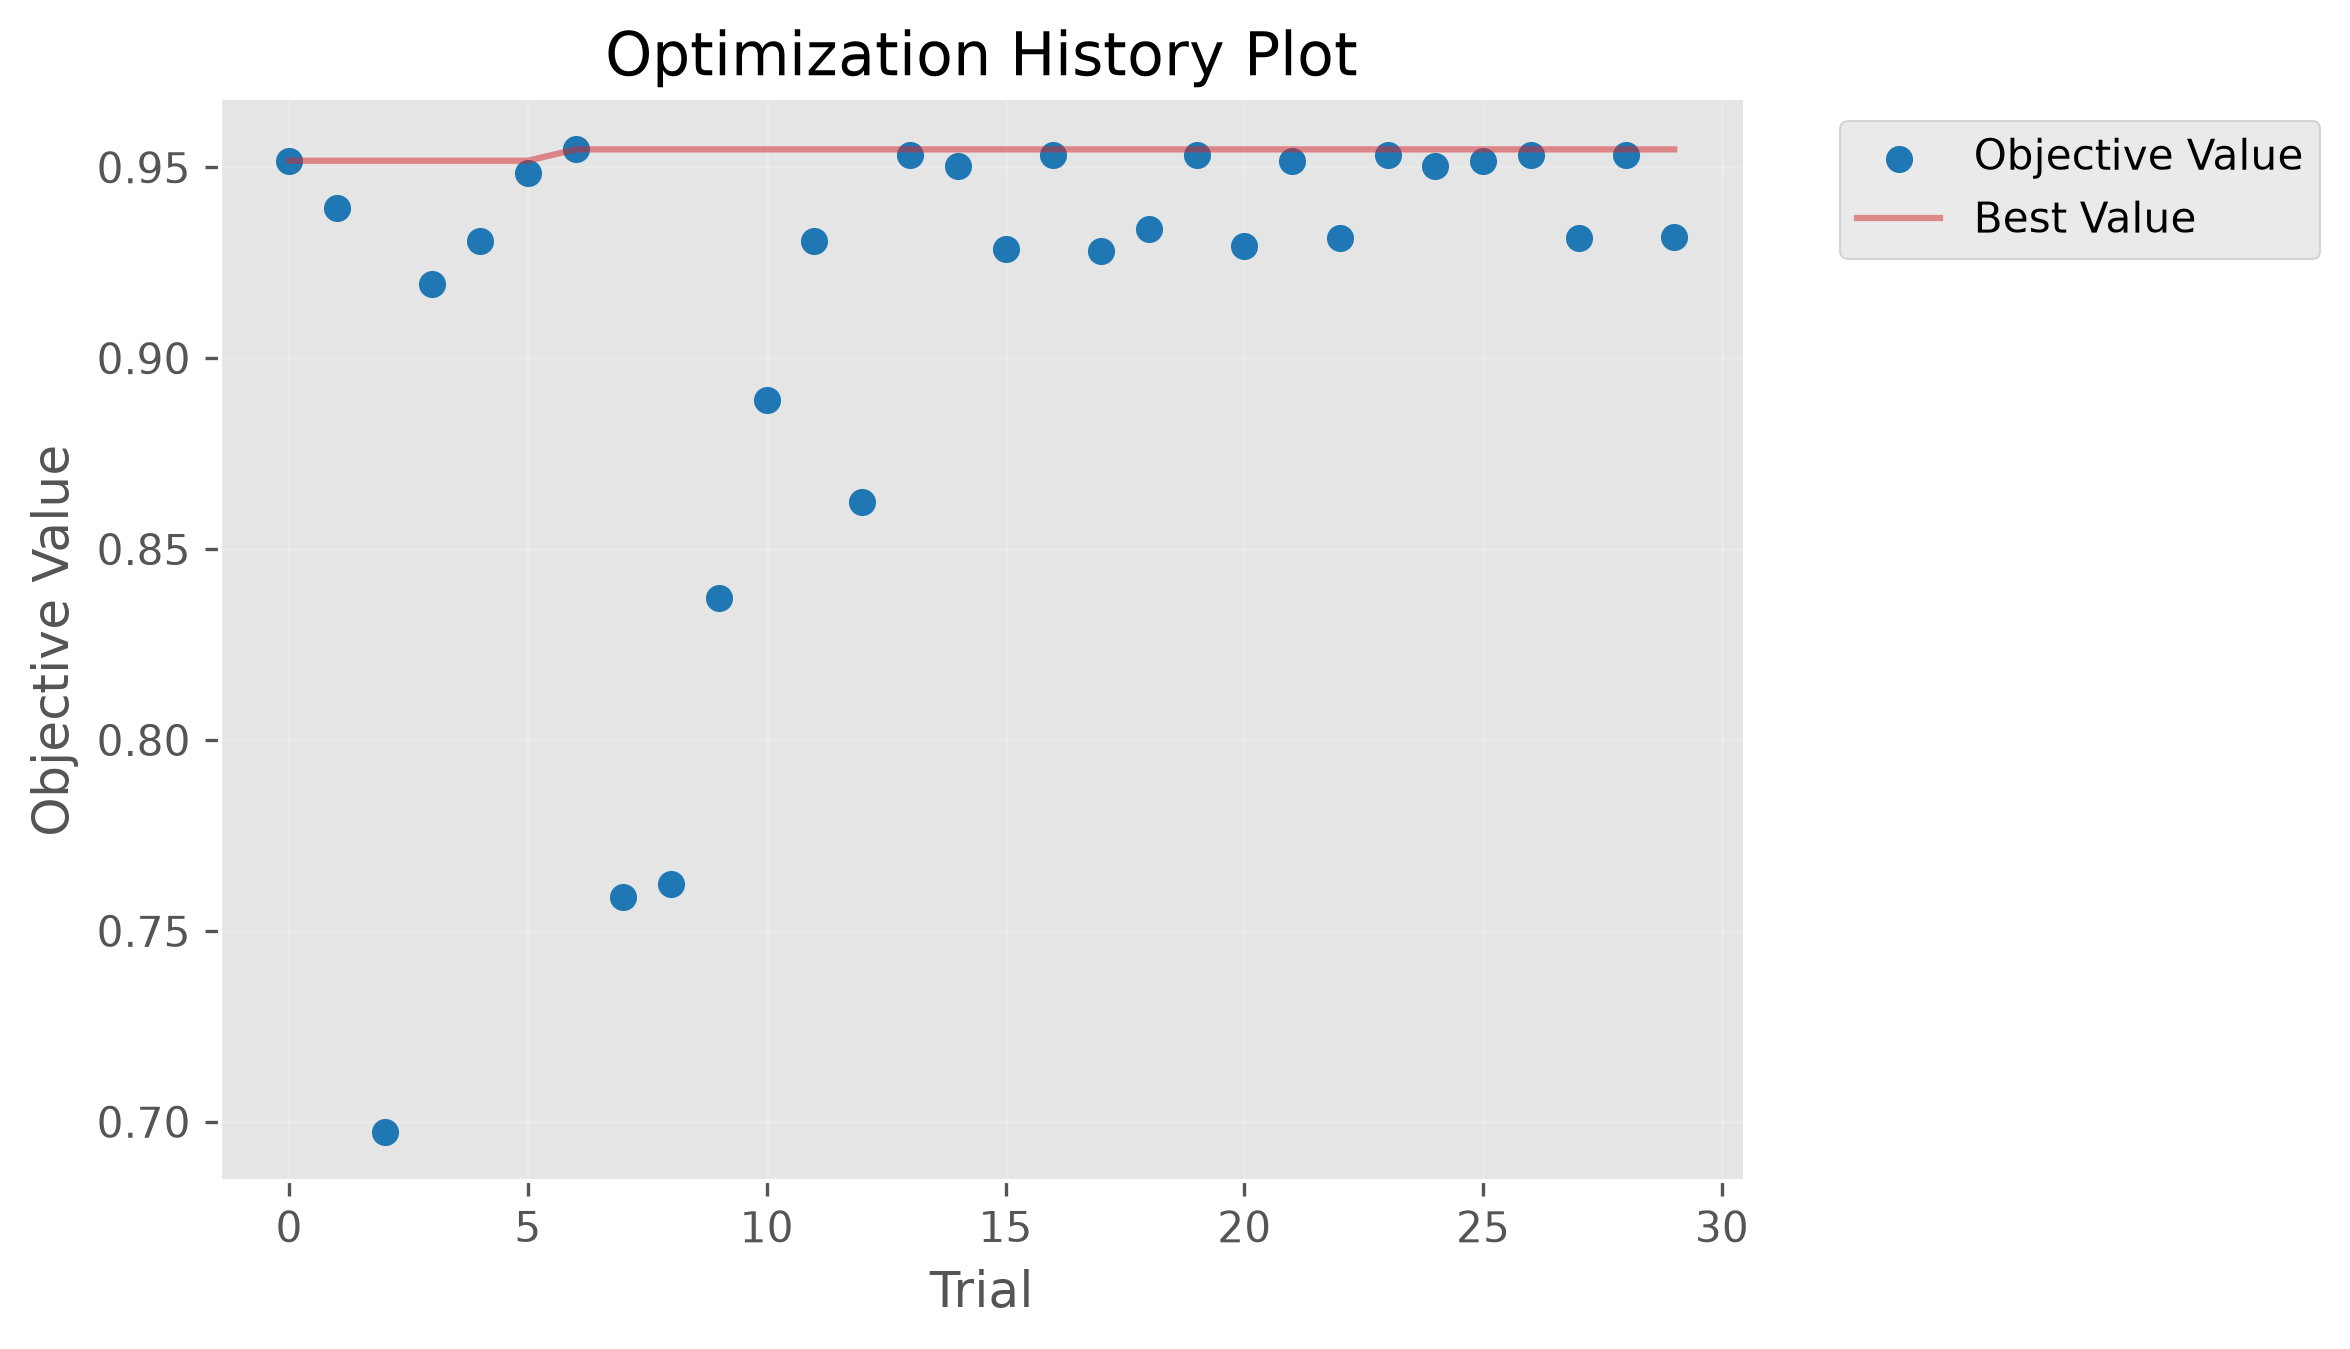

In [42]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'optimization_XGB.png')))

### Рисунок 12. Важливість гіперпараметрів: XGB

На рисунку 12 зображено важливість гіперпараметрів: XGB. Параметри й оцінки одержані без використання Test для налаштування.

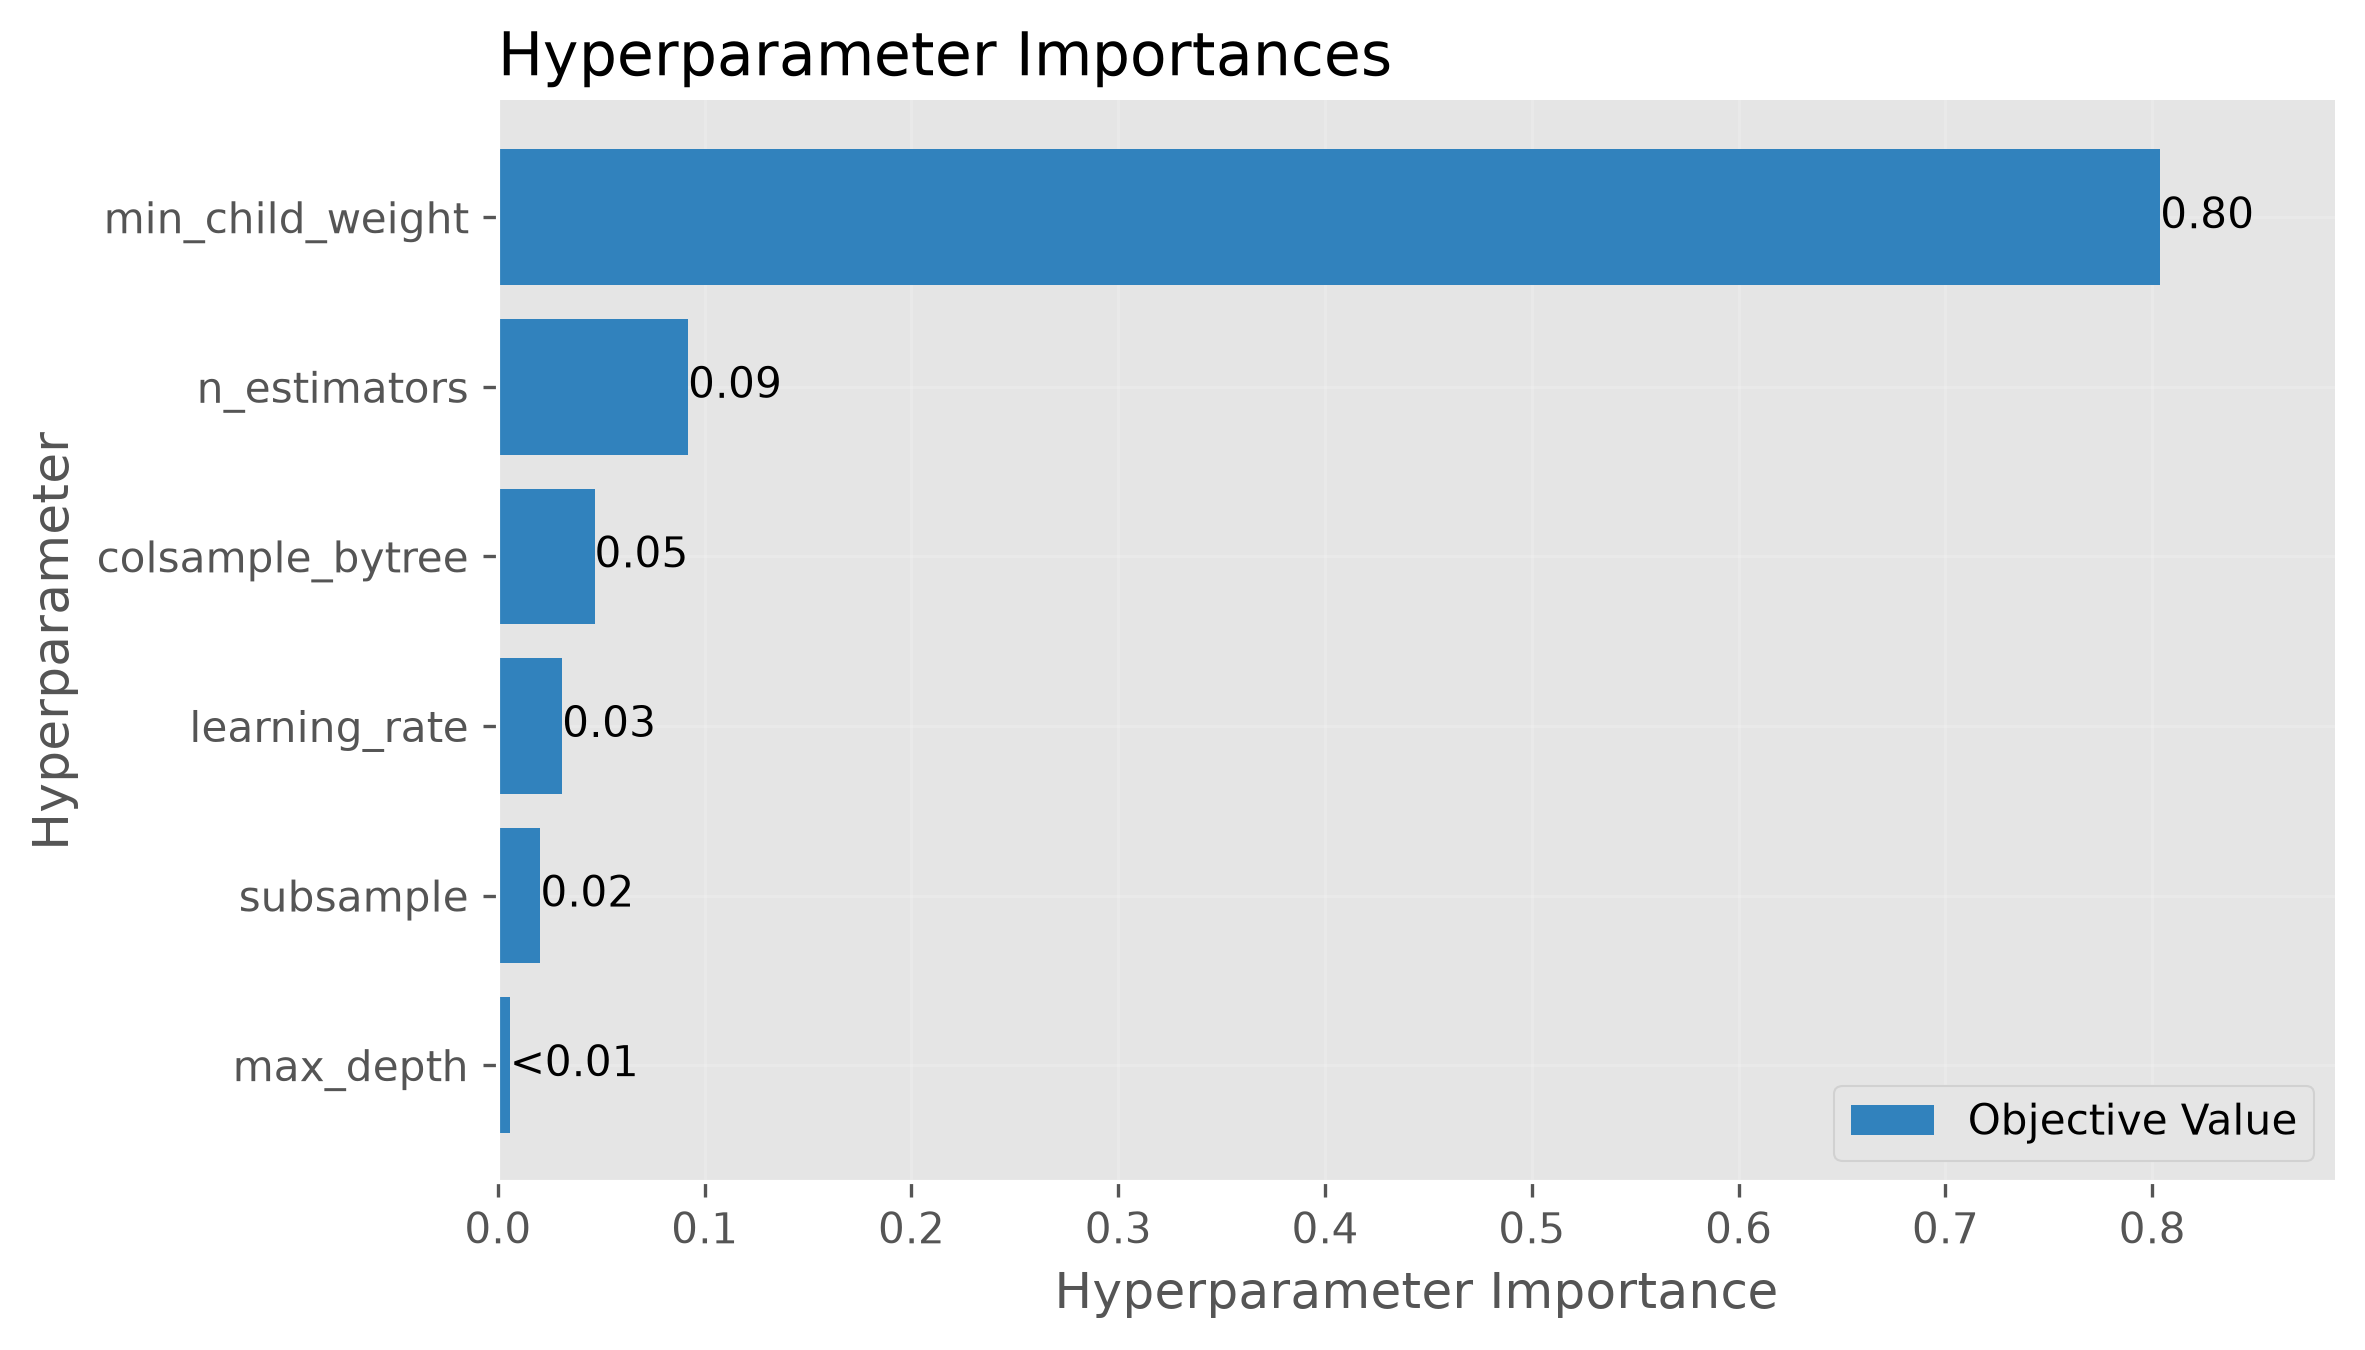

In [43]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'parameter_importance_XGB.png')))

### Рисунок 13. Вбудована важливість gain: XGB

На рисунку 13 зображено вбудована важливість gain: XGB. Параметри й оцінки одержані без використання Test для налаштування.

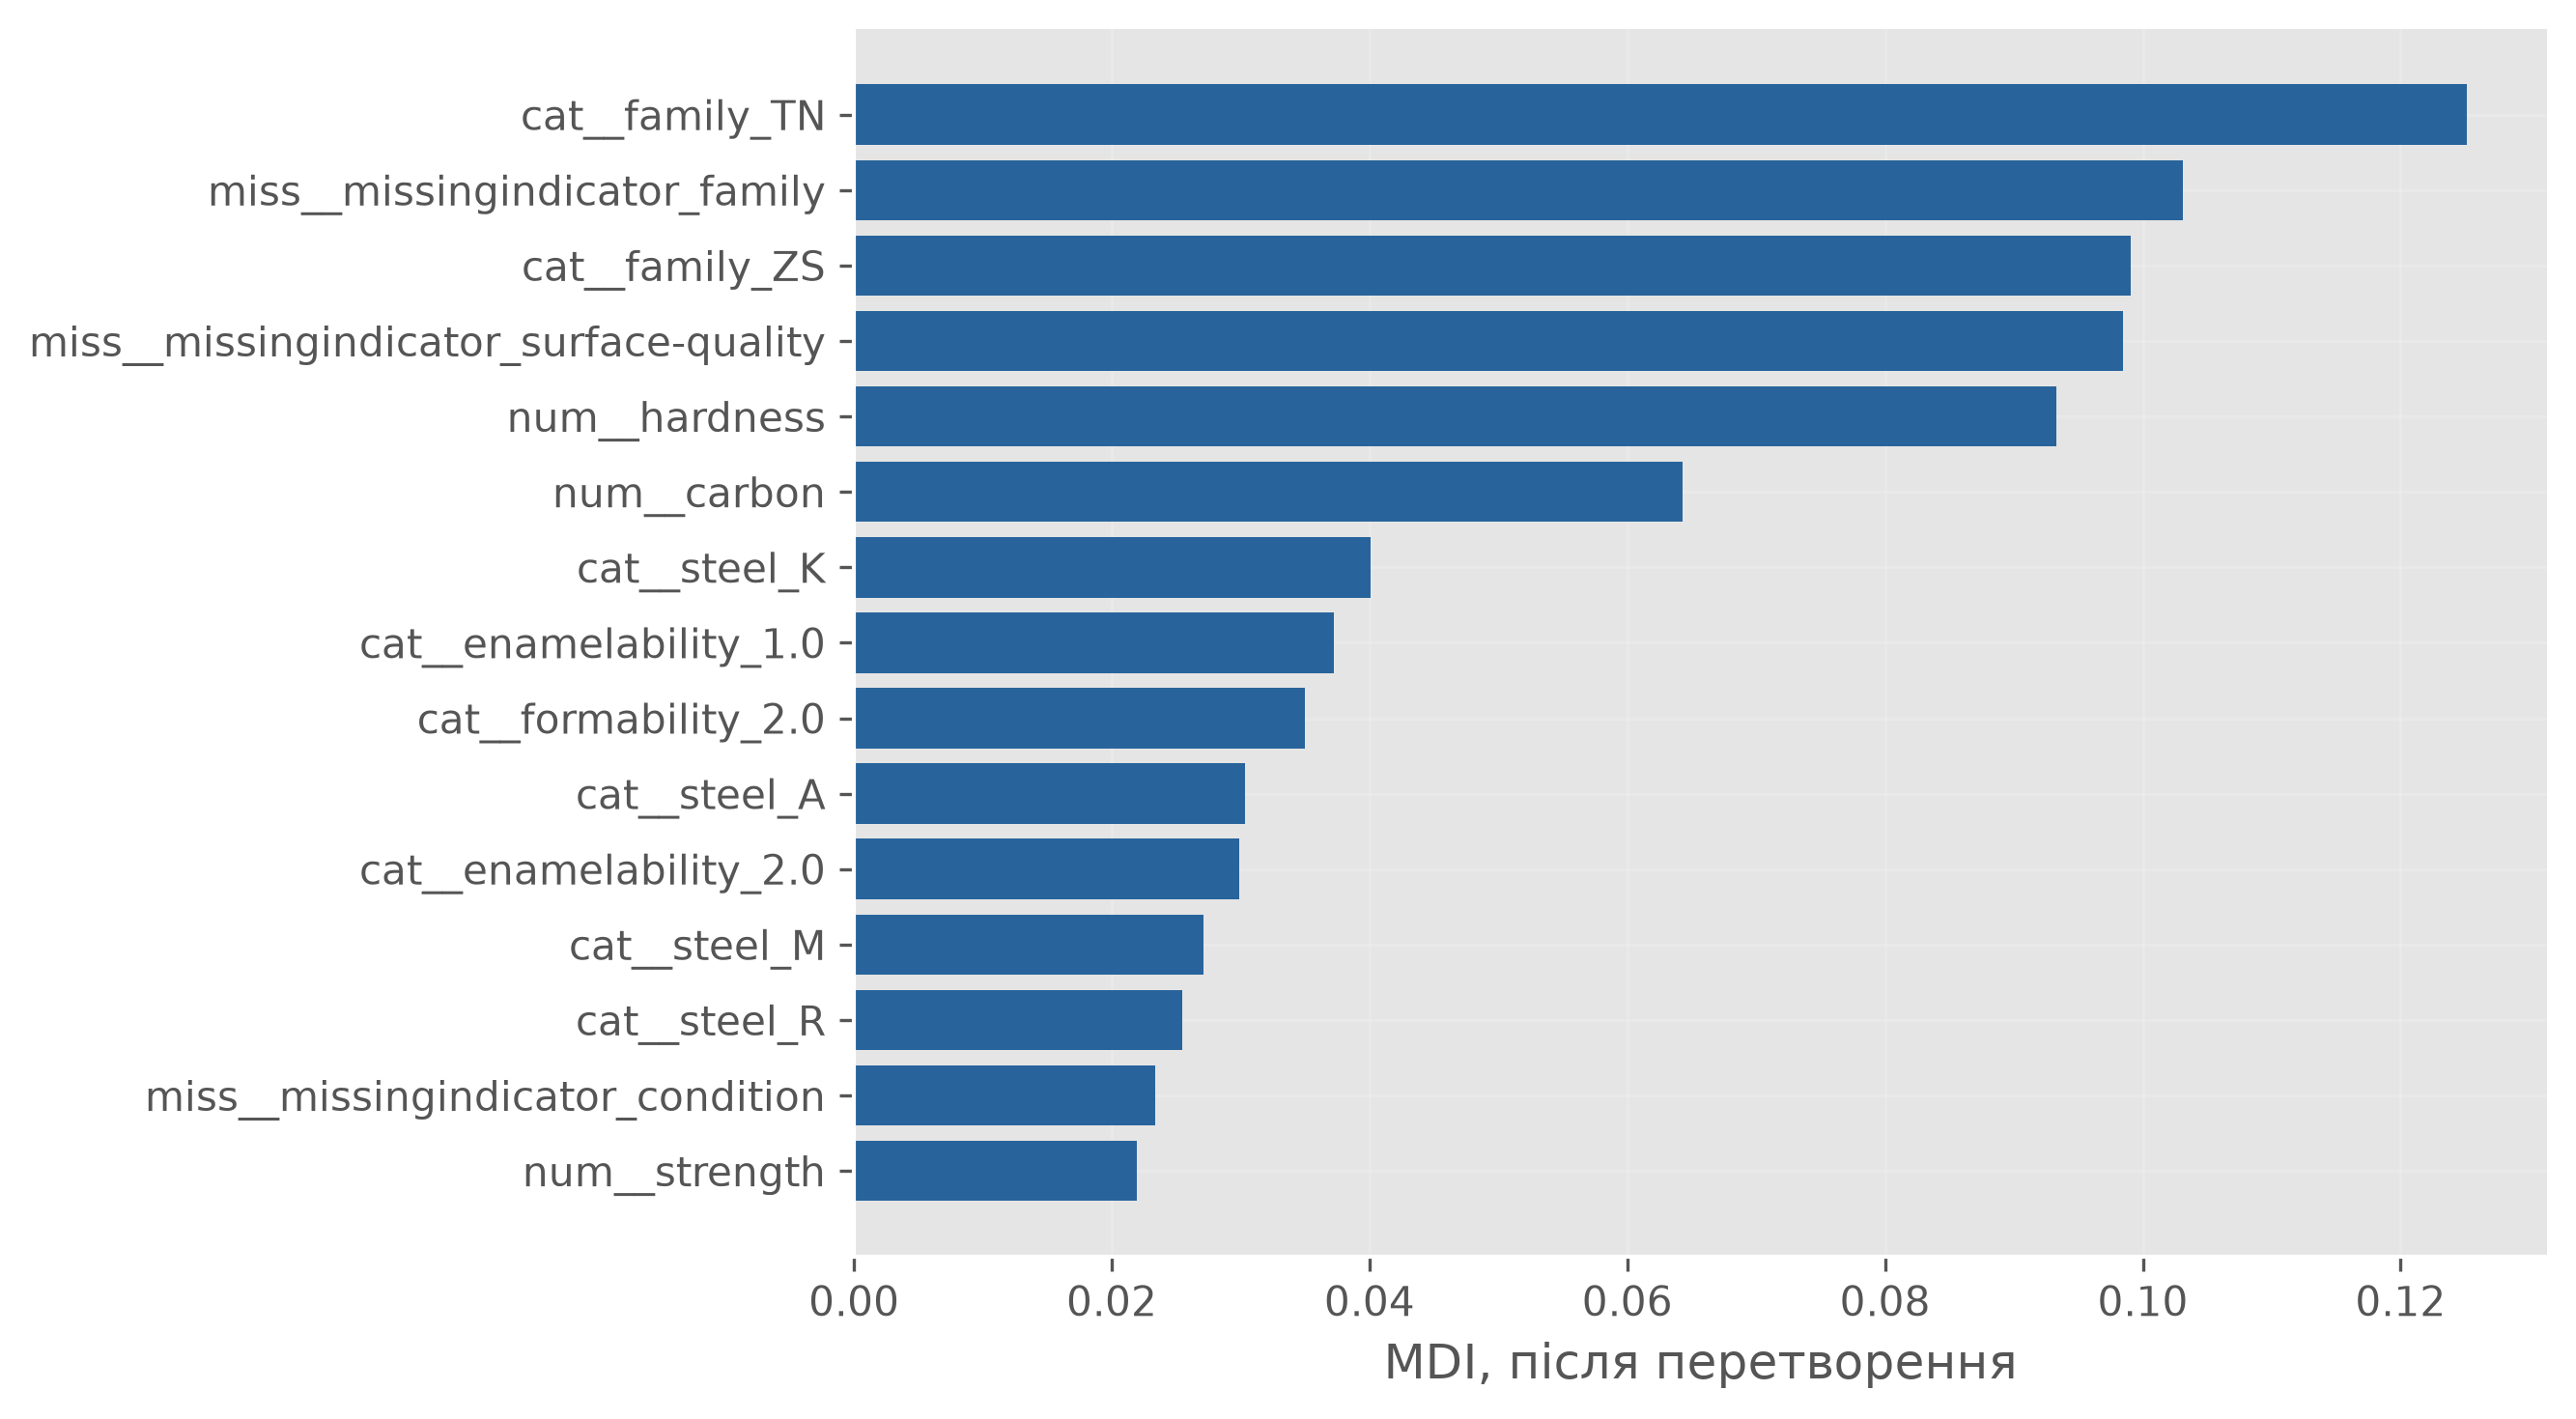

In [44]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'mdi_XGB.png')))

### Рисунок 14. Permutation importance: XGB

На рисунку 14 зображено permutation importance: XGB. Параметри й оцінки одержані без використання Test для налаштування.

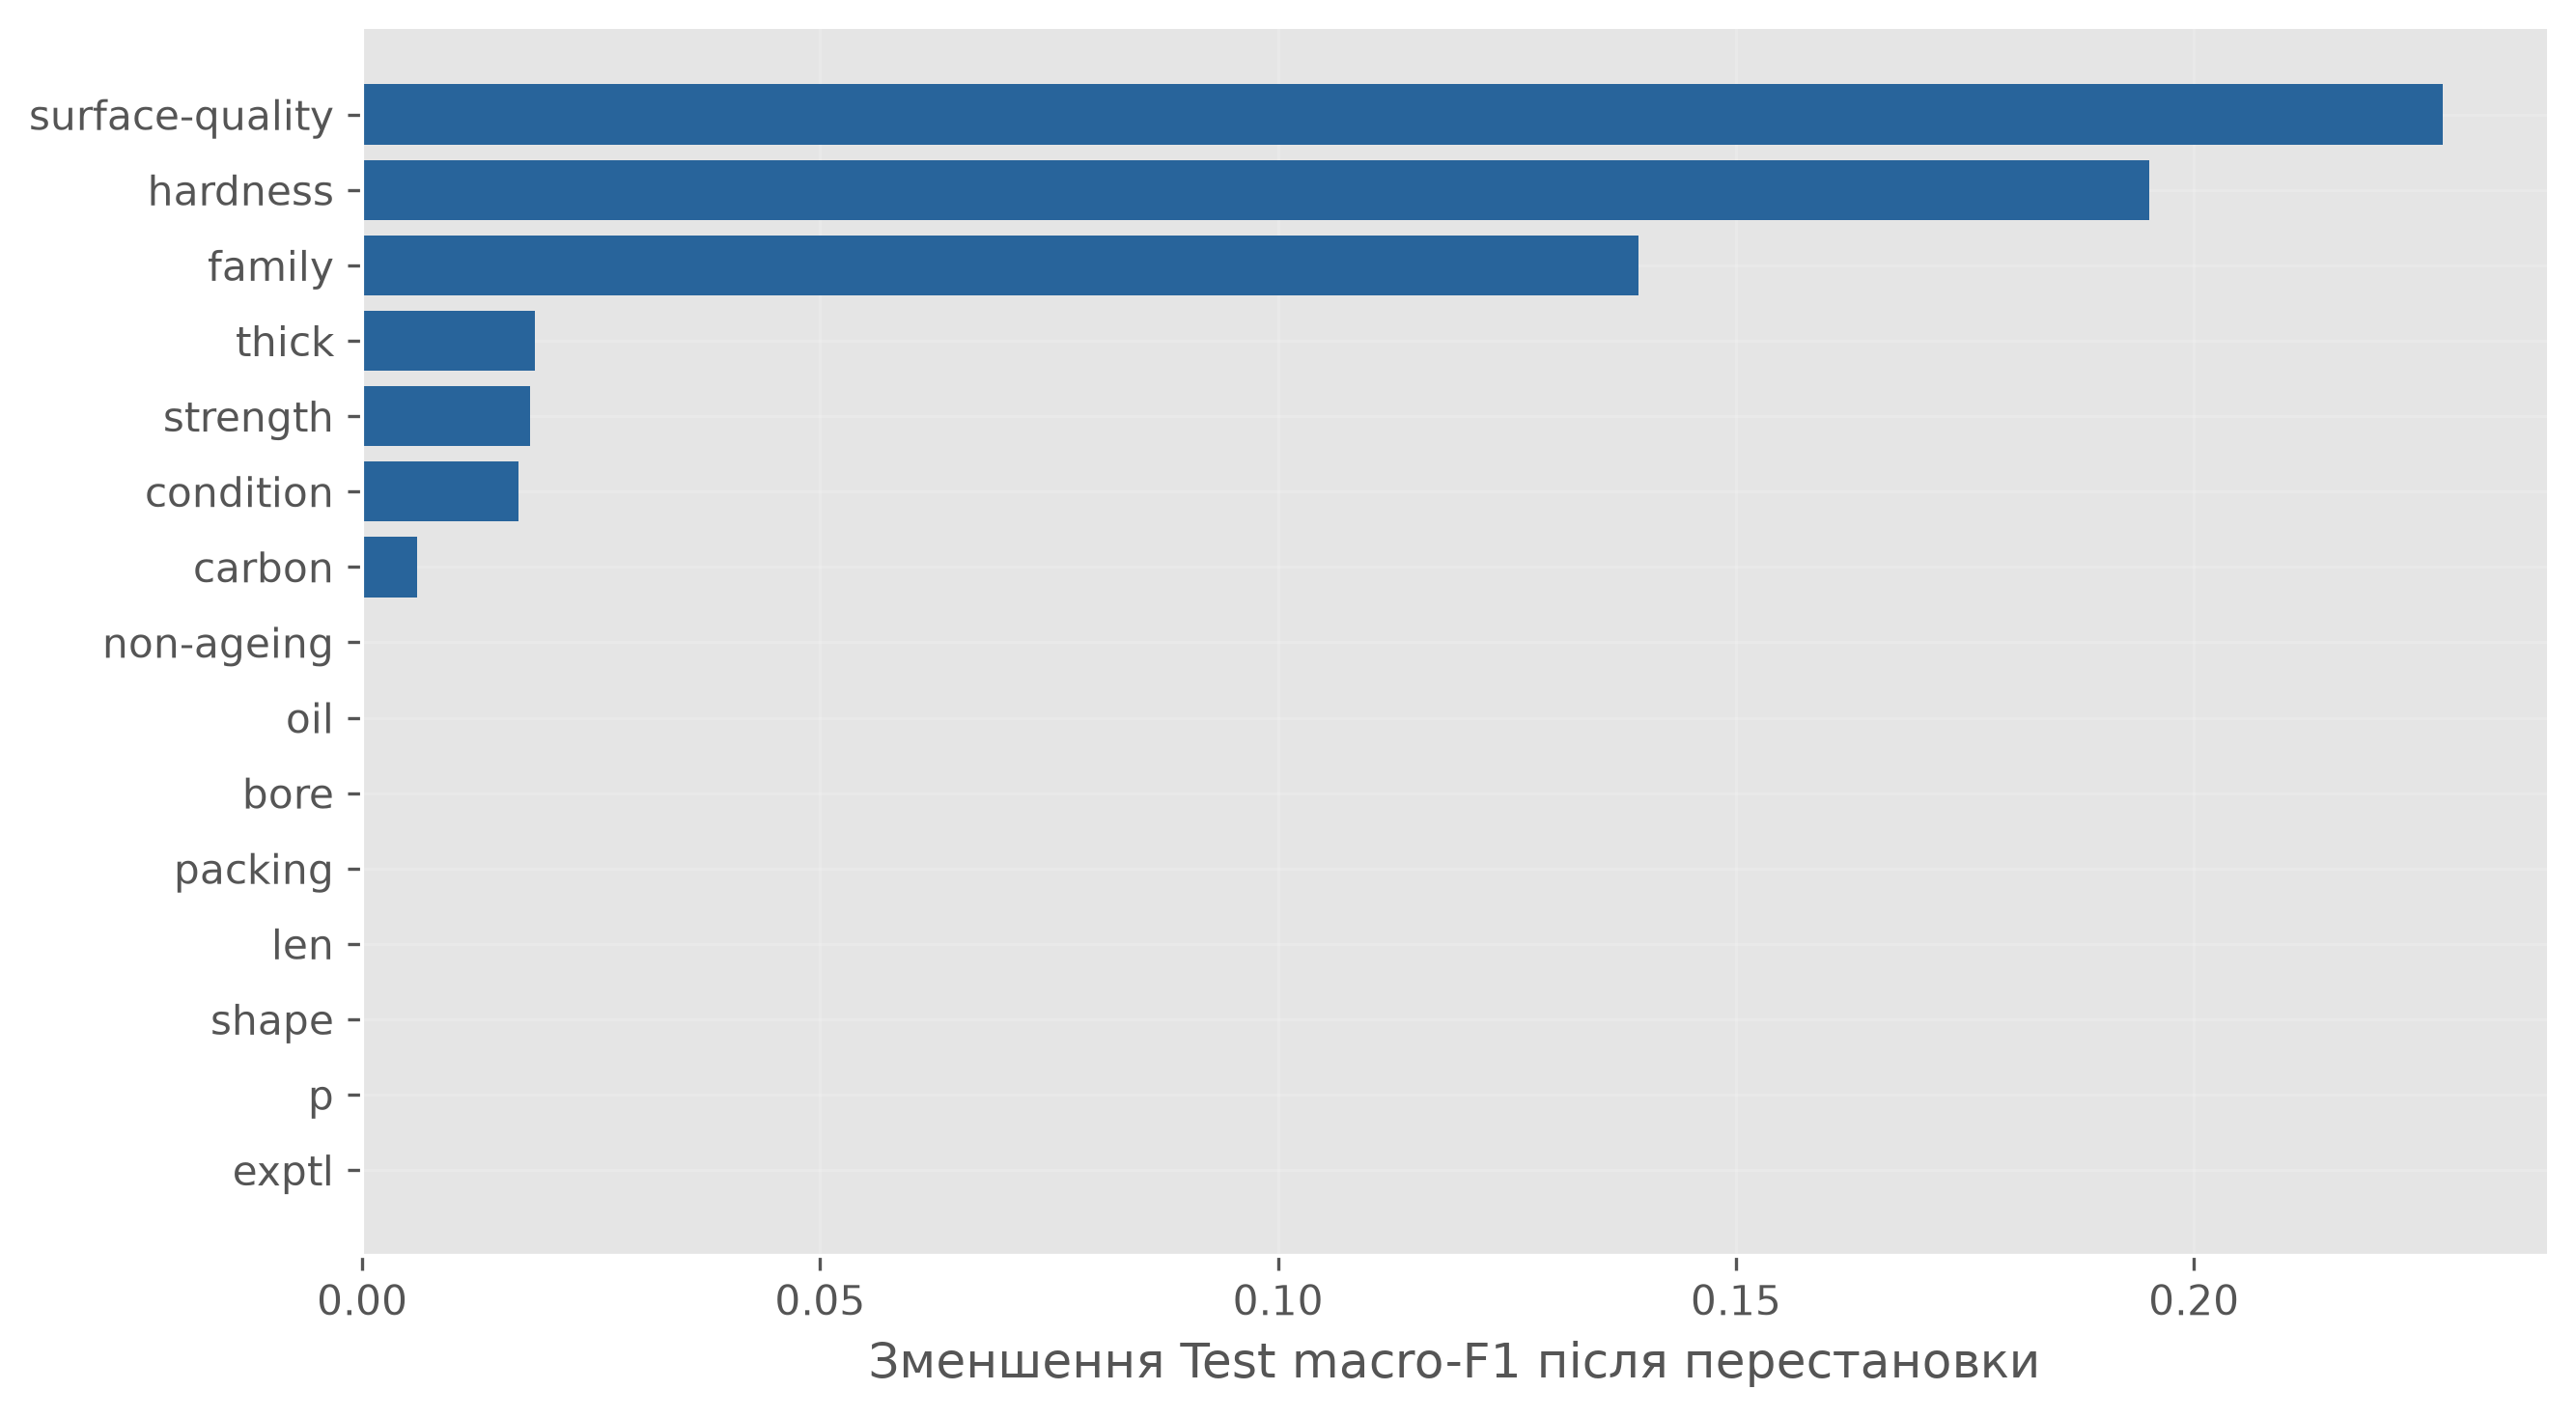

In [45]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'permutation_XGB.png')))

### Рисунок 15. Абсолютна матриця плутанини вибраної моделі

На рисунку 15 зображено абсолютна матриця плутанини вибраної моделі. Модель вибрано за вкладеною CV, до фінального тестового оцінювання.

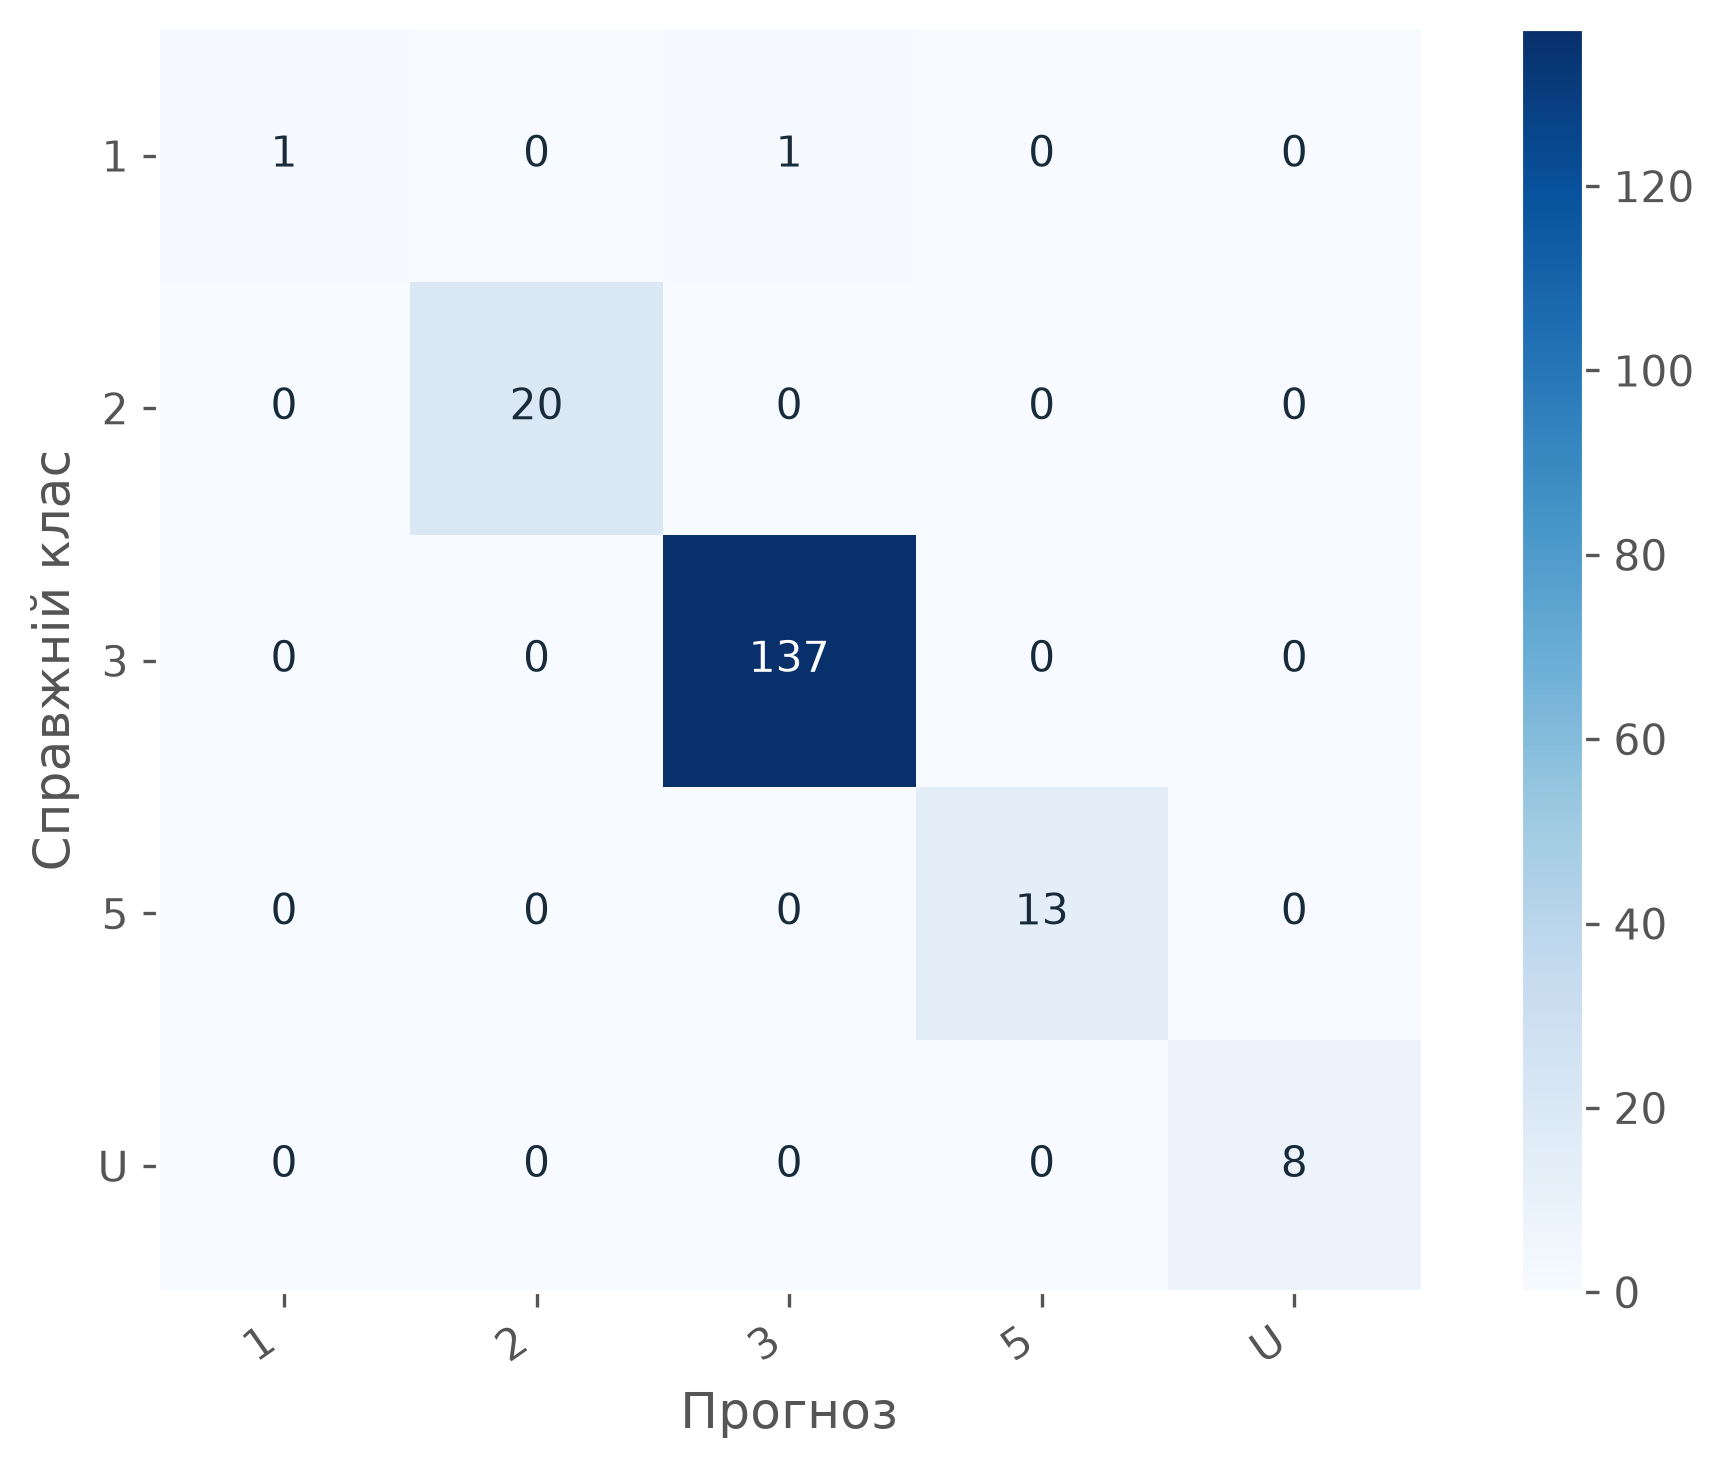

In [46]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'confusion.png')))

### Рисунок 16. Нормалізована за рядками матриця плутанини

На рисунку 16 зображено нормалізована за рядками матриця плутанини. Кожен рядок показує частки прогнозів для відповідного справжнього класу.

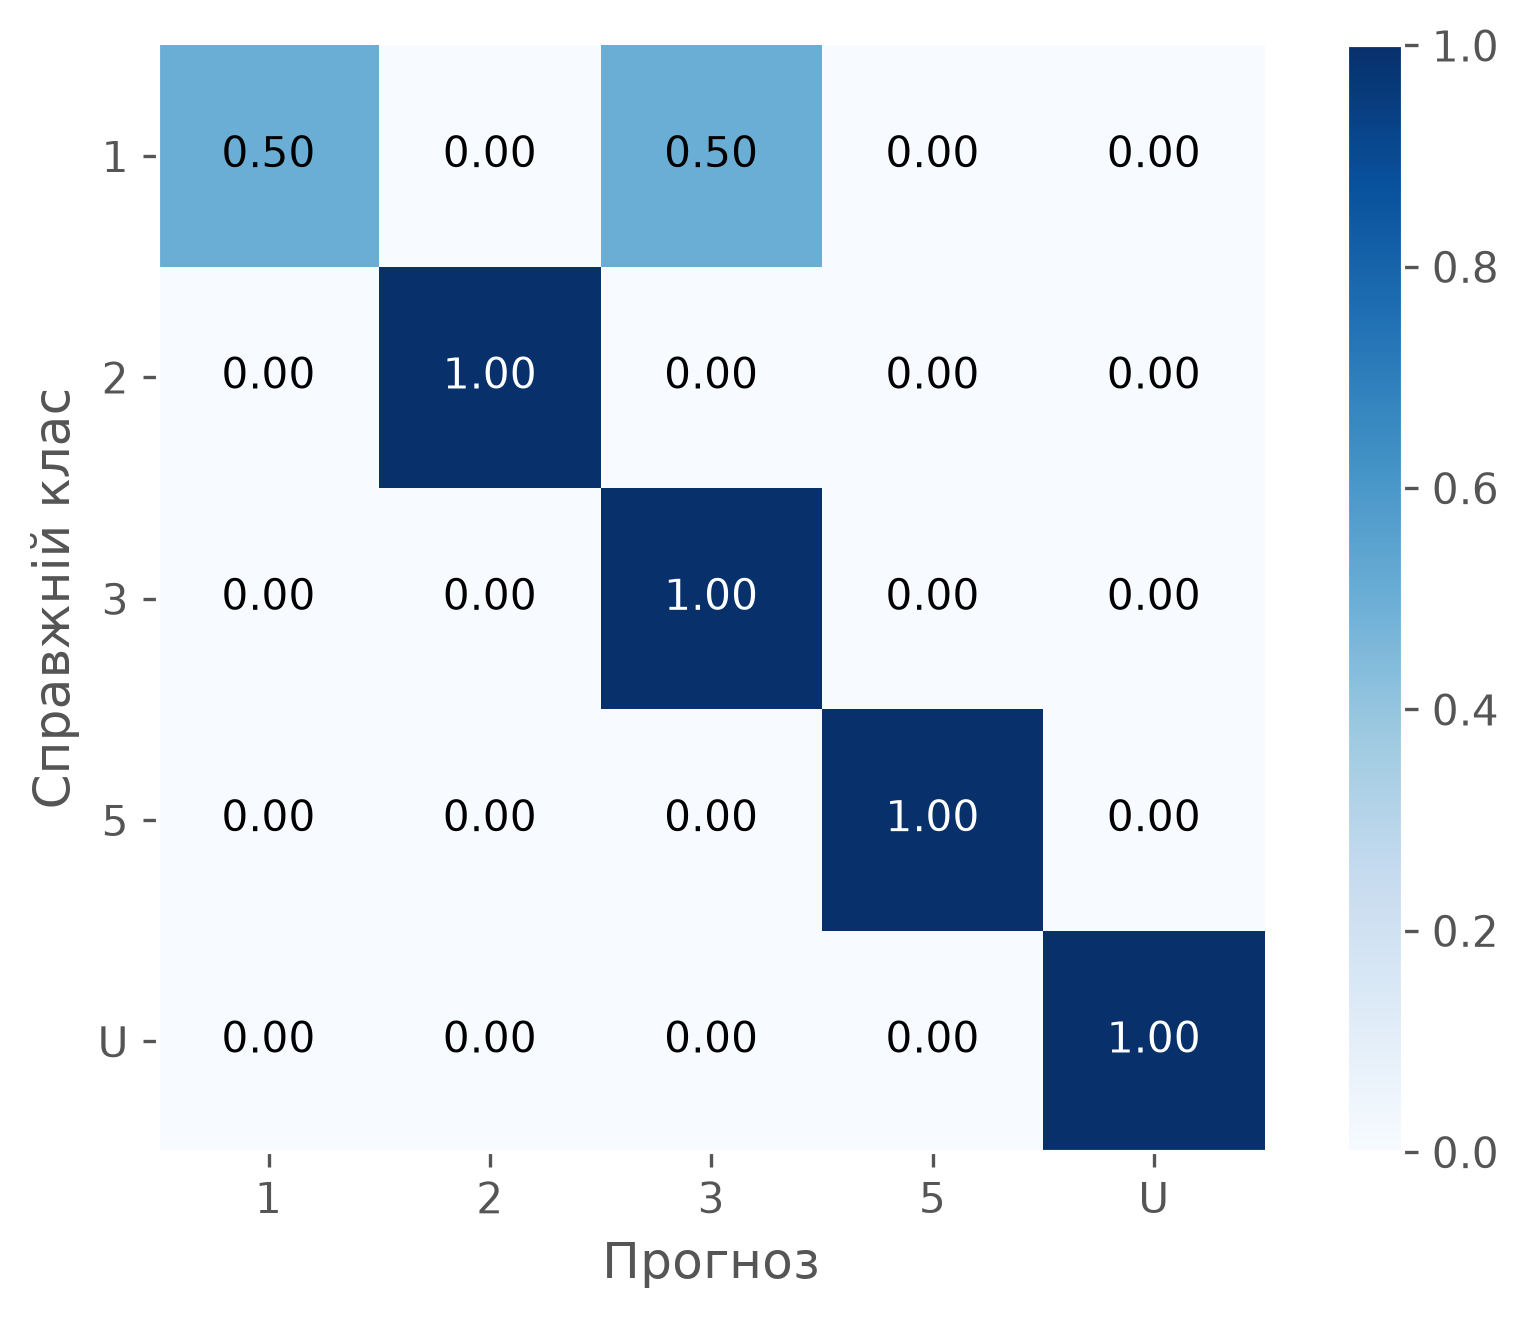

In [47]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'confusion_normalized.png')))

### Рисунок 17. Локальні SHAP-внески: DT

На рисунку 17 зображено локальні SHAP-внески: DT. Масштаб вказано на осі: ймовірність для DT/RF, логіт для XGBoost. Внески порівнюються за змістом, а не за рівністю абсолютних величин.

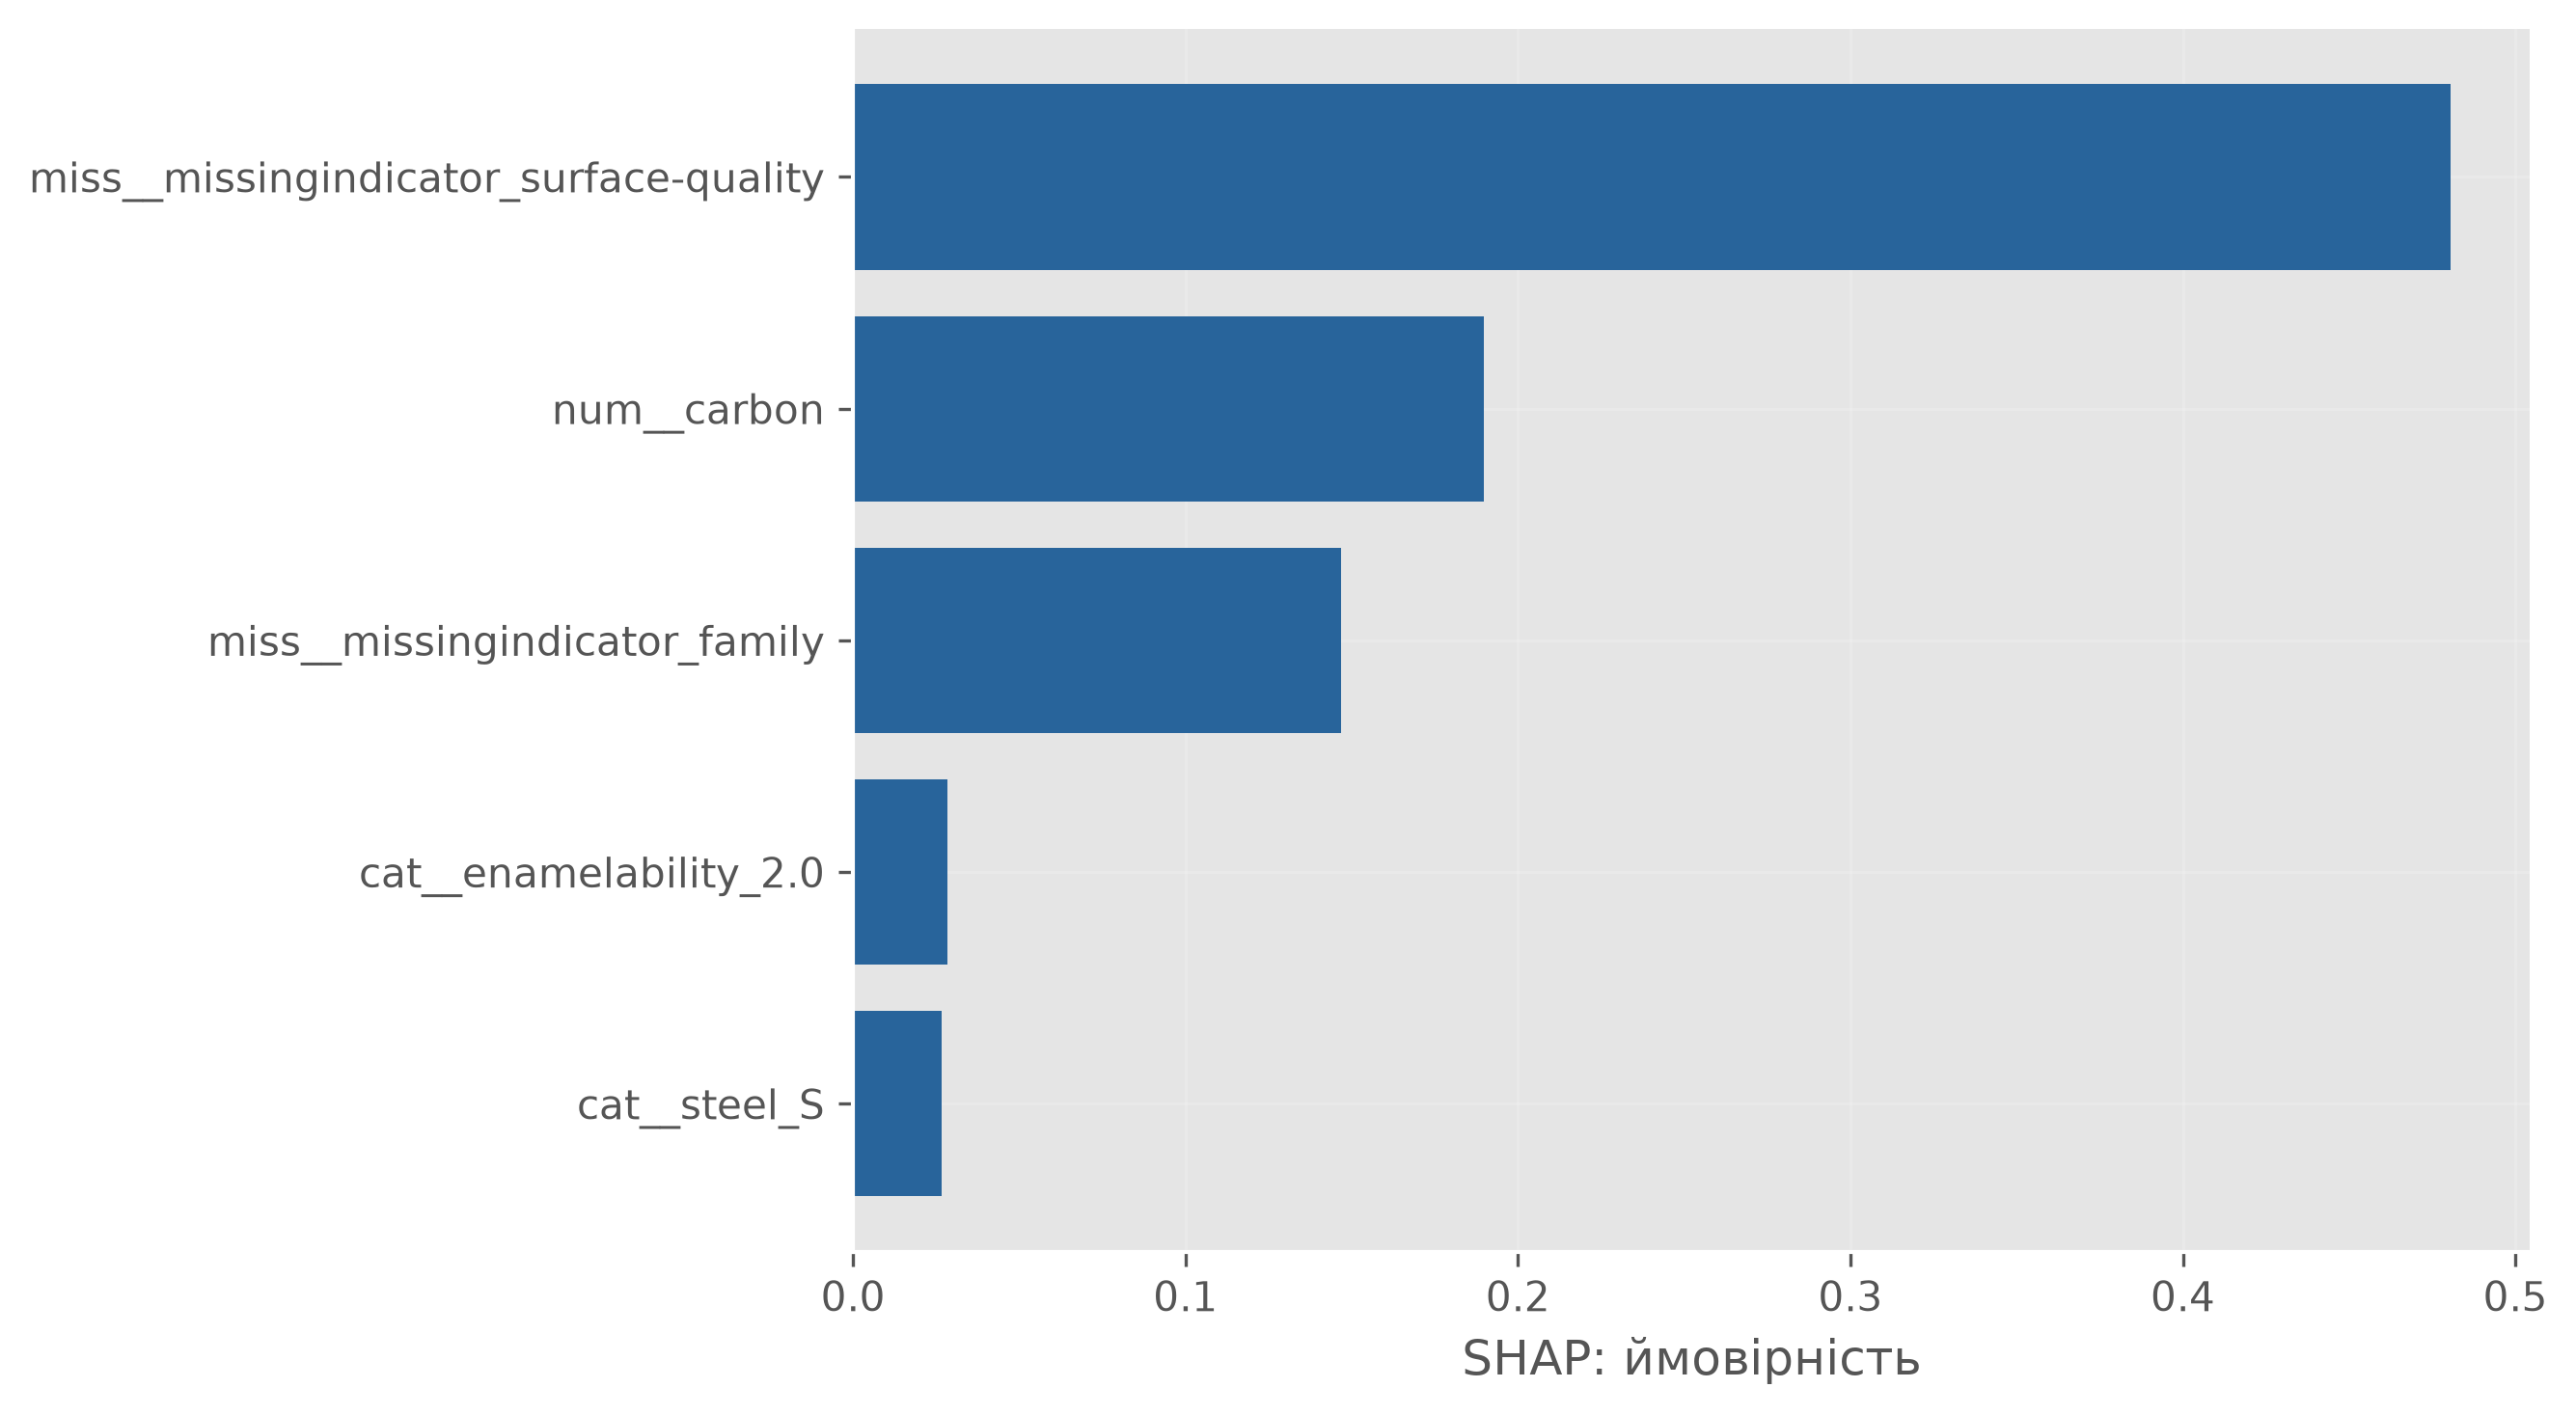

In [48]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'shap_DT.png')))

### Рисунок 18. Локальні SHAP-внески: RF

На рисунку 18 зображено локальні SHAP-внески: RF. Масштаб вказано на осі: ймовірність для DT/RF, логіт для XGBoost. Внески порівнюються за змістом, а не за рівністю абсолютних величин.

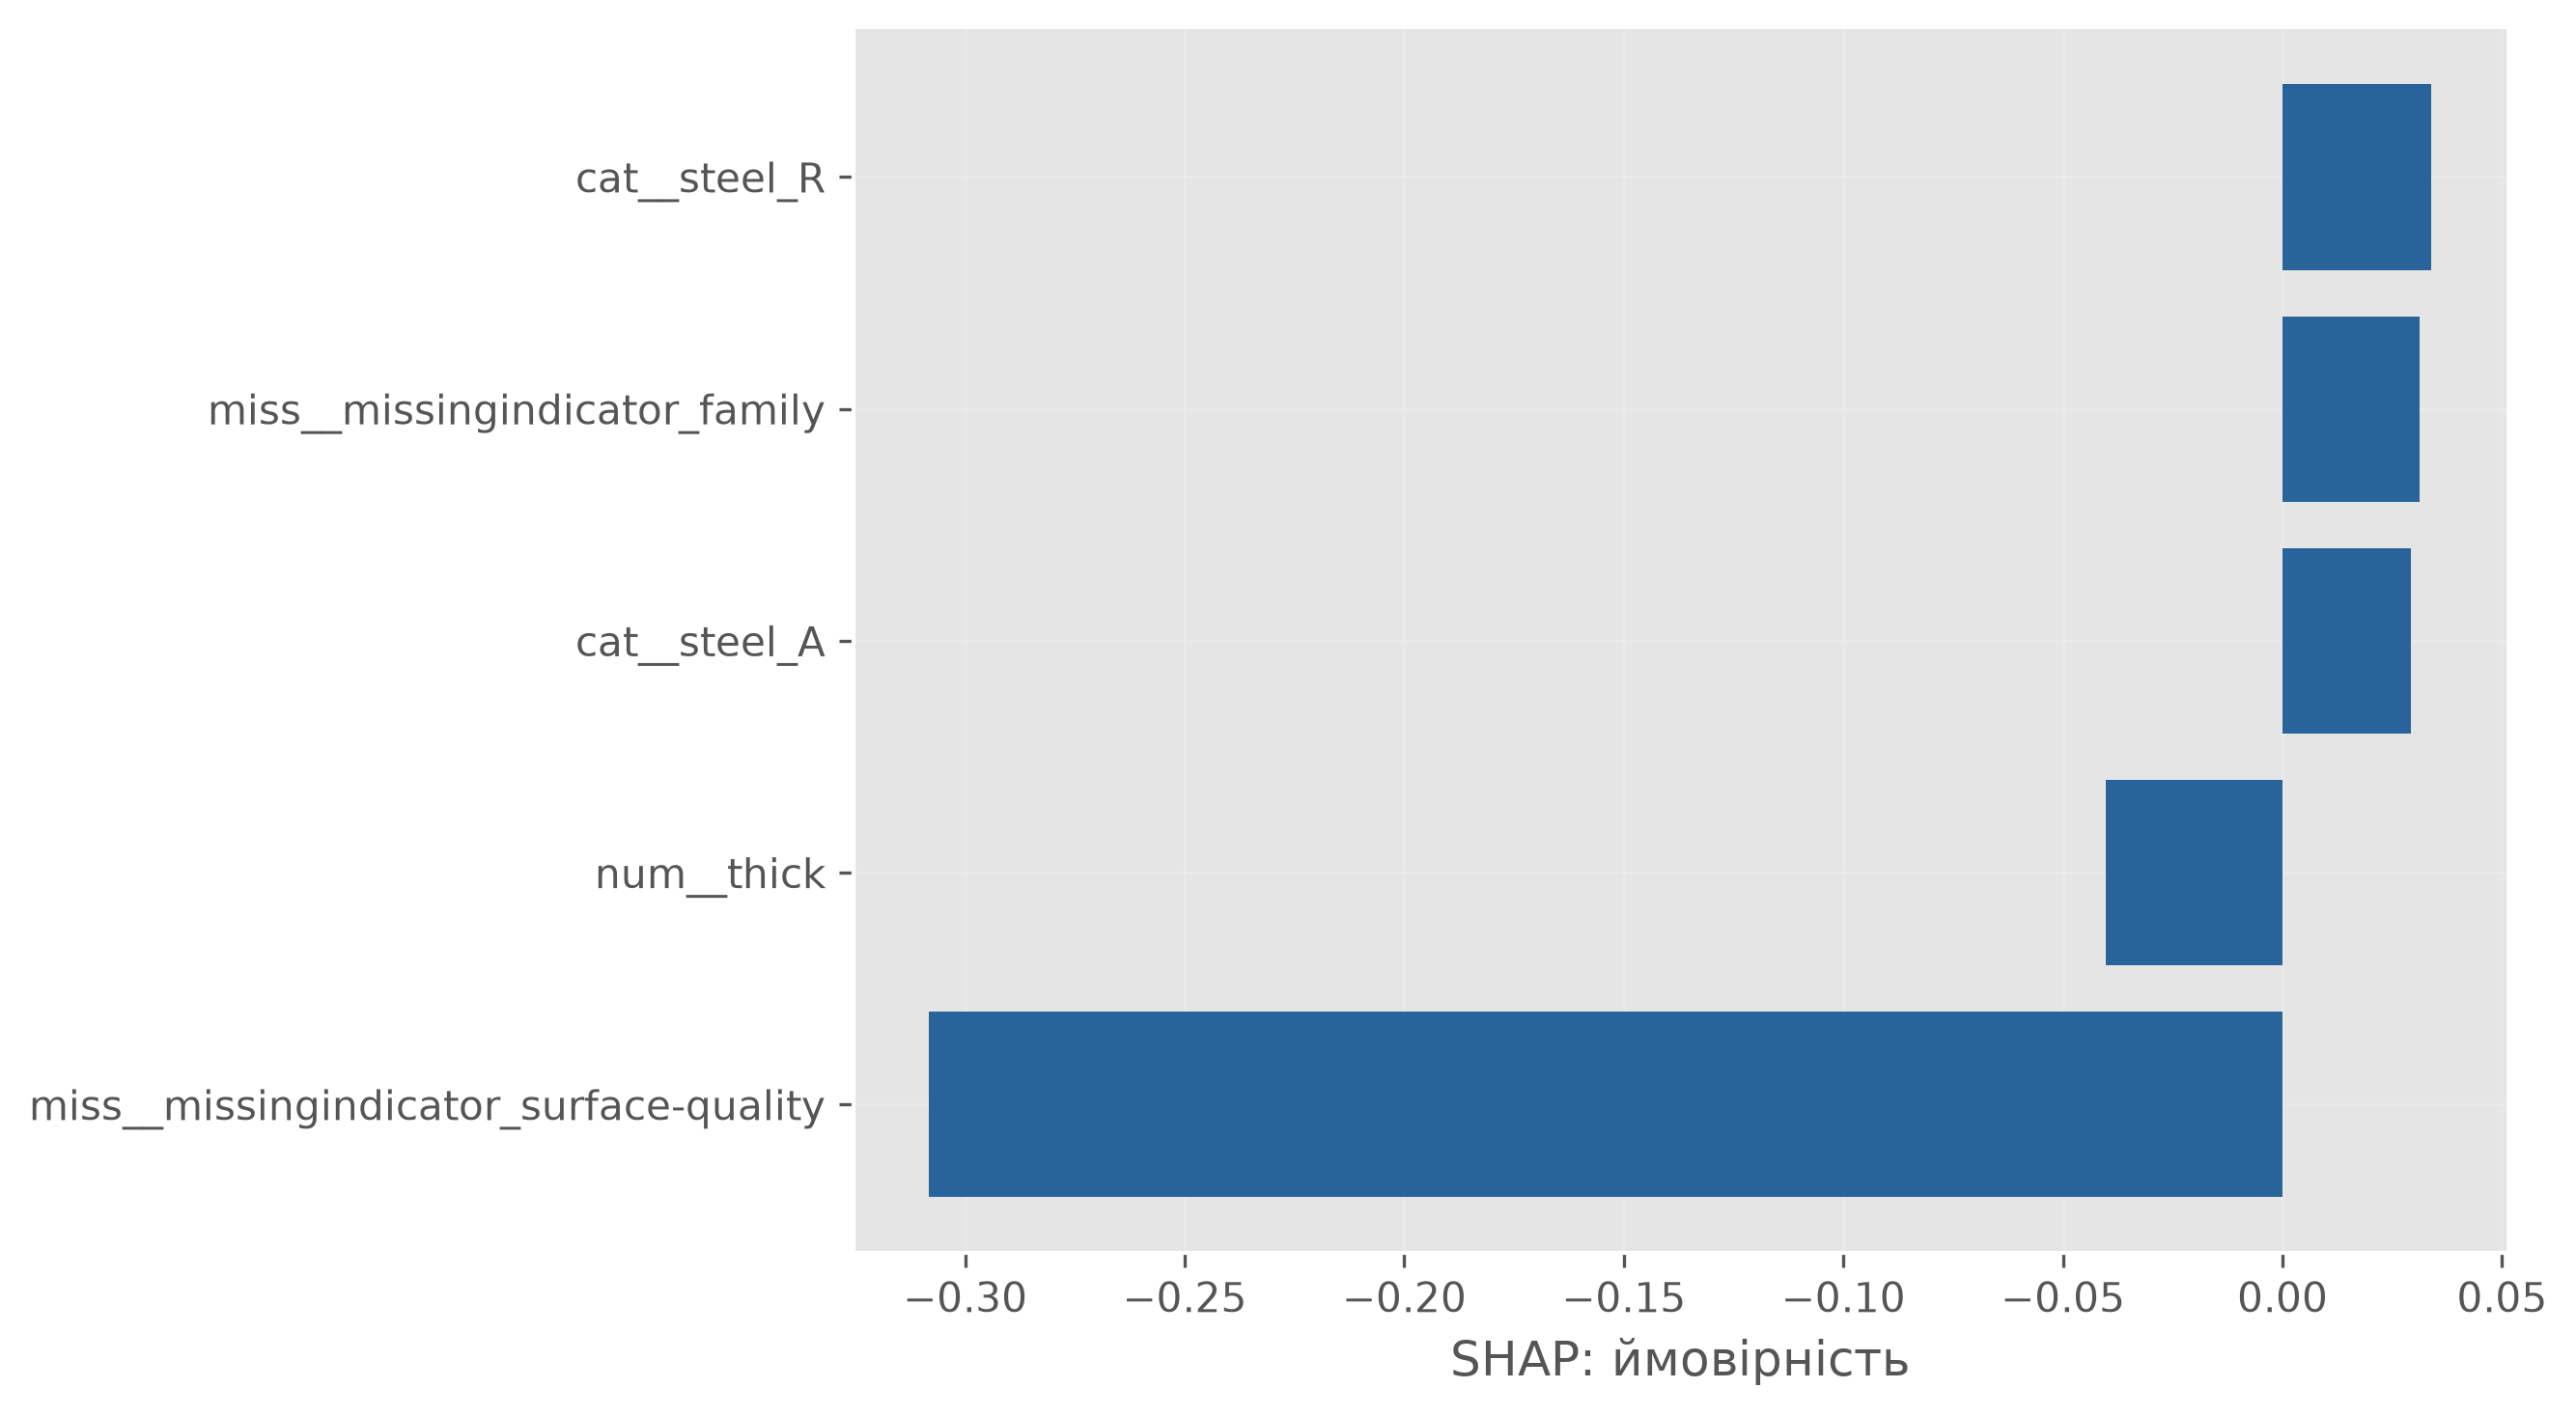

In [49]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'shap_RF.png')))

### Рисунок 19. Локальні SHAP-внески: XGB

На рисунку 19 зображено локальні SHAP-внески: XGB. Масштаб вказано на осі: ймовірність для DT/RF, логіт для XGBoost. Внески порівнюються за змістом, а не за рівністю абсолютних величин.

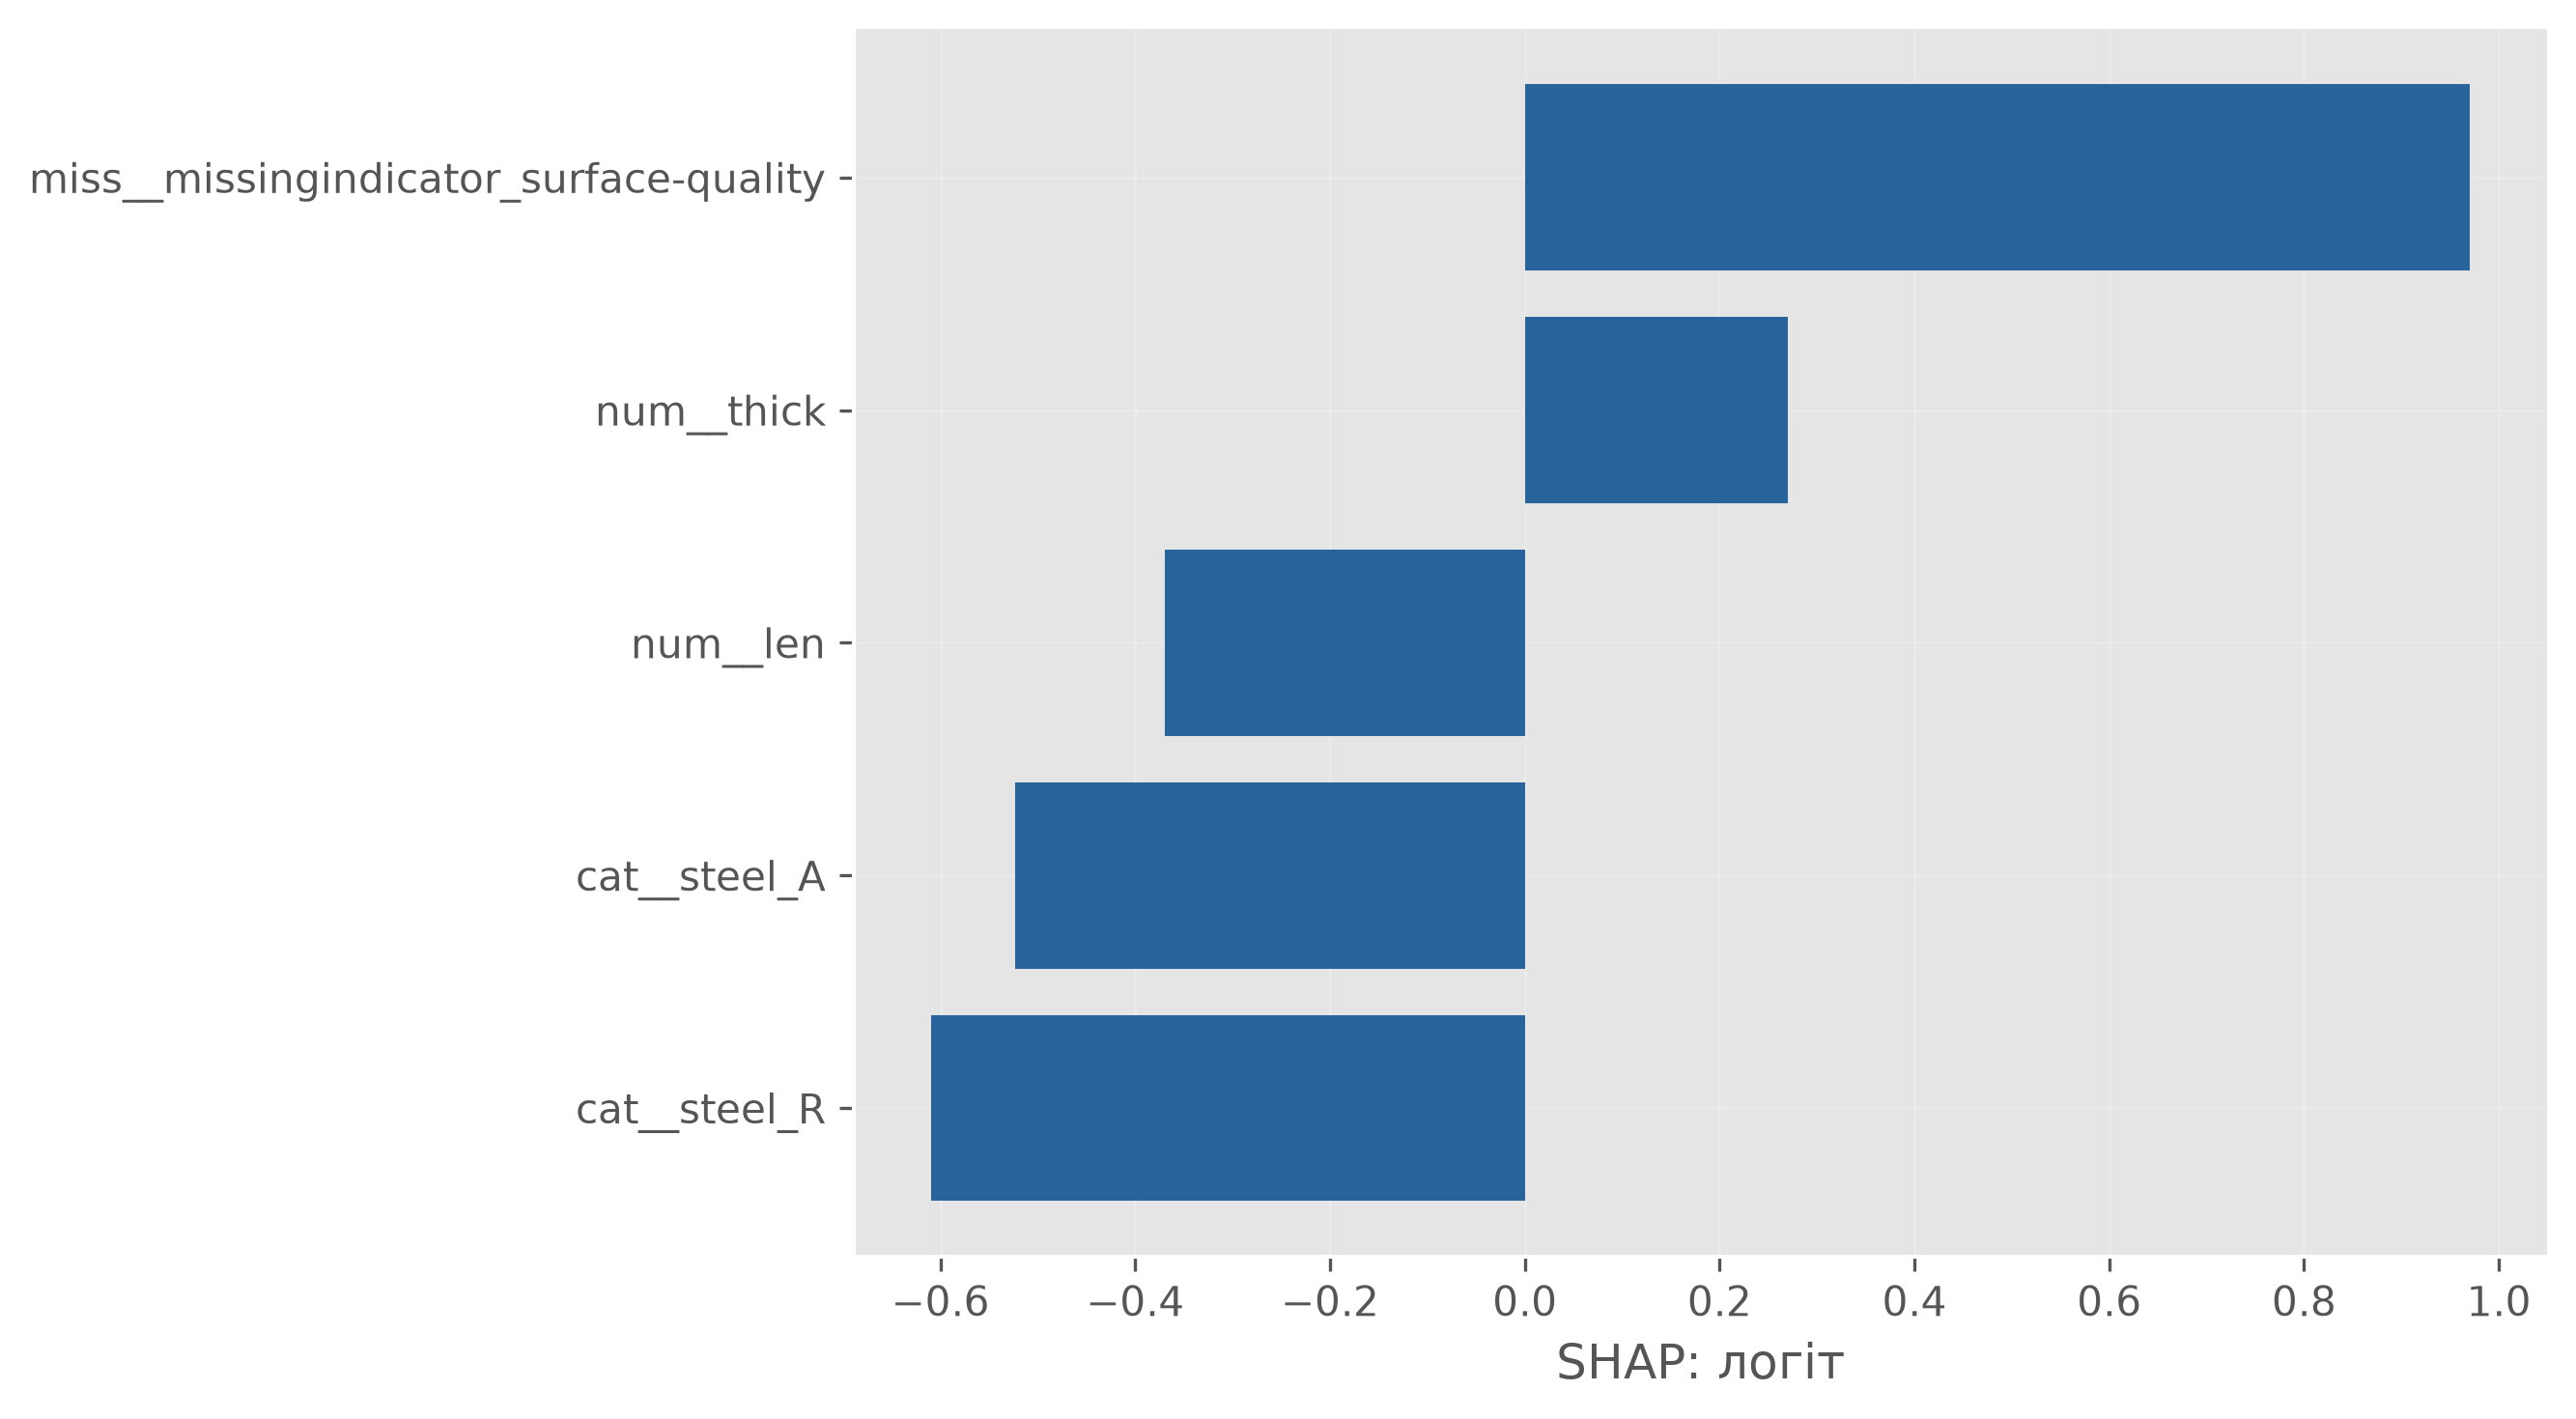

In [50]:
display(Image(filename=str(ROOT / 'lab_04' / 'results' / 'shap_XGB.png')))

## Висновки

In [51]:
for text in conclusions(4, R):
    print(text)

За зовнішньою CV вибрав RF: macro-F1=0,9732 ± 0,0332. Фінальний Test macro-F1=0,9326; він не використовувався для вибору моделі. Індикатори пропусків змінили середній baseline macro-F1 на DT: 0,0809, RF: 0,0523, XGB: 0,0558.
Скориговані парні тести дали DT A-B: p=0,074315; RF A-B: p=0,001182; XGB A-B: p=0,321976; B DT-RF: p=0,811121. Результат кожної перевірки порівнюю з α=0,05; ці p-значення не доводять універсальної переваги моделі на інших даних. Для вибраної моделі best_value=0,9660, тоді як незалежна зовнішня оцінка=0,9732.
Найбільша описова різниця між tuned outer CV та baseline B CV спостерігалася для XGB: 0,0250; це різні схеми поділів, тому така різниця не є парним тестом приросту. Найменший Test recall має клас 1: 0,5000 за support=2. У Test є 3 об’єктів розбіжності; локальні SHAP-внески перевірено за властивістю адитивності.
Для практичного використання обрав би RF як переможця за заздалегідь обраною процедурою nested CV, врахувавши її розкид і витрати навчання. Залежність п

## Джерела

Annealing. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/3/annealing

SciPy. fisher_exact, Monte Carlo method. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.fisher_exact.html